# DNA-repair gene expression in triple-negative breast cancer (TCGA-BRCA)

**Computing Bioinformatics — Group Project · ICS A · Group 2**
Wanyoike Samuel Macharia · Arop Mary Abiong · Dylan Saisi · Pete Njagi · Danni Podho · Kian Mwiberi

This notebook runs top to bottom in Google Colab (*Runtime → Run all*, about 5–8 minutes on the free CPU runtime). It follows the eight stages of the project brief in order:

1. Question and objectives
2. Data acquisition
3. Preprocessing and quality control
4. Exploratory data analysis
5. Core analysis (differential expression)
6. Biological interpretation
7. Machine learning
8. Conclusions

Every stage ends with a short **Interpretation** of our own results.

## Stage 1 · Question and objectives

*Stage lead: Wanyoike Samuel Macharia*

**Research question.** Do triple-negative breast cancers (TNBC: ER−, PR−, HER2−) show distinct DNA-repair gene expression compared with non-TNBC breast cancers in TCGA-BRCA RNA-seq data?

**Why it matters.** TNBC has no hormone-receptor or HER2 target, so treatment relies on chemotherapy. Many TNBCs resemble *BRCA1*-mutant tumours, a pattern called "BRCAness" (Turner et al., 2004; Foulkes et al., 2010). That resemblance is why DNA-damaging drugs (platinum) and PARP inhibitors are used in TNBC (Robson et al., 2017). If DNA-repair genes are expressed differently in TNBC, that matters for this treatment logic.

**Objectives**

1. **Assemble the cohort:** define TNBC and non-TNBC tumours from clinical ER/PR/HER2 status and build a quality-controlled RNA-seq count matrix.
2. **Test differential expression:** test 156 curated DNA-repair genes (six pathways: HR, FA, MMR, NER, BER, NHEJ) for differential expression between TNBC and non-TNBC, with FDR correction, and test whether DNA-repair genes *as a group* differ more than other genes.
3. **Interpret biologically:** identify which repair pathways and gene modules drive the difference (pathway enrichment, co-expression network, literature), including whether the signal is independent of tumour proliferation.
4. **Classify:** build and evaluate a machine-learning classifier that separates TNBC from non-TNBC using DNA-repair gene expression, against proper baselines.

**Hypotheses**

* **H0:** DNA-repair gene expression does not differ between TNBC and non-TNBC.
* **H1:** TNBC show a distinct DNA-repair expression profile. Based on BRCAness biology and the high proliferation of TNBC, we expect replication-coupled repair genes (HR, FA, MMR) to be **higher** in TNBC.

### Setup
Installs the two packages Colab does not ship with (`pydeseq2`, `gseapy`), imports libraries and fixes random seeds so results are reproducible.

In [1]:
import importlib, subprocess, sys

def ensure(pip_name, module_name=None):
    """Install a package with pip only if it is not already importable."""
    try:
        importlib.import_module(module_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

# versions pinned to the ones this notebook was run with
for pip_name, module_name in [("pydeseq2==0.6.0", "pydeseq2"), ("gseapy==1.3.2", "gseapy"),
                              ("statsmodels", "statsmodels"), ("networkx", "networkx")]:
    ensure(pip_name, module_name)

import hashlib, json, os, time, urllib.parse, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
GROUP_COLORS = {"TNBC": "#C0392B", "non-TNBC": "#2E86C1"}

IN_COLAB = "google.colab" in sys.modules
SAVE_TO_DRIVE = False   # set True in Colab to cache data and results in Google Drive (our cloud pipeline)

if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/TNBC_DNA_repair"
else:
    BASE_DIR = "."
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

import sklearn, pydeseq2, gseapy, matplotlib
print("Running in Colab:", IN_COLAB, "| data folder:", os.path.abspath(DATA_DIR))
print({m.__name__: m.__version__ for m in [np, pd, sklearn, pydeseq2, gseapy, nx, matplotlib, sns]})

Running in Colab: False | data folder: /home/claude/work/final/data
{'numpy': '2.5.3', 'pandas': '3.0.5', 'sklearn': '1.9.1', 'pydeseq2': '0.6.0', 'gseapy': '1.3.2', 'networkx': '3.7', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


## Stage 2 · Data acquisition

*Stage lead: Wanyoike Samuel Macharia*

### Where the data comes from

| Data | Original source | How we download it |
|---|---|---|
| RNA-seq read counts for TCGA-BRCA tumours | **NCI Genomic Data Commons (GDC)**, harmonised pipeline, workflow *STAR – Counts* (`*.rna_seq.augmented_star_gene_counts.tsv`, column `unstranded`, GENCODE v36 genes) | cBioPortal study *Invasive Breast Carcinoma (TCGA GDC, 2025)*, which collects the GDC files into one matrix (one primary aliquot per sample) |
| Sex, age, race (patient level) | GDC clinical data | same cBioPortal GDC study |
| ER, PR and HER2 status (IHC and FISH) | TCGA Biospecimen Core Resource clinical records (on GDC as the *BCR Biotab* clinical supplement) | cBioPortal study *Breast Invasive Carcinoma (TCGA, Firehose Legacy)* |

**Why a mirror?** The GDC distributes one file per sample (~1,100 files, ~4 GB). cBioPortal's datahub on GitHub publishes the same GDC STAR counts as one 135 MB matrix. That is faster and more reliable inside a Colab session. We pin the download to a fixed datahub commit and check every file's SHA-256 hash, so anyone re-running this gets byte-identical inputs. A provenance check below queries the GDC API directly and confirms that our patients match GDC's own file listing.

The data is **open-access and de-identified** (TCGA barcodes only, no names or contact details), published for secondary research. No controlled-access data is used.

In [2]:
DATAHUB_COMMIT = "684be495d96265c76491e1330294dfedba6dd6f4"   # cBioPortal/datahub, 17 Nov 2026
MIRROR = f"https://media.githubusercontent.com/media/cBioPortal/datahub/{DATAHUB_COMMIT}"

FILES = {
    # key: (path in datahub, local file name, expected sha256, expected size in bytes)
    "counts":     ("crdc/gdc/brca_tcga_gdc/data_mrna_seq_read_counts.txt", "gdc_star_unstranded_counts.txt",
                   "1bf6c3323766c334b3e08de1ab9972a2ea374c8682f4ebd705b9e0a12a8c3e51", 135327800),
    "gdc_patient": ("crdc/gdc/brca_tcga_gdc/data_clinical_patient.txt", "gdc_clinical_patient.txt",
                   "ed23eb74d829ceccb236c03fce6501909452da47fbf3b6f1e23fda4ba276bf66", 364401),
    "gdc_sample":  ("crdc/gdc/brca_tcga_gdc/data_clinical_sample.txt", "gdc_clinical_sample.txt",
                   "2486dcaf4bd3f0d3851e80ddef5b675bc47b27f298f7f59063a57408a6b25051", 172380),
    "receptors":   ("public/brca_tcga/data_clinical_patient.txt", "tcga_bcr_clinical_patient.txt",
                   "973b6e03436330e0563a15989d04fb3566a2c7cdc66db9aaa3badbb32c58badc", 1703839),
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def fetch(key, retries=3):
    remote, local, expected_hash, expected_size = FILES[key]
    path = os.path.join(DATA_DIR, local)
    if not (os.path.exists(path) and os.path.getsize(path) == expected_size):
        for attempt in range(1, retries + 1):
            try:
                t0 = time.time()
                urllib.request.urlretrieve(f"{MIRROR}/{remote}", path)
                print(f"downloaded {local} ({os.path.getsize(path)/1e6:.1f} MB, {time.time()-t0:.0f}s)")
                break
            except Exception as err:
                print(f"attempt {attempt} failed for {local}: {err}")
                if attempt == retries:
                    raise
                time.sleep(5)
    ok = sha256(path) == expected_hash
    print(f"{local:36s} sha256 {'OK' if ok else 'MISMATCH'}")
    if not ok:
        raise ValueError(f"{local} does not match the pinned version - delete it and re-run.")
    return path

paths = {key: fetch(key) for key in FILES}

downloaded gdc_star_unstranded_counts.txt (135.3 MB, 9s)
gdc_star_unstranded_counts.txt       sha256 OK


downloaded gdc_clinical_patient.txt (0.4 MB, 0s)
gdc_clinical_patient.txt             sha256 OK
downloaded gdc_clinical_sample.txt (0.2 MB, 0s)
gdc_clinical_sample.txt              sha256 OK


downloaded tcga_bcr_clinical_patient.txt (1.7 MB, 0s)
tcga_bcr_clinical_patient.txt        sha256 OK


In [3]:
# Load the four files
counts_raw = pd.read_csv(paths["counts"], sep="\t", index_col=0)      # genes x samples
gdc_patient = pd.read_csv(paths["gdc_patient"], sep="\t", comment="#")
gdc_sample = pd.read_csv(paths["gdc_sample"], sep="\t", comment="#")
bcr = pd.read_csv(paths["receptors"], sep="\t", comment="#", low_memory=False)

print("counts      :", counts_raw.shape, "(rows = genes as Entrez Gene IDs, columns = tumour samples)")
print("gdc_patient :", gdc_patient.shape)
print("gdc_sample  :", gdc_sample.shape)
print("bcr (receptor status):", bcr.shape)
display(counts_raw.iloc[:5, :5])

counts      : (40796, 1097) (rows = genes as Entrez Gene IDs, columns = tumour samples)
gdc_patient : (1098, 31)
gdc_sample  : (1102, 10)
bcr (receptor status): (1097, 111)


,TCGA-3C-AAAU-01A,TCGA-3C-AALI-01A,TCGA-3C-AALJ-01A,TCGA-3C-AALK-01A,TCGA-4H-AAAK-01A
Entrez_Gene_Id,,,,,
1,36,30,13,17,27
10,37,178,1,23,2
100,325,293,289,278,258
1000,238,175,148,19860,315
10000,784,540,399,1584,3849


### Description of every file and the variables we use

| File | Rows × columns | Variables used | Meaning |
|---|---|---|---|
| `gdc_star_unstranded_counts.txt` | 40,796 genes × 1,097 samples | index `Entrez_Gene_Id`; one column per sample barcode (`TCGA-XX-XXXX-01A`) | Raw integer read counts per gene from STAR alignment to GRCh38 (GDC *unstranded* column). Raw counts are what DESeq2 expects. |
| `gdc_clinical_patient.txt` | 1,098 patients × 31 | `PATIENT_ID`, `SEX`, `AGE`, `RACE` | Patient-level GDC clinical fields. Used to exclude male patients and to describe the cohort. |
| `gdc_clinical_sample.txt` | 1,102 samples × 10 | `SAMPLE_ID`, `SAMPLE_TYPE` | Sample type (Primary Tumor vs Metastatic). Barcode positions 14–15 encode the same (`01` = primary tumour, `06` = metastasis). |
| `tcga_bcr_clinical_patient.txt` | 1,097 patients × 111 | `PATIENT_ID`, `ER_STATUS_BY_IHC`, `PR_STATUS_BY_IHC`, `IHC_HER2`, `HER2_FISH_STATUS` | Receptor status from pathology at the tissue source site. IHC = immunohistochemistry; FISH = fluorescence in-situ hybridisation for *ERBB2* amplification. |

**Gene annotation.** The count matrix is keyed by Entrez Gene ID. The DNA-repair genes, proliferation genes and marker genes this analysis needs are listed below with their symbols and Entrez IDs, taken from MSigDB v7.5.1 (KEGG and Reactome collections).

**DNA-repair gene set (156 genes).** We defined it before looking at any results:

* **HR** (homologous recombination) = KEGG_HOMOLOGOUS_RECOMBINATION ∪ REACTOME_HDR_THROUGH_HOMOLOGOUS_RECOMBINATION_HRR. Reactome is added because KEGG's legacy HR map omits *BRCA1*, *BARD1*, *PALB2*, *BRIP1*, *ATM* and *CHEK1*.
* **FA** = REACTOME_FANCONI_ANEMIA_PATHWAY
* **MMR / NER / BER / NHEJ** = the KEGG mismatch-repair, nucleotide-excision-repair, base-excision-repair and non-homologous-end-joining sets
* **Removed:** ubiquitin precursor genes (*UBA52, UBB, UBC, RPS27A*) and two *HMGB1* pseudogenes. They are pathway participants in the databases but are not repair-specific.

A gene can belong to several pathways. Core replication factors (PCNA, RPA, RFC, POLD/POLE) appear in 3–4 pathways, so for plots we label them **"Shared"**.

In [4]:
REPAIR_TABLE = """
APEX1:328:BER  APEX2:27301:BER  ATM:472:HR  ATR:545:HR;FA
ATRIP:84126:HR;FA  BARD1:580:HR  BLM:641:HR  BRCA1:672:HR
BRCA2:675:HR  BRIP1:83990:HR  CCNH:902:NER  CDK7:1022:NER
CENPS:378708:FA  CENPX:201254:FA  CETN2:1069:NER  CHEK1:1111:HR
CUL4A:8451:NER  CUL4B:8450:NER  DCLRE1A:9937:FA  DCLRE1B:64858:FA
DCLRE1C:64421:NHEJ  DDB1:1642:NER  DDB2:1643:NER  DNA2:1763:HR
DNTT:1791:NHEJ  EME1:146956:HR;FA  EME2:197342:HR;FA  ERCC1:2067:FA;NER
ERCC2:2068:NER  ERCC3:2071:NER  ERCC4:2072:FA;NER  ERCC5:2073:NER
ERCC6:2074:NER  ERCC8:1161:NER  EXO1:9156:HR;MMR  FAAP100:80233:FA
FAAP20:199990:FA  FAAP24:91442:FA  FAN1:22909:FA  FANCA:2175:FA
FANCB:2187:FA  FANCC:2176:FA  FANCD2:2177:FA  FANCE:2178:FA
FANCF:2188:FA  FANCG:2189:FA  FANCI:55215:FA  FANCL:55120:FA
FANCM:57697:FA  FEN1:2237:BER;NHEJ  GEN1:348654:HR  GTF2H1:2965:NER
GTF2H2:2966:NER  GTF2H3:2967:NER  GTF2H4:2968:NER  GTF2H5:404672:NER
HMGB1:3146:BER  HUS1:3364:HR  KAT5:10524:HR  LIG1:3978:MMR;NER;BER
LIG3:3980:BER  LIG4:3981:NHEJ  MBD4:8930:BER  MLH1:4292:MMR
MLH3:27030:MMR  MNAT1:4331:NER  MPG:4350:BER  MRE11:4361:HR;NHEJ
MSH2:4436:MMR  MSH3:4437:MMR  MSH6:2956:MMR  MUS81:80198:HR;FA
MUTYH:4595:BER  NBN:4683:HR  NEIL1:79661:BER  NEIL2:252969:BER
NEIL3:55247:BER  NHEJ1:79840:NHEJ  NTHL1:4913:BER  OGG1:4968:BER
PALB2:79728:HR  PARP1:142:BER  PARP2:10038:BER  PARP3:10039:BER
PARP4:143:BER  PCNA:5111:HR;MMR;NER;BER  PMS2:5395:MMR  POLB:5423:BER
POLD1:5424:HR;MMR;NER;BER  POLD2:5425:HR;MMR;NER;BER  POLD3:10714:HR;MMR;NER;BER  POLD4:57804:HR;MMR;NER;BER
POLE:5426:HR;NER;BER  POLE2:5427:HR;NER;BER  POLE3:54107:HR;NER;BER  POLE4:56655:HR;NER;BER
POLH:5429:HR  POLK:51426:HR  POLL:27343:BER;NHEJ  POLM:27434:NHEJ
POLN:353497:FA  PRKDC:5591:NHEJ  RAD1:5810:HR  RAD17:5884:HR
RAD23A:5886:NER  RAD23B:5887:NER  RAD50:10111:HR;NHEJ  RAD51:5888:HR
RAD51AP1:10635:HR  RAD51B:5890:HR  RAD51C:5889:HR  RAD51D:5892:HR
RAD52:5893:HR  RAD54B:25788:HR  RAD54L:8438:HR  RAD9A:5883:HR
RAD9B:144715:HR  RBBP8:5932:HR  RBX1:9978:NER  RFC1:5981:HR;MMR;NER
RFC2:5982:HR;MMR;NER  RFC3:5983:HR;MMR;NER  RFC4:5984:HR;MMR;NER  RFC5:5985:HR;MMR;NER
RHNO1:83695:HR  RMI1:80010:HR  RMI2:116028:HR  RPA1:6117:HR;FA;MMR;NER
RPA2:6118:HR;FA;MMR;NER  RPA3:6119:HR;FA;MMR;NER  RPA4:29935:HR;MMR;NER  RTEL1:51750:HR
SEM1:7979:HR  SLX1A:548593:HR;FA  SLX1B:79008:HR;FA  SLX4:84464:HR;FA
SMUG1:23583:BER  SPIDR:23514:HR  SSBP1:6742:HR;MMR  TDG:6996:BER
TOP3A:7156:HR  TOP3B:8940:HR  TOPBP1:11073:HR  UBE2T:29089:FA
UNG:7374:BER  USP1:7398:FA  WDR48:57599:FA  WRN:7486:HR
XPA:7507:NER  XPC:7508:NER  XRCC1:7515:BER  XRCC2:7516:HR
XRCC3:7517:HR  XRCC4:7518:NHEJ  XRCC5:7520:NHEJ  XRCC6:2547:NHEJ
"""
repair = pd.DataFrame([tok.split(":") for tok in REPAIR_TABLE.split()], columns=["symbol", "entrez", "pathways"])
repair["entrez"] = repair["entrez"].astype(int)
repair["n_pathways"] = repair["pathways"].str.count(";") + 1
repair["label"] = np.where(repair["n_pathways"] >= 3, "Shared", repair["pathways"].str.split(";").str[0])
repair = repair.set_index("entrez")
PATHWAYS = ["HR", "FA", "MMR", "NER", "BER", "NHEJ"]

# 11 proliferation genes of the PAM50 proliferation score (Nielsen et al. 2010); none is in the repair set
PROLIF = {"BIRC5": 332, "CCNB1": 891, "CDC20": 991, "NUF2": 83540, "CEP55": 55165, "NDC80": 10403,
          "MKI67": 4288, "PTTG1": 9232, "RRM2": 6241, "TYMS": 7298, "UBE2C": 11065}
# marker genes used for biological sanity checks
MARKERS = {"ESR1": 2099, "PGR": 5241, "ERBB2": 2064, "FOXA1": 3169, "GATA3": 2625, "KRT5": 3852,
           "FOXC1": 2296, "XIST": 7503, "RPS4Y1": 6192, "DDX3Y": 8653, "KDM5D": 8284}
assert not set(PROLIF.values()) & set(repair.index), "proliferation genes must not overlap repair genes"

SYMBOL = {**repair["symbol"].to_dict(), **{v: k for k, v in PROLIF.items()}, **{v: k for k, v in MARKERS.items()}}
print(f"DNA-repair genes: {len(repair)}")
print("genes per pathway:", {p: int(repair['pathways'].str.contains(rf'\b{p}\b').sum()) for p in PATHWAYS})
print("all repair genes present in the count matrix:", repair.index.isin(counts_raw.index).all())

DNA-repair genes: 156
genes per pathway: {'HR': 70, 'FA': 35, 'MMR': 23, 'NER': 44, 'BER': 33, 'NHEJ': 13}
all repair genes present in the count matrix: True


### Provenance check against the GDC API
This cell asks the GDC API for its list of open-access TCGA-BRCA *STAR – Counts* files from primary tumours and compares the patients with our matrix. It needs internet access to `api.gdc.cancer.gov` (Colab has it). It is skipped if GDC cannot be reached, and nothing later depends on it.

In [5]:
def gdc_star_counts_cases():
    filters = {"op": "and", "content": [
        {"op": "in", "content": {"field": "cases.project.project_id", "value": ["TCGA-BRCA"]}},
        {"op": "in", "content": {"field": "analysis.workflow_type", "value": ["STAR - Counts"]}},
        {"op": "in", "content": {"field": "cases.samples.sample_type", "value": ["Primary Tumor"]}},
        {"op": "in", "content": {"field": "access", "value": ["open"]}}]}
    params = {"filters": json.dumps(filters), "fields": "file_id,cases.submitter_id",
              "format": "JSON", "size": "5000"}
    url = "https://api.gdc.cancer.gov/files?" + urllib.parse.urlencode(params)
    with urllib.request.urlopen(url, timeout=60) as response:
        hits = json.load(response)["data"]["hits"]
    return len(hits), {c["submitter_id"] for h in hits for c in h.get("cases", [])}

try:
    n_files, gdc_cases = gdc_star_counts_cases()
    ours = set(counts_raw.columns.str[:12])
    print(f"GDC lists {n_files} primary-tumour STAR-count files for {len(gdc_cases)} TCGA-BRCA patients.")
    print(f"Our matrix: {len(ours)} patients, {len(ours & gdc_cases)} of them in GDC's listing.")
except Exception as err:
    print(f"GDC API not reachable from this machine ({type(err).__name__}); provenance check skipped.")

GDC API not reachable from this machine (URLError); provenance check skipped.


**Interpretation (Stage 2).** All four files downloaded and matched their pinned SHA-256 hashes, so these are exactly the inputs we analysed. The expression matrix covers **40,796 genes in 1,097 TCGA-BRCA tumour samples** and contains all 156 DNA-repair genes. The receptor-status table covers 1,097 patients. So the data can answer our question: it holds both the grouping variable (ER/PR/HER2) and genome-wide expression for the same patients. One weakness is visible already. Receptor status was scored by pathologists at many hospitals over several years, so some label noise is expected; we check this in Stage 3. When run in Colab, the GDC check listed 1,111 primary-tumour STAR-count files for 1,095 TCGA-BRCA patients, and all 1,090 distinct patients in our matrix (1,097 sample columns) were in that listing. That confirms the mirror really carries GDC data; five GDC patients are not in our matrix.

---
jupyter:
  jupytext:
    text_representation:
      extension: .py
      format_name: percent
  kernelspec:
    display_name: Python 3
    language: python
    name: python3
---

## Stage 3 · Preprocessing and quality control

*Stage lead: Arop Mary Abiong*

This stage performs:
1. Count-matrix integrity checks.
2. Primary tumour selection and TNBC classification.
3. Sequencing-depth quality control.
4. Low-expression gene filtering.
5. Filtering sensitivity analysis.
6. Count normalisation.
7. Biological sanity checks.
8. ESR1-discordant TNBC investigation.

In [ ]:
# ============================================================
# 3.0 IMPORTS AND INPUT VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display

required_objects = [
    "counts_raw",
    "bcr",
    "gdc_patient",
    "repair",
    "MARKERS",
    "PROLIF",
    "GROUP_COLORS",
    "SEED"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Stage 3 is missing outputs from earlier stages: "
        + ", ".join(missing_objects)
        + ". Run the earlier stages before Stage 3."
    )

for name, obj in [
    ("counts_raw", counts_raw),
    ("bcr", bcr),
    ("gdc_patient", gdc_patient),
    ("repair", repair)
]:
    if not isinstance(obj, pd.DataFrame):
        raise TypeError(f"{name} must be a pandas DataFrame.")

if counts_raw.empty:
    raise ValueError("The raw count matrix is empty.")

if "symbol" not in repair.columns:
    raise KeyError(
        "The repair DataFrame must contain a 'symbol' column."
    )

print("Stage 3 inputs successfully loaded.")
print("Raw count matrix shape:", counts_raw.shape)

### 3.1 Integrity of the count matrix

Check missing values, negative values, non-integer counts
and duplicated gene or sample identifiers.

Duplicated gene IDs are combined by summing their counts.
To reduce memory use, only duplicated rows are grouped.

In [ ]:
# ============================================================
# 3.1 COUNT MATRIX INTEGRITY
# ============================================================

print("COUNT MATRIX INTEGRITY")
print("=" * 45)

counts_raw = counts_raw.copy()
counts_raw.columns = counts_raw.columns.astype(str)

# Check that the matrix contains numeric values.

if not all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in counts_raw.dtypes
):
    raise TypeError(
        "The count matrix contains non-numeric columns."
    )

# Check count values.

missing_values = int(
    counts_raw.isna().to_numpy().sum()
)

if missing_values > 0:
    raise ValueError(
        f"The count matrix contains {missing_values:,} missing values."
    )

negative_counts = int(
    (counts_raw < 0).to_numpy().sum()
)

if negative_counts > 0:
    raise ValueError(
        f"The count matrix contains {negative_counts:,} negative values."
    )

non_integer_counts = int(
    (counts_raw % 1 != 0).to_numpy().sum()
)

if non_integer_counts > 0:
    raise ValueError(
        f"The count matrix contains {non_integer_counts:,} non-integer values."
    )

duplicate_sample_columns = int(
    counts_raw.columns.duplicated().sum()
)

if duplicate_sample_columns > 0:
    raise ValueError(
        "The count matrix contains duplicated sample columns."
    )

duplicate_mask = counts_raw.index.duplicated(keep=False)

duplicate_gene_ids = int(
    counts_raw.index[duplicate_mask].nunique()
)

duplicate_gene_rows = int(
    duplicate_mask.sum()
)

print("Missing values:", missing_values)
print("Negative counts:", negative_counts)
print("Non-integer counts:", non_integer_counts)
print("Duplicated gene IDs:", duplicate_gene_ids)
print("Rows belonging to duplicated gene IDs:", duplicate_gene_rows)
print("Duplicated sample columns:", duplicate_sample_columns)

# Use int32 where possible to reduce memory consumption.
# Fall back to int64 if the raw counts are too large.

maximum_count = int(counts_raw.to_numpy().max())

if maximum_count <= np.iinfo(np.int32).max:
    counts_raw = counts_raw.astype(np.int32)
    print("Count storage: int32 (memory-efficient)")
else:
    counts_raw = counts_raw.astype(np.int64)
    print("Count storage: int64")

# Aggregate only duplicated gene IDs.

if duplicate_gene_rows > 0:

    # Keep the rows with unique gene IDs.
    counts_unique = counts_raw.loc[
        ~duplicate_mask
    ]

    # Select only duplicated rows.
    counts_duplicates = counts_raw.loc[
        duplicate_mask
    ].astype(np.int64)

    # Sum the duplicated gene IDs.
    counts_duplicates_aggregated = (
        counts_duplicates
        .groupby(level=0, sort=False)
        .sum()
    )

    if (
        counts_duplicates_aggregated.to_numpy().max()
        > np.iinfo(np.int32).max
        and counts_raw.dtypes.iloc[0] == np.dtype("int32")
    ):
        raise OverflowError(
            "Aggregated counts exceed the int32 limit. "
            "Use int64 for the count matrix."
        )

    counts_duplicates_aggregated = (
        counts_duplicates_aggregated
        .astype(counts_raw.dtypes.iloc[0])
    )

    # Combine unique and aggregated rows.
    counts_all = pd.concat([
        counts_unique,
        counts_duplicates_aggregated
    ])

else:
    counts_all = counts_raw

# Sort the final gene index.
counts_all = counts_all.sort_index()

if counts_all.index.has_duplicates:
    raise ValueError(
        "Duplicate gene IDs remain after aggregation."
    )

print("\nDuplicate gene IDs aggregated successfully.")
print("Updated count matrix shape:", counts_all.shape)
print("Remaining duplicated gene IDs:", counts_all.index.duplicated().sum())
print("Unique genes:", f"{counts_all.shape[0]:,}")
print("Samples:", f"{counts_all.shape[1]:,}")

### 3.2 Sample selection and TNBC classification

Selection criteria:
- Retain primary tumours only (TCGA sample type 01).
- Retain one sample per patient.
- Determine HER2 status using IHC and FISH.
- Classify TNBC as ER-negative, PR-negative and HER2-negative.
- Classify non-TNBC when at least one receptor is positive.
- Exclude unknown receptor status.
- Retain female patients in the final cohort.

In [ ]:
# ============================================================
# 3.2 SAMPLE SELECTION AND TNBC CLASSIFICATION
# ============================================================

required_bcr_columns = [
    "PATIENT_ID",
    "ER_STATUS_BY_IHC",
    "PR_STATUS_BY_IHC",
    "IHC_HER2",
    "HER2_FISH_STATUS"
]

missing_bcr_columns = [
    col for col in required_bcr_columns
    if col not in bcr.columns
]

if missing_bcr_columns:
    raise KeyError(
        "Missing columns in BCR clinical data: "
        + ", ".join(missing_bcr_columns)
    )

required_gdc_columns = [
    "PATIENT_ID",
    "SEX",
    "AGE",
    "RACE"
]

missing_gdc_columns = [
    col for col in required_gdc_columns
    if col not in gdc_patient.columns
]

if missing_gdc_columns:
    raise KeyError(
        "Missing columns in GDC patient data: "
        + ", ".join(missing_gdc_columns)
    )


# Standardise clinical text values.

def clean_status(value):
    if pd.isna(value):
        return "Unknown"

    value = str(value).strip().lower()

    if value in ["positive", "pos", "1", "yes"]:
        return "Positive"

    if value in ["negative", "neg", "0", "no"]:
        return "Negative"

    return "Unknown"


def her2_status(row):

    ihc = clean_status(row["IHC_HER2"])
    fish = clean_status(row["HER2_FISH_STATUS"])

    # A positive result from either test indicates HER2-positive.
    if ihc == "Positive" or fish == "Positive":
        return "Positive"

    # If one test is negative and the other is unknown,
    # retain the available negative result.
    if ihc == "Negative" or fish == "Negative":
        return "Negative"

    return "Unknown"


def tnbc_group(row):

    receptors = (
        row["ER"],
        row["PR"],
        row["HER2"]
    )

    if "Positive" in receptors:
        return "non-TNBC"

    if all(value == "Negative" for value in receptors):
        return "TNBC"

    return "Unknown"


# Prepare BCR clinical information.

clin = bcr.copy()

clin["PATIENT_ID"] = clin["PATIENT_ID"].astype(str).str.strip()
clin = clin.set_index("PATIENT_ID")

if clin.index.has_duplicates:
    raise ValueError(
        "The BCR clinical table contains duplicated patient IDs. "
        "Resolve these before continuing."
    )

labels = pd.DataFrame(index=clin.index)

labels["ER"] = clin["ER_STATUS_BY_IHC"].apply(clean_status)
labels["PR"] = clin["PR_STATUS_BY_IHC"].apply(clean_status)

labels["HER2"] = clin.apply(
    her2_status,
    axis=1
)

labels["group"] = labels.apply(
    tnbc_group,
    axis=1
)


# Prepare GDC demographic information.


gp = gdc_patient.copy()

gp["PATIENT_ID"] = gp["PATIENT_ID"].astype(str).str.strip()

gp["SEX"] = (
    gp["SEX"]
    .astype("string")
    .str.strip()
    .str.capitalize()
)

gp = gp.set_index("PATIENT_ID")


if gp.index.has_duplicates:
    raise ValueError(
        "The GDC patient table contains duplicated patient IDs."
    )

# Join demographic information to receptor information.
labels = labels.join(
    gp[["SEX", "AGE", "RACE"]],
    how="left"
)

# Standardise recorded sex.
labels["SEX"] = (
    labels["SEX"]
    .astype("string")
    .str.strip()
    .str.capitalize()
)


# Record cohort filtering steps.

flow = []


def log_step(step, n_samples, n_patients=None):

    flow.append({
        "step": step,
        "samples": int(n_samples),
        "patients": int(
            n_patients if n_patients is not None else n_samples
        )
    })


# All samples.

all_patient_ids = counts_all.columns.str[:12]

log_step(
    "All samples in count matrix",
    counts_all.shape[1],
    all_patient_ids.nunique()
)


# Select primary tumours.

if not all(
    len(sample) >= 15
    for sample in counts_all.columns
):
    raise ValueError(
        "Some sample barcodes are too short to identify "
        "their TCGA sample type."
    )

sample_type = counts_all.columns.str[13:15]

print(
    "\nSample-type codes:",
    pd.Series(sample_type).value_counts().to_dict()
)

counts_pt = counts_all.loc[
    :,
    sample_type == "01"
].copy()

log_step(
    "Primary tumours (type 01)",
    counts_pt.shape[1],
    counts_pt.columns.str[:12].nunique()
)

if counts_pt.empty:
    raise ValueError(
        "No primary tumour samples were found."
    )


# Retain one sample per patient.

patient_ids = counts_pt.columns.str[:12]

if patient_ids.has_duplicates:
    duplicated_patients = (
        patient_ids[patient_ids.duplicated()]
        .unique()
        .tolist()
    )

    raise ValueError(
        "Multiple primary tumour samples were found for "
        f"some patients: {duplicated_patients[:10]}"
    )

counts_pt.columns = patient_ids


# Match RNA-seq samples to clinical records.

has_status = counts_pt.columns.intersection(
    labels.index
)

log_step(
    "With receptor-status record",
    len(has_status)
)

known = [
    patient
    for patient in has_status
    if labels.loc[patient, "group"] != "Unknown"
]

log_step(
    "TNBC status determinable",
    len(known)
)


# Retain female patients.

female = [
    patient
    for patient in known
    if labels.loc[patient, "SEX"] == "Female"
]

log_step(
    "Female patients (final cohort)",
    len(female)
)


# Display filtering flow.

print("\nCOHORT FILTERING FLOW")

display(
    pd.DataFrame(flow).set_index("step")
)


# Display receptor combinations.

print("\nRECEPTOR-STATUS COMBINATIONS")

display(
    pd.crosstab(
        [
            labels.loc[has_status, "ER"],
            labels.loc[has_status, "PR"]
        ],
        labels.loc[has_status, "HER2"]
    )
)


# Define final cohort.

if len(female) == 0:
    raise ValueError(
        "No female patients with known receptor status were found."
    )

cohort = labels.loc[female].copy()
counts = counts_pt[female].copy()

y = (
    cohort["group"] == "TNBC"
).astype(int)

print("\nFINAL COHORT COMPOSITION")

display(
    cohort["group"].value_counts().to_frame("Patients")
)

print(f"Final cohort size: {len(cohort):,}")
print(f"TNBC fraction: {y.mean():.1%}")

### 3.3 Library size and detected genes per sample

Examine sequencing depth and the number of detected genes.
Samples with unusually small libraries are flagged for review.
They are not automatically removed.

In [ ]:
# ============================================================
# 3.3 LIBRARY SIZE AND DETECTED GENES
# ============================================================

lib_size = counts.sum(axis=0)
detected = (counts > 0).sum(axis=0)

if (lib_size <= 0).any():
    bad_samples = lib_size.index[
        lib_size <= 0
    ].tolist()

    raise ValueError(
        "Samples with zero or negative library size: "
        f"{bad_samples[:10]}"
    )

log_lib = np.log10(lib_size.astype(float))

mad = stats.median_abs_deviation(
    log_lib,
    scale=1
)

if mad == 0:
    low_lib = pd.Series(False, index=log_lib.index)
else:
    low_lib = log_lib < (
        log_lib.median() - 4 * mad
    )

print(
    f"Library size: median {lib_size.median()/1e6:.1f} million reads"
)

print(
    f"Library size range: "
    f"{lib_size.min()/1e6:.1f}–{lib_size.max()/1e6:.1f} million reads"
)

print(
    f"Detected genes: median {detected.median():,.0f}"
)

print(
    f"Detected genes range: {detected.min():,}–{detected.max():,}"
)

print("Samples flagged for low library size:", int(low_lib.sum()))


# Library size by TNBC group.

print("\nLIBRARY SIZE BY GROUP (MILLION READS)")

display(
    (lib_size / 1e6)
    .groupby(cohort["group"])
    .describe()
    .round(2)
)


# Plot library size and detected genes.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

for group, color in GROUP_COLORS.items():

    group_mask = cohort["group"] == group

    axes[0].hist(
        lib_size[group_mask] / 1e6,
        bins=40,
        alpha=0.6,
        color=color,
        label=group
    )

axes[0].set(
    xlabel="Library size (million reads)",
    ylabel="Samples",
    title="Library size per sample"
)

axes[0].legend()

axes[1].scatter(
    lib_size / 1e6,
    detected,
    s=8,
    c=cohort["group"].map(GROUP_COLORS)
)

axes[1].set(
    xlabel="Library size (million reads)",
    ylabel="Genes with at least one read",
    title="Detected genes vs sequencing depth"
)

plt.tight_layout()
plt.show()

### 3.4 Filtering low-expressed genes

Retain a gene if it has at least 1 count per million (CPM)
in at least 15% of the samples.

The CPM matrix is stored as float32 to reduce memory use.

In [ ]:
# ============================================================
# 3.4 LOW-EXPRESSION GENE FILTERING
# ============================================================

# Calculate CPM using float32 to reduce memory requirements.

counts_float = counts.astype(np.float32)

lib_size_float = lib_size.astype(np.float32)

cpm = counts_float.div(
    lib_size_float,
    axis=1
) * np.float32(1e6)

baseline_threshold = 0.15

minimum_samples = int(
    np.ceil(baseline_threshold * counts.shape[1])
)

keep_gene = (
    (cpm >= 1).sum(axis=1)
    >= minimum_samples
)

counts_f = counts.loc[keep_gene].copy()

print(f"Genes before filtering: {counts.shape[0]:,}")
print(f"Genes after filtering: {counts_f.shape[0]:,}")
print(f"Genes removed: {counts.shape[0] - counts_f.shape[0]:,}")
print(f"Minimum samples required: {minimum_samples:,}")


# Check retained DNA-repair genes.

repair_ids = repair.index

repair_present = repair_ids.intersection(
    counts_f.index
)

repair_dropped = repair_ids.difference(
    repair_present
)

print(
    f"\nDNA-repair genes retained: "
    f"{len(repair_present)} of {len(repair)}"
)

if len(repair_dropped) > 0:

    dropped_symbols = (
        repair.loc[repair_dropped, "symbol"]
        .astype(str)
        .tolist()
    )

    print(
        "DNA-repair genes not retained:",
        ", ".join(dropped_symbols)
    )

else:
    print("All DNA-repair genes were retained.")

### 3.4.1 Sensitivity analysis of gene filtering

Compare 10%, 15% and 25% sample-prevalence thresholds.
The 15% threshold remains the baseline.

In [ ]:
# ============================================================
# 3.4.1 FILTERING SENSITIVITY ANALYSIS
# ============================================================

def calculate_filter_sensitivity(
    cpm_matrix,
    repair_gene_ids,
    sample_count,
    thresholds=(0.10, 0.15, 0.25),
    cpm_cutoff=1
):
    """
    Compare gene retention at different sample-prevalence
    thresholds without overwriting variables used by later stages.
    """

    sensitivity_rows = []

    repair_id_set = {
        str(gene_id) for gene_id in repair_gene_ids
    }

    # Calculate the number of samples expressing each gene.
    expressed_sample_counts = (
        cpm_matrix.ge(cpm_cutoff).sum(axis=1)
    )

    for prevalence_threshold in thresholds:

        required_sample_count = int(
            np.ceil(prevalence_threshold * sample_count)
        )

        threshold_keep_mask = (
            expressed_sample_counts >= required_sample_count
        )

        threshold_retained_genes = (
            cpm_matrix.index[threshold_keep_mask]
        )

        threshold_repair_genes = sum(
            str(gene_id) in repair_id_set
            for gene_id in threshold_retained_genes
        )

        sensitivity_rows.append({
            "Threshold": f"{prevalence_threshold:.0%}",
            "Minimum samples required": required_sample_count,
            "Total genes retained": int(threshold_keep_mask.sum()),
            "DNA repair genes retained": int(threshold_repair_genes)
        })

    return pd.DataFrame(sensitivity_rows)


# Run sensitivity analysis using independent function variables.
sensitivity_df = calculate_filter_sensitivity(
    cpm_matrix=cpm,
    repair_gene_ids=repair.index,
    sample_count=counts.shape[1]
)

print("GENE-FILTERING SENSITIVITY ANALYSIS")
display(sensitivity_df)


# Compare alternative thresholds with the 15% baseline.
baseline_row = sensitivity_df.loc[
    sensitivity_df["Threshold"] == "15%"
].iloc[0]

baseline_genes = int(
    baseline_row["Total genes retained"]
)

baseline_repair = int(
    baseline_row["DNA repair genes retained"]
)

print("\nDIFFERENCE COMPARED WITH 15% BASELINE")

for _, sensitivity_row in sensitivity_df.iterrows():

    print(
        f"{sensitivity_row['Threshold']}: "
        f"{int(sensitivity_row['Total genes retained']) - baseline_genes:+,} "
        "total genes; "
        f"{int(sensitivity_row['DNA repair genes retained']) - baseline_repair:+} "
        "DNA-repair genes"
    )



### 3.5 Normalisation

Use a positive-count median-of-ratios approach.

For each gene, calculate its geometric mean using positive
counts. Calculate ratios for positive observations, then
take the median ratio for each sample.

Size factors are scaled to have a geometric mean of 1.

In [ ]:
# ============================================================
# 3.5 MEDIAN-OF-RATIOS NORMALISATION
# ============================================================

def median_of_ratios(cnt):

    if cnt.empty:
        raise ValueError(
            "Cannot normalise an empty count matrix."
        )

    if (cnt < 0).to_numpy().any():
        raise ValueError(
            "Negative counts found during normalisation."
        )

    # Convert to float64 for numerical stability.
    values = cnt.astype(np.float64)

    # Replace zeros with NaN for geometric mean calculation.
    log_counts = np.log(
        values.where(values > 0)
    )

    # Calculate geometric means from positive observations.
    log_geo_mean = log_counts.mean(
        axis=1,
        skipna=True
    )

    geo_means = np.exp(log_geo_mean)

    usable = (
        geo_means.notna()
        & np.isfinite(geo_means)
        & (geo_means > 0)
    )

    print(
        "Genes usable for normalisation:",
        int(usable.sum())
    )

    if not usable.any():
        raise ValueError(
            "No genes are usable for median-of-ratios normalisation."
        )

    # Calculate ratios only where counts are positive.
    ratios = (
        values.loc[usable]
        .where(values.loc[usable] > 0)
        .div(geo_means.loc[usable], axis=0)
    )

    ratios = ratios.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Calculate the median ratio for each sample.
    factors = ratios.median(
        axis=0,
        skipna=True
    )

    if factors.isna().any():
        bad = factors.index[
            factors.isna()
        ].tolist()

        raise ValueError(
            "Size factors could not be calculated for samples: "
            f"{bad[:10]}"
        )

    if (factors <= 0).any():
        raise ValueError(
            "Non-positive size factors were calculated."
        )

    # Scale factors to geometric mean 1.
    factors = factors / np.exp(
        np.log(factors).mean()
    )

    return factors


# Calculate size factors using the filtered count matrix.

size_factors = median_of_ratios(counts_f)

# Normalise the 15%-filtered count matrix, not the unfiltered matrix.
normalised_counts = counts_f.astype(np.float64).div(
    size_factors, axis=1
)

logn = np.log2(normalised_counts + 1)


# Confirm that filtered counts and normalised expression
# contain exactly the same genes and samples.

assert counts_f.index.equals(logn.index), (
    "Gene mismatch: counts_f and logn have different gene indexes."
)

assert counts_f.columns.equals(logn.columns), (
    "Sample mismatch: counts_f and logn have different sample columns."
)

assert counts_f.shape == logn.shape, (
    "Shape mismatch between filtered counts and log-normalised counts."
)

print("\nNormalisation alignment check passed.")
print("Filtered counts shape:", counts_f.shape)
print("Log-normalised expression shape:", logn.shape)


sf_lib_correlation = np.corrcoef(
    size_factors.to_numpy(),
    lib_size.to_numpy()
)[0, 1]

print(
    f"\nMedian size factor: {size_factors.median():.3f}"
)

print(
    f"Size factor range: "
    f"{size_factors.min():.3f}–{size_factors.max():.3f}"
)

print(
    "Correlation of size factors with library size:",
    round(sf_lib_correlation, 3)
)


# Plot expression distributions before and after normalisation.
# Use a sample of genes to reduce plotting memory requirements.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

rng = np.random.default_rng(SEED)

number_to_plot = min(
    30,
    len(logn.columns)
)

selected_samples = rng.choice(
    logn.columns.to_numpy(),
    number_to_plot,
    replace=False
)

for sample in selected_samples:

    sns.kdeplot(
        np.log2(counts[sample].to_numpy(dtype=np.float32) + 1),
        ax=axes[0],
        lw=0.6,
        color="grey",
        alpha=0.5
    )

    sns.kdeplot(
        logn[sample].to_numpy(dtype=np.float32),
        ax=axes[1],
        lw=0.6,
        color="teal",
        alpha=0.5
    )

axes[0].set(
    title="Before normalisation",
    xlabel="log2(count + 1)"
)

axes[1].set(
    title="After median-of-ratios normalisation",
    xlabel="log2(normalised count + 1)"
)

plt.tight_layout()
plt.show()

### 3.6 Biological sanity checks

Examine whether gene expression agrees with clinical labels.

Expected relationships:
- ESR1 expression should generally be higher in ER-positive tumours.
- PGR expression should generally be higher in PR-positive tumours.
- ERBB2 expression should generally be higher in HER2-positive tumours.
- Y-chromosome genes should generally be higher in male samples.

In [ ]:
# ============================================================
# 3.6 BIOLOGICAL SANITY CHECKS
# ============================================================

# Build a gene-symbol-to-Entrez-ID dictionary.

symbol_to_id = {}

symbol_to_id.update(MARKERS)
symbol_to_id.update(PROLIF)

repair_mapping = {
    str(symbol): entrez_id
    for entrez_id, symbol in repair["symbol"].items()
    if pd.notna(symbol)
}

symbol_to_id.update(repair_mapping)


# Map string gene IDs to their actual index values.
# This handles cases where one table uses strings and
# another uses integers for Entrez Gene IDs.

index_lookup = {
    str(gene_id): gene_id
    for gene_id in logn.index
}


def resolve_gene_id(symbol_or_id):

    if symbol_or_id in symbol_to_id:
        gene_id = symbol_to_id[symbol_or_id]
    else:
        gene_id = symbol_or_id

    return index_lookup.get(
        str(gene_id),
        None
    )


def gene(sym_or_id):

    gene_id = resolve_gene_id(sym_or_id)

    if gene_id is None:
        raise KeyError(
            f"Gene {sym_or_id!r} was not found in the expression matrix."
        )

    return logn.loc[gene_id]


# Compare receptor-associated gene expression.

checks = [
    ("ESR1", "ER"),
    ("PGR", "PR"),
    ("ERBB2", "HER2")
]

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4)
)

rows = []

for ax, (symbol, receptor) in zip(axes, checks):

    try:
        expression = gene(symbol)

    except KeyError as error:
        print("Warning:", error)
        ax.set_visible(False)
        continue

    status = cohort[receptor].where(
        cohort[receptor].isin(["Positive", "Negative"])
    )

    df = pd.DataFrame({
        "expression": expression,
        "status": status
    }).dropna()

    positive = df.loc[
        df["status"] == "Positive",
        "expression"
    ]

    negative = df.loc[
        df["status"] == "Negative",
        "expression"
    ]

    if positive.empty or negative.empty:
        print(
            f"Warning: cannot compare {symbol}; "
            "one receptor-status group is empty."
        )
        ax.set_visible(False)
        continue

    sns.boxplot(
        data=df,
        x="status",
        y="expression",
        order=["Negative", "Positive"],
        ax=ax,
        fliersize=1
    )

    # AUC based on the Mann-Whitney U statistic.
    auc = stats.mannwhitneyu(
        positive,
        negative,
        alternative="two-sided"
    ).statistic / (
        len(positive) * len(negative)
    )

    rows.append({
        "gene": symbol,
        "receptor": receptor,
        "AUC": round(auc, 3),
        "median negative": round(negative.median(), 2),
        "median positive": round(positive.median(), 2)
    })

    ax.set(
        title=f"{symbol} by {receptor} status",
        xlabel="Clinical receptor status",
        ylabel="log2 normalised expression"
    )


# Y-chromosome gene check.

y_gene_symbols = [
    "RPS4Y1",
    "DDX3Y",
    "KDM5D"
]

available_y_genes = [
    symbol
    for symbol in y_gene_symbols
    if resolve_gene_id(symbol) is not None
]

if len(available_y_genes) == 0:

    axes[3].set_visible(False)

    print(
        "Warning: no Y-chromosome genes were found "
        "in MARKERS, PROLIF or repair."
    )

else:

    y_gene_ids = [
        resolve_gene_id(symbol)
        for symbol in available_y_genes
    ]

    missing_y_genes = [
        symbol
        for symbol in available_y_genes
        if resolve_gene_id(symbol) not in counts_pt.index
    ]

    available_y_genes = [
        symbol
        for symbol in available_y_genes
        if resolve_gene_id(symbol) in counts_pt.index
    ]

    y_gene_ids = [
        resolve_gene_id(symbol)
        for symbol in available_y_genes
    ]

    if len(y_gene_ids) == 0:

        axes[3].set_visible(False)

        print(
            "Warning: Y-chromosome genes were not present "
            "in the primary tumour count matrix."
        )

    else:

        # Calculate CPM for the primary tumour samples.
        primary_lib_size = counts_pt.sum(axis=0).astype(np.float64)

        cpm_pt = (
            counts_pt.astype(np.float32)
            .div(primary_lib_size.astype(np.float32), axis=1)
            * np.float32(1e6)
        )

        y_score = np.log2(
            cpm_pt.loc[y_gene_ids].astype(np.float32) + 1
        ).mean(axis=0)

        sex_df = pd.DataFrame({
            "Y-gene score": y_score,
            "sex": gp["SEX"].reindex(counts_pt.columns)
        }).dropna()

        if (
            (sex_df["sex"] == "Female").any()
            and (sex_df["sex"] == "Male").any()
        ):

            sns.boxplot(
                data=sex_df,
                x="sex",
                y="Y-gene score",
                order=["Female", "Male"],
                ax=axes[3],
                fliersize=0
            )

            sns.stripplot(
                data=sex_df,
                x="sex",
                y="Y-gene score",
                order=["Female", "Male"],
                ax=axes[3],
                size=2,
                color="black",
                alpha=0.4
            )

            axes[3].set(
                title="Y-chromosome gene expression",
                ylabel="Mean log2(CPM + 1)",
                xlabel="Recorded sex"
            )

        else:

            axes[3].set_visible(False)

            print(
                "Warning: male and female primary tumour samples "
                "are both required for the Y-gene comparison."
            )


plt.tight_layout()
plt.show()


print("\nRECEPTOR-EXPRESSION CHECKS")

if rows:
    display(pd.DataFrame(rows))
else:
    print("No receptor-expression comparisons were completed.")


# Compare male and female Y-gene scores.

if "sex_df" in globals():

    male_scores = sex_df.loc[
        sex_df["sex"] == "Male",
        "Y-gene score"
    ]

    female_scores = sex_df.loc[
        sex_df["sex"] == "Female",
        "Y-gene score"
    ]

    if male_scores.empty or female_scores.empty:

        print(
            "Male or female samples are missing "
            "from the Y-gene comparison."
        )

    else:

        male_min = male_scores.min()
        female_max = female_scores.max()

        print(
            f"Highest female Y-gene score: {female_max:.2f}"
        )

        print(
            f"Lowest male Y-gene score: {male_min:.2f}"
        )

        print(
            "Female samples in the male score range:",
            int((female_scores >= male_min).sum())
        )

### 3.6.1 Investigation of ESR1-discordant TNBC tumours

Identify TNBC tumours whose ESR1 expression is above
the 10th percentile of ER-positive tumours.

These samples are flagged for review. They are not
automatically removed or reclassified.

In [ ]:
# ============================================================
# 3.6.1 ESR1-DISCORDANT TNBC INVESTIGATION
# ============================================================

esr1 = gene("ESR1")
pgr = gene("PGR")

er_positive = cohort["ER"] == "Positive"

if not er_positive.any():
    raise ValueError(
        "No ER-positive tumours are available to calculate "
        "the ESR1 reference percentile."
    )

er_pos_q10 = esr1.loc[
    er_positive
].quantile(0.10)

discordant = cohort.index[
    (cohort["group"] == "TNBC")
    & (esr1 > er_pos_q10)
]

tnbc_count = int(y.sum())

discordant_fraction = (
    len(discordant) / tnbc_count
    if tnbc_count > 0
    else 0
)

print(
    "TNBC tumours with ESR1 above the 10th percentile "
    "of ER-positive tumours:"
)

print(
    f"{len(discordant)} of {tnbc_count} "
    f"({discordant_fraction:.1%})"
)


# Expression and assigned receptor labels.

esr1_qc = pd.DataFrame({
    "ESR1 expression": esr1.reindex(discordant),
    "PGR expression": pgr.reindex(discordant),
    "ER status used": cohort.loc[discordant, "ER"],
    "PR status used": cohort.loc[discordant, "PR"],
    "HER2 status used": cohort.loc[discordant, "HER2"]
})


# Original clinical receptor records.

clinical_records = clin.reindex(discordant)[[
    "ER_STATUS_BY_IHC",
    "PR_STATUS_BY_IHC",
    "IHC_HER2",
    "HER2_FISH_STATUS"
]].rename(columns={
    "ER_STATUS_BY_IHC": "Original ER IHC record",
    "PR_STATUS_BY_IHC": "Original PR IHC record",
    "IHC_HER2": "Original HER2 IHC record",
    "HER2_FISH_STATUS": "Original HER2 FISH record"
})

esr1_qc = esr1_qc.join(
    clinical_records
)

esr1_qc.index.name = "Patient ID"

print("\nESR1-DISCORDANT TNBC CASES")

if esr1_qc.empty:
    print("No ESR1-discordant TNBC cases were identified.")
else:
    display(esr1_qc.round(3))

## Interpretation (Stage 3)

This section interprets the preprocessing and quality-control
results, including filtering sensitivity, DNA-repair gene retention,
biological sanity checks and ESR1-discordant TNBC cases.

In [ ]:
# ============================================================
# 3.6.2 INTERPRETATION OF PREPROCESSING AND QUALITY CONTROL
# ============================================================

print("INTERPRETATION OF STAGE 3 RESULTS")
print("=" * 60)


# 1. Filtering sensitivity.

print("\n1. GENE-FILTERING SENSITIVITY")

display(sensitivity_df)

print(
    "The 10%, 15% and 25% thresholds were compared to assess "
    "how filtering stringency affects the number of retained "
    "genes and DNA-repair genes."
)

print(
    f"The selected 15% threshold retained {baseline_genes:,} genes, "
    f"including {baseline_repair:,} DNA-repair genes."
)

print(
    "The 10% threshold is less stringent and may retain additional "
    "low-expression genes. The 25% threshold is more stringent "
    "and may remove genes expressed in fewer samples."
)


# 2. DNA-repair gene retention.

print("\n2. DNA-REPAIR GENE RETENTION")

print(
    f"{len(repair_present):,} of {len(repair):,} "
    "DNA-repair genes were retained at the 15% threshold."
)

if len(repair_dropped) > 0:
    print(
        "Some DNA-repair genes were removed because they did not "
        "meet the selected expression-prevalence requirement."
    )
else:
    print(
        "All genes in the supplied DNA-repair gene set were retained."
    )


# 3. Normalisation.

print("\n3. NORMALISATION")

print(
    "Median-of-ratios size factors were calculated using the "
    "15%-filtered count matrix."
)

print(
    "The normalised expression matrix contains the same genes "
    "as the filtered count matrix."
)

print(
    f"Normalised expression matrix dimensions: "
    f"{logn.shape[0]:,} genes x {logn.shape[1]:,} samples."
)


# 4. Biological sanity checks.

print("\n4. BIOLOGICAL SANITY CHECKS")

if rows:

    receptor_results = pd.DataFrame(rows)
    display(receptor_results)

    for _, receptor_row in receptor_results.iterrows():

        print(
            f"{receptor_row['gene']}: "
            f"median negative = {receptor_row['median negative']}, "
            f"median positive = {receptor_row['median positive']}, "
            f"AUC = {receptor_row['AUC']}."
        )

else:

    print(
        "No receptor-expression comparisons were completed. "
        "Gene availability and receptor group sizes should be reviewed."
    )


# 5. ESR1-discordant TNBC cases.

print("\n5. ESR1-DISCORDANT TNBC CASES")

print(
    f"{len(discordant):,} of {tnbc_count:,} TNBC cases "
    f"({discordant_fraction:.1%}) were identified as ESR1-discordant."
)

if len(discordant) > 0:

    print(
        "These cases have ESR1 expression above the 10th percentile "
        "of the ER-positive reference group, despite being classified "
        "as TNBC using their clinical receptor records."
    )

    print(
        "The cases are retained in the cohort and flagged for "
        "further review. They are not automatically reclassified "
        "as non-TNBC because gene expression alone does not override "
        "the clinical receptor classification."
    )

    display(esr1_qc.round(3))

else:

    print(
        "No ESR1-discordant TNBC cases were identified using "
        "the selected reference threshold."
    )


# 6. Overall interpretation.

print("\n6. OVERALL INTERPRETATION")

print(
    "Stage 3 produced a quality-controlled primary tumour cohort, "
    "applied a 15% expression-prevalence filter, and normalised "
    "the filtered gene-expression matrix."
)

print(
    "The sensitivity analysis documents how alternative filtering "
    "thresholds affect total gene and DNA-repair gene retention."
)

print(
    "The ESR1-discordant cases are retained and flagged for "
    "clinical review rather than being automatically excluded "
    "or reclassified."
)

print(
    "The filtered and normalised expression matrix is passed "
    "to the downstream analysis stages."
)



### 3.7 Stage 3 summary

Summarise the actual outputs generated during preprocessing
and quality control.

In [ ]:
# ============================================================
# 3.7 STAGE 3 SUMMARY
# ============================================================

print("STAGE 3 SUMMARY")
print("=" * 50)


# 1. Integrity.

print("\n1. COUNT MATRIX INTEGRITY")

print("Missing values:", missing_values)
print("Negative counts:", negative_counts)
print("Non-integer counts:", non_integer_counts)
print("Duplicated gene IDs in original matrix:", duplicate_gene_ids)

print(
    "Unique genes after merging:",
    f"{counts_all.shape[0]:,}"
)


# 2. Cohort.

print("\n2. COHORT SELECTION")

display(
    pd.DataFrame(flow).set_index("step")
)

print("\nFinal group composition:")

display(
    cohort["group"].value_counts().to_frame("Patients")
)

print(f"Final cohort: {len(cohort):,} patients")

print(
    f"TNBC: {int(y.sum()):,} ({y.mean():.1%})"
)

print(
    f"non-TNBC: {int((y == 0).sum()):,} "
    f"({(y == 0).mean():.1%})"
)


# 3. Sequencing depth.

print("\n3. SEQUENCING DEPTH")

print(
    f"Median library size: "
    f"{lib_size.median()/1e6:.2f} million reads"
)

print(
    "Low-library samples flagged:",
    int(low_lib.sum())
)

print(
    f"Median detected genes: {detected.median():,.0f}"
)


# 4. Gene filtering.

print("\n4. GENE FILTERING")

print(f"Genes before filtering: {counts.shape[0]:,}")
print(f"Genes after 15% filtering: {counts_f.shape[0]:,}")

display(sensitivity_df)

print(
    f"DNA-repair genes retained: "
    f"{len(repair_present)} of {len(repair)}"
)


# 5. Normalisation.

print("\n5. NORMALISATION")

print(
    f"Median size factor: {size_factors.median():.3f}"
)

print(
    f"Size factor range: "
    f"{size_factors.min():.3f}–{size_factors.max():.3f}"
)

print(
    "Correlation with library size:",
    round(sf_lib_correlation, 3)
)


# 6. Biological checks.

print("\n6. BIOLOGICAL SANITY CHECKS")

if rows:
    display(pd.DataFrame(rows))
else:
    print("No receptor-expression comparisons were completed.")


# 7. ESR1-discordant cases.

print("\n7. ESR1-DISCORDANT TNBC CASES")

print(
    f"{len(discordant)} of {tnbc_count} TNBC tumours "
    f"({discordant_fraction:.1%})"
)

print(
    "These cases should be reviewed using their "
    "clinical receptor records."
)

print(
    "Do not remove or reclassify samples based on expression alone."
)


# Final output variables available to later stages.

print("\n8. OUTPUTS AVAILABLE FOR LATER STAGES")

stage3_outputs = [
    "counts_all",
    "counts_pt",
    "counts",
    "counts_f",
    "cohort",
    "y",
    "cpm",
    "size_factors",
    "normalised_counts",
    "logn",
    "sensitivity_df",
    "esr1_qc",
    "discordant"
]

for output in stage3_outputs:
    print(" -", output)


# Final consistency checks for downstream stages.

assert counts_f.shape == logn.shape
assert counts_f.index.equals(logn.index)
assert counts_f.columns.equals(logn.columns)

assert len(cohort) == counts.shape[1]
assert len(y) == counts.shape[1]

print("\nFINAL DOWNSTREAM DATA CHECKS PASSED")
print("Filtered genes:", f"{counts_f.shape[0]:,}")
print("Samples:", f"{counts_f.shape[1]:,}")
print("Normalised genes:", f"{logn.shape[0]:,}")

print("\nStage 3 preprocessing and quality control completed.")

## Stage 4 · Exploratory data analysis

*Stage lead: Dylan Saisi*

In [13]:
# Cohort description: age and race by group (race matters for the representation-bias limitation)
desc = cohort.groupby("group")["AGE"].describe()[["count", "mean", "50%", "min", "max"]].round(1)
display(desc)
race = pd.crosstab(cohort["RACE"].fillna("Not reported"), cohort["group"], normalize="columns").mul(100).round(1)
display(race)
print("age difference (Mann–Whitney) p =",
      f"{stats.mannwhitneyu(cohort.AGE[y == 1].dropna(), cohort.AGE[y == 0].dropna()).pvalue:.2g}")
bw = pd.crosstab(cohort["RACE"] == "BLACK OR AFRICAN AMERICAN", cohort["group"])
print("Black/African-American patients over-represented among TNBC (Fisher exact) p =",
      f"{stats.fisher_exact(bw.values)[1]:.2g}")

,count,mean,50%,min,max
group,,,,,
TNBC,157.0,55.2,54.0,29.0,89.0
non-TNBC,835.0,59.5,60.0,26.0,89.0


group,TNBC,non-TNBC
RACE,,
AMERICAN INDIAN OR ALASKA NATIVE,0.0,0.1
ASIAN,5.1,5.5
BLACK OR AFRICAN AMERICAN,33.8,13.7
Not reported,4.5,10.2
WHITE,56.7,70.4


age difference (Mann–Whitney) p = 0.0001
Black/African-American patients over-represented among TNBC (Fisher exact) p = 1e-08


Spearman correlation, repair score vs proliferation score: 0.76


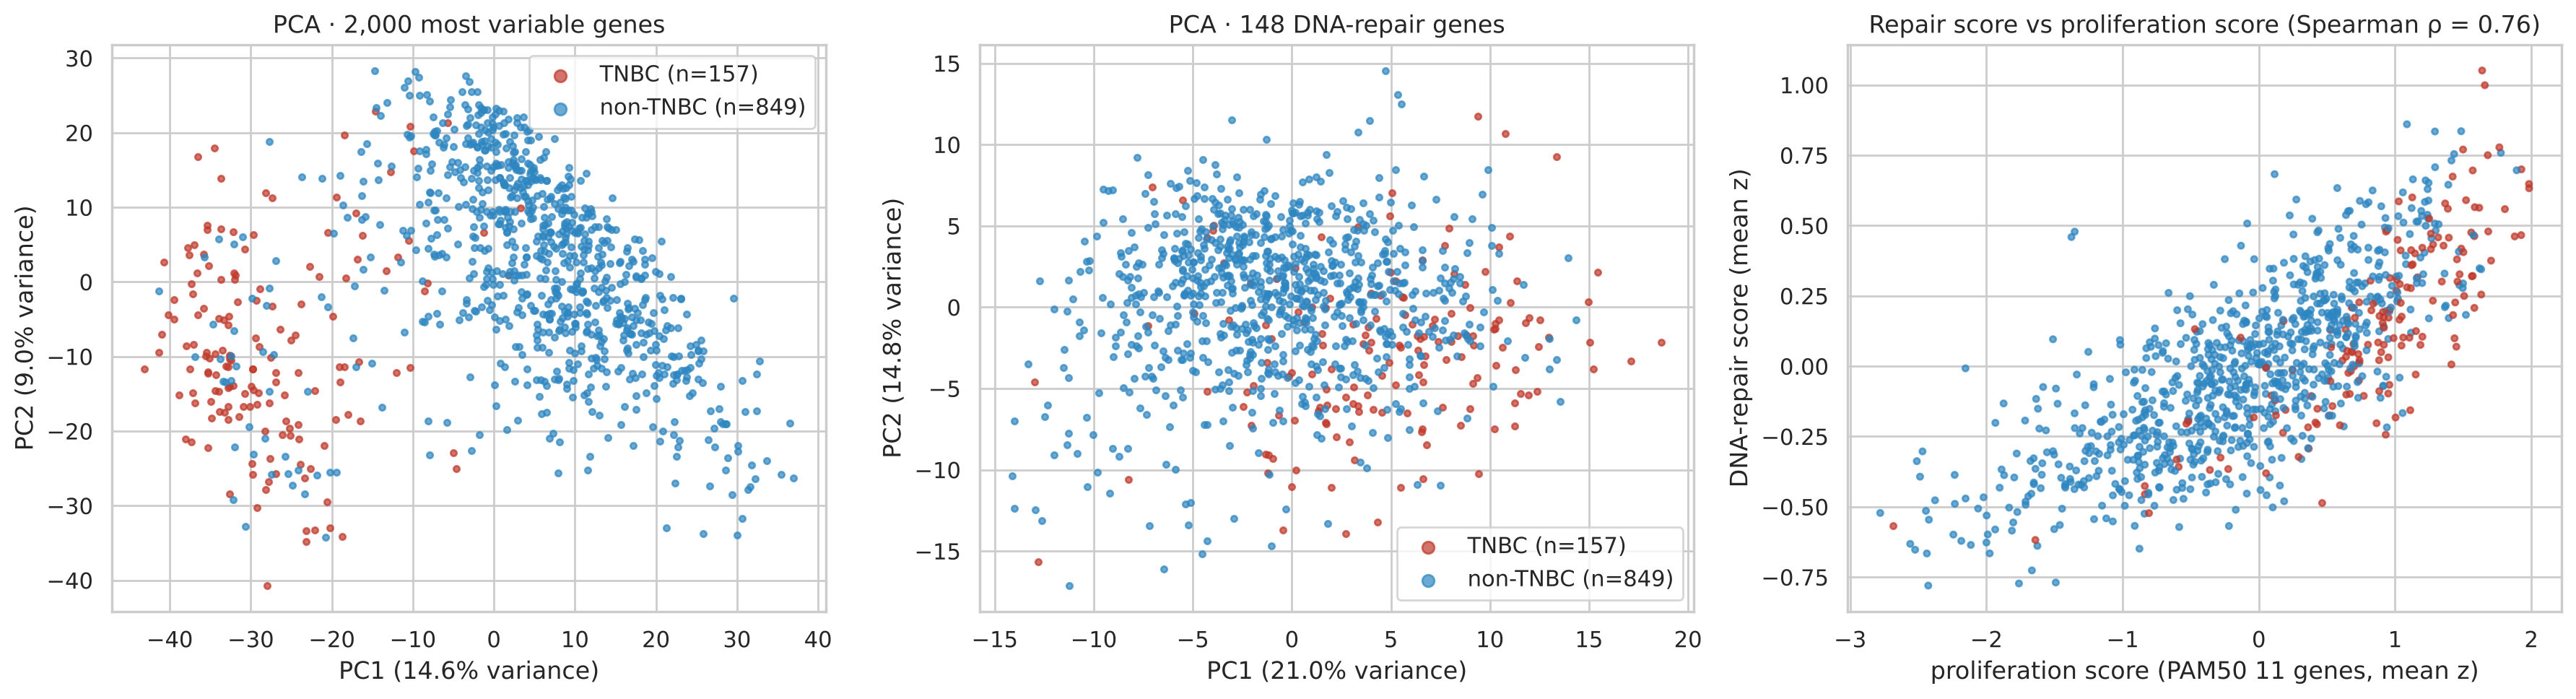

Repair-gene PC1 alone separates TNBC from non-TNBC with AUC = 0.78
Correlation of repair-gene PC1 with the proliferation score: ρ = 0.81
median proliferation score in TNBC: 0.95; median repair score: 0.14
median proliferation score in non-TNBC: -0.09; median repair score: -0.04


In [14]:
# Scores used throughout: z-score each gene, then average over the gene set
z = logn.sub(logn.mean(axis=1), axis=0).div(logn.std(axis=1), axis=0)
prolif_ids = [i for i in PROLIF.values() if i in z.index]
prolif_score = z.loc[prolif_ids].mean(axis=0)
repair_score = z.loc[repair_present].mean(axis=0)

from sklearn.decomposition import PCA
def pca_plot(mat, ax, title):
    X = (mat.T - mat.T.mean()) / mat.T.std()
    pca = PCA(n_components=2, random_state=SEED).fit(X)
    pcs = pca.transform(X)
    for g, col in GROUP_COLORS.items():
        m = (cohort["group"] == g).values
        ax.scatter(pcs[m, 0], pcs[m, 1], s=9, alpha=0.7, c=col, label=f"{g} (n={m.sum()})")
    ev = pca.explained_variance_ratio_ * 100
    ax.set(title=title, xlabel=f"PC1 ({ev[0]:.1f}% variance)", ylabel=f"PC2 ({ev[1]:.1f}% variance)")
    ax.legend(markerscale=2)
    return pcs, ev

top_var = logn.var(axis=1).sort_values(ascending=False).index[:2000]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pcs_all, ev_all = pca_plot(logn.loc[top_var], axes[0], "PCA · 2,000 most variable genes")
pcs_rep, ev_rep = pca_plot(logn.loc[repair_present], axes[1], f"PCA · {len(repair_present)} DNA-repair genes")
axes[2].scatter(prolif_score, repair_score, s=9, alpha=0.7, c=cohort["group"].map(GROUP_COLORS))
r_pr = stats.spearmanr(prolif_score, repair_score)[0]
print(f"Spearman correlation, repair score vs proliferation score: {r_pr:.2f}")
axes[2].set(title=f"Repair score vs proliferation score (Spearman ρ = {r_pr:.2f})",
            xlabel="proliferation score (PAM50 11 genes, mean z)", ylabel="DNA-repair score (mean z)")
plt.tight_layout(); plt.show()

auc_pc1 = max(stats.mannwhitneyu(pcs_rep[y.values == 1, 0], pcs_rep[y.values == 0, 0]).statistic,
              stats.mannwhitneyu(pcs_rep[y.values == 0, 0], pcs_rep[y.values == 1, 0]).statistic) / (y.sum() * (1 - y).sum())
print(f"Repair-gene PC1 alone separates TNBC from non-TNBC with AUC = {auc_pc1:.2f}")
print(f"Correlation of repair-gene PC1 with the proliferation score: ρ = {abs(stats.spearmanr(pcs_rep[:, 0], prolif_score)[0]):.2f}")
for g in GROUP_COLORS:
    print(f"median proliferation score in {g}: {prolif_score[cohort.group == g].median():.2f}; "
          f"median repair score: {repair_score[cohort.group == g].median():.2f}")

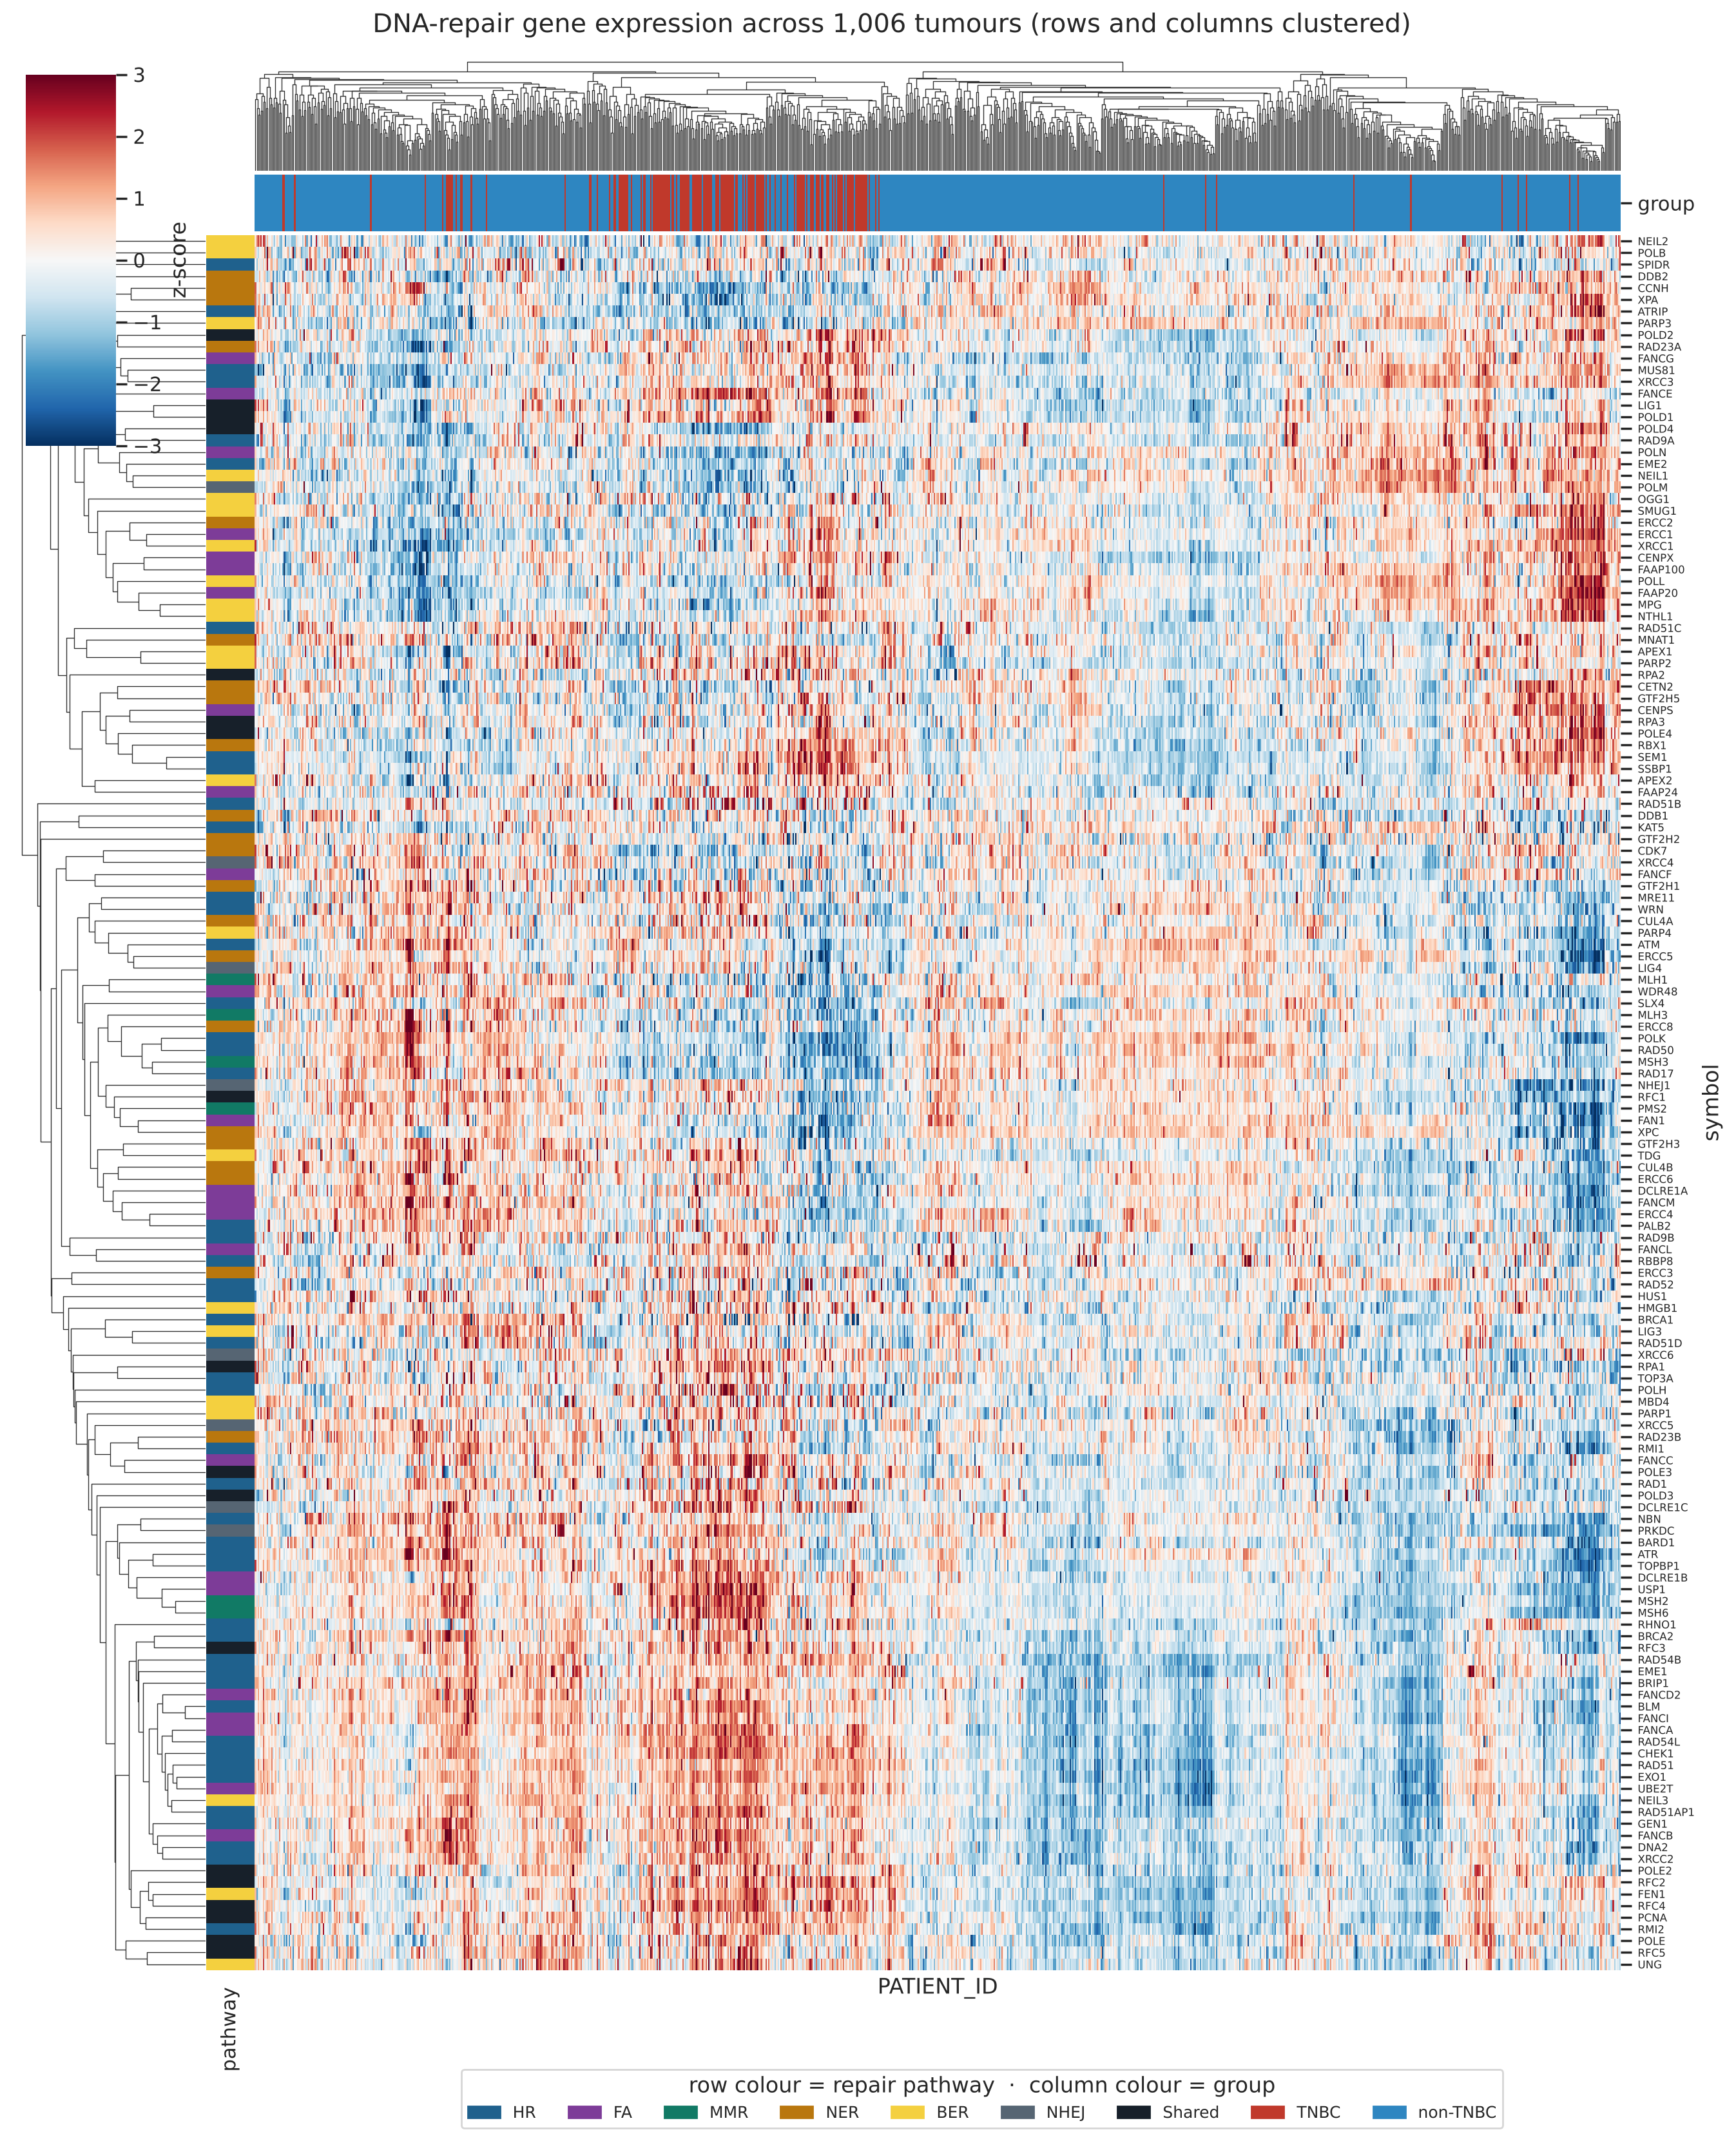

In [15]:
# Clustered heatmap of DNA-repair genes (z-scores, clipped at ±3) with the TNBC annotation
order = cohort.sort_values("group").index
hm = z.loc[repair_present, order].clip(-3, 3)
hm.index = repair.loc[repair_present, "symbol"]
lab_colors = {"HR": "#1F618D", "FA": "#7D3C98", "MMR": "#117A65", "NER": "#B9770E", "BER": "#F4D03F",
              "NHEJ": "#566573", "Shared": "#17202A"}
cg = sns.clustermap(hm, cmap="RdBu_r", center=0, figsize=(14, 16), xticklabels=False, yticklabels=True,
                    col_colors=cohort.loc[order, "group"].map(GROUP_COLORS).rename("group"),
                    row_colors=pd.Series(repair.loc[repair_present, "label"].map(lab_colors).values, index=hm.index, name="pathway"),
                    method="average", metric="correlation", dendrogram_ratio=(0.12, 0.06),
                    cbar_kws={"label": "z-score"})
cg.ax_heatmap.tick_params(axis="y", labelsize=6)
from matplotlib.patches import Patch
handles = [Patch(color=c, label=l) for l, c in lab_colors.items()] + [Patch(color=c, label=g) for g, c in GROUP_COLORS.items()]
cg.fig.legend(handles=handles, loc="lower center", ncol=9, bbox_to_anchor=(0.55, -0.02), fontsize=9,
              title="row colour = repair pathway  ·  column colour = group")
cg.fig.suptitle("DNA-repair gene expression across 1,006 tumours (rows and columns clustered)", y=1.01)
plt.show()

In [ ]:
# Which genes drive PC1 of the repair-gene PCA? PC1 is the proliferation axis (see above),
# so its loadings name the repair genes that move with proliferation in TNBC.
Xr = (logn.loc[repair_present].T - logn.loc[repair_present].T.mean()) / logn.loc[repair_present].T.std()
rep_pca = PCA(n_components=2, random_state=SEED).fit(Xr)
load1 = pd.Series(rep_pca.components_[0], index=repair_present)
score1 = rep_pca.transform(Xr)[:, 0]
if stats.spearmanr(score1, prolif_score)[0] < 0:          # PC1 sign is arbitrary; orient it so that
    load1 = -load1                                         # the positive end = high-proliferation / TNBC
load1 = load1.sort_values()
top = pd.concat([load1.head(12), load1.tail(12)])          # 12 lowest + 12 highest loadings
fig, ax = plt.subplots(figsize=(6, 8))
ax.barh(repair.loc[top.index, "symbol"], top.values,
        color=["#C0392B" if v > 0 else "#2471A3" for v in top.values])
ax.axvline(0, color="k", lw=0.6)
ax.set(title="Genes loading on PC1 of the repair-gene PCA\n(positive end = high-proliferation / TNBC direction)",
       xlabel="PC1 loading")
plt.tight_layout(); plt.show()
print("High-proliferation end:", ", ".join(repair.loc[load1.tail(8).index[::-1], "symbol"]))
print("Opposite end:         ", ", ".join(repair.loc[load1.head(8).index, "symbol"]))

**Interpretation (Stage 4).** 

* **Cohort:** TNBC patients are younger (median age 54 vs 60, p = 1 × 10⁻⁴) and much more often Black / African American (33.8% vs 13.7%, p ≈ 10⁻⁸). This matches the epidemiology of TNBC (Carey et al., 2006). It also shows the representation problem from our ethics presentation: most patients are White (57–70%), about 5% are Asian, and none were recruited in Africa.
* **Genome-wide PCA:** TNBC tumours form their own cluster at the negative end of PC1. TNBC differs across the whole transcriptome, not just in a few genes; this is the basal-like phenotype.
* **Repair-gene PCA:** using only the 148 repair genes, TNBC still shift along PC1 (AUC 0.78). But repair-gene PC1 is strongly correlated with the proliferation score (ρ = 0.81), so the main axis of variation among repair genes is a **proliferation axis**.
* **What drives repair-gene PC1:** the positive (high-proliferation / TNBC) end of PC1 is built from replication-coupled HR and Fanconi-anaemia genes together with S-phase checkpoint and mismatch-repair genes (*RAD51AP1, BLM, EXO1, FANCB, FANCI, FANCD2, MSH2, MSH6, CHEK1, TOPBP1, DNA2, NEIL3*) — genes that are switched on in dividing cells. Because these same genes define PC1 and PC1 tracks the proliferation score (ρ = 0.81), the main "repair" axis is really a **cell-cycle axis**: the repair genes that look high in TNBC are largely the ones expressed in proliferating tumours. The opposite end carries base- and nucleotide-excision-repair genes and back-up / translesion polymerases (*NEIL1, MPG, POLM, POLL, POLN, POLD4, PARP3, FAAP20, ERCC1, XPA, CCNH, ATRIP*), repair activities that are not replication-coupled. This is exactly why Stage 5 removes the proliferation effect before trusting any repair-specific difference.
* **Repair vs proliferation:** the average repair score tracks proliferation closely (ρ = 0.76). TNBC sit at the high-proliferation end (median proliferation z-score 0.95 vs −0.09), yet their mean repair score is only slightly higher (0.14 vs −0.04). Averaging over all repair genes hides genes that move in opposite directions.
* **Heatmap:** clustering places most TNBC tumours together in one block of columns. In that block, a large group of HR, FA and replication genes (*BLM, FANCA, FANCD2, FANCI, RAD51, RAD51AP1, EXO1, CHEK1, BRCA2, UBE2T …*) is high. A smaller set (*RAD50, MSH3, POLK, XPC …*) is low in part of the same block. Stage 5 tests both patterns formally.

## Stage 5 · Core analysis: differential expression

*Stage lead: Pete Njagi*

**Primary method: DESeq2** (Python port *PyDESeq2*) on raw counts. It uses a negative-binomial model with median-of-ratios normalisation and a Wald test, plus **Benjamini–Hochberg FDR** correction. We test all 16k expressed genes so that dispersion estimates and the FDR are genome-wide. We then look at the 148 expressed repair genes and also re-adjust p-values within that pre-specified family.

**Effect-size threshold.** With ~1,000 tumours even tiny differences become "significant", so we call a gene *strongly* differentially expressed only if FDR < 0.05 **and** |log2 fold change| ≥ 1 (≥ two-fold).

**Robustness checks**

1. A **Wilcoxon rank-sum test** on normalised expression, which is distribution-free and recommended for large human cohorts (Li et al., *Genome Biology* 2022).
2. A **gene-set (competitive) test**: are repair genes shifted more than random sets of genes?
3. A **proliferation-adjusted model**: is the difference still there after accounting for how fast the tumour is dividing?

In [16]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

t0 = time.time()
meta = pd.DataFrame({"group": np.where(y == 1, "TNBC", "nonTNBC")}, index=counts_f.columns)
inference = DefaultInference(n_cpus=os.cpu_count())
dds = DeseqDataSet(counts=counts_f.T.astype(int), metadata=meta, design="~group",
                   refit_cooks=True, inference=inference, quiet=True)
dds.deseq2()
ds = DeseqStats(dds, contrast=["group", "TNBC", "nonTNBC"], inference=inference, quiet=True)
ds.summary()
de = ds.results_df.copy()
de.index = de.index.astype(int)
print(f"DESeq2 finished in {time.time()-t0:.0f}s")
print("size factors agree with Stage 3:", round(np.corrcoef(dds.obs["size_factors"] if "size_factors" in dds.obs
      else dds.obsm["size_factors"], size_factors)[0, 1], 4))

de["symbol"] = [SYMBOL.get(i, "") for i in de.index]
sig = (de.padj < 0.05)
print(f"\nGenome-wide: {int(sig.sum()):,} of {len(de):,} genes have FDR < 0.05 "
      f"({sig.mean():.0%}); {int((sig & (de.log2FoldChange.abs() >= 1)).sum()):,} also have |log2FC| ≥ 1.")
display(de.loc[[MARKERS[g] for g in ["ESR1", "PGR", "ERBB2", "FOXA1", "GATA3", "FOXC1", "KRT5"]],
               ["symbol", "baseMean", "log2FoldChange", "padj"]].round(3))

DESeq2 finished in 59s
size factors agree with Stage 3: 1.0

Genome-wide: 13,377 of 16,697 genes have FDR < 0.05 (80%); 2,699 also have |log2FC| ≥ 1.


,symbol,baseMean,log2FoldChange,padj
Entrez_Gene_Id,,,,
2099,ESR1,31220.046,-5.023,0.0
5241,PGR,8612.827,-4.123,0.0
2064,ERBB2,50872.633,-2.198,0.0
3169,FOXA1,18241.482,-2.892,0.0
2625,GATA3,35047.612,-3.158,0.0
2296,FOXC1,1675.520,2.983,0.0
3852,KRT5,15042.547,2.454,0.0


In [17]:
# Wilcoxon rank-sum test for every gene on log2 normalised expression (vectorised)
mw = stats.mannwhitneyu(logn.loc[:, y.values == 1].values, logn.loc[:, y.values == 0].values, axis=1)
de["wilcoxon_auc"] = mw.statistic / (y.sum() * (1 - y).sum())       # >0.5 = higher in TNBC
de["wilcoxon_padj"] = multipletests(mw.pvalue, method="fdr_bh")[1]

# DNA-repair results table
rep = de.loc[repair_present].copy()
rep["pathways"] = repair.loc[repair_present, "pathways"]
rep["label"] = repair.loc[repair_present, "label"]
rep["padj_repair_family"] = multipletests(rep.pvalue, method="fdr_bh")[1]
def call(r):
    if r.padj_repair_family >= 0.05: return "not significant"
    if abs(r.log2FoldChange) >= 1: return "UP ≥2x in TNBC" if r.log2FoldChange > 0 else "DOWN ≥2x in TNBC"
    return "up (<2x)" if r.log2FoldChange > 0 else "down (<2x)"
rep["call"] = rep.apply(call, axis=1)
rep = rep.sort_values("stat", ascending=False)
cols = ["symbol", "pathways", "baseMean", "log2FoldChange", "lfcSE", "padj", "padj_repair_family",
        "wilcoxon_auc", "wilcoxon_padj", "call"]
print(rep["call"].value_counts().to_string())
print("\nTop 15 up in TNBC:")
display(rep[cols].head(15).round(4))
print("Top 10 down in TNBC:")
display(rep[cols].tail(10).iloc[::-1].round(4))
rep[cols].to_csv(os.path.join(RESULTS_DIR, "dna_repair_DE_results.csv"))
de.to_csv(os.path.join(RESULTS_DIR, "genome_wide_DESeq2_results.csv"))

agree_sig = ((rep.padj_repair_family < 0.05) == (rep.wilcoxon_padj < 0.05)).mean()
agree_dir = (np.sign(rep.log2FoldChange) == np.sign(rep.wilcoxon_auc - 0.5)).mean()
print(f"DESeq2 vs Wilcoxon: same direction for {agree_dir:.0%} of repair genes; "
      f"same significance call for {agree_sig:.0%}.")

call
up (<2x)            69
down (<2x)          36
not significant     32
UP ≥2x in TNBC      10
DOWN ≥2x in TNBC     1

Top 15 up in TNBC:


,symbol,pathways,baseMean,log2FoldChange,lfcSE,padj,padj_repair_family,wilcoxon_auc,wilcoxon_padj,call
entrez,,,,,,,,,,
2178,FANCE,FA,458.9335,1.2031,0.0650,0.0,0.0,0.8478,0.0,UP ≥2x in TNBC
64421,DCLRE1C,NHEJ,1266.4198,0.7781,0.0461,0.0,0.0,0.7986,0.0,up (<2x)
2175,FANCA,FA,650.0272,1.3780,0.0841,0.0,0.0,0.8493,0.0,UP ≥2x in TNBC
1111,CHEK1,HR,1017.2911,1.2893,0.0796,0.0,0.0,0.8502,0.0,UP ≥2x in TNBC
4436,MSH2,MMR,3018.6219,0.8240,0.0509,0.0,0.0,0.7910,0.0,up (<2x)
5984,RFC4,HR;MMR;NER,1428.9773,1.0160,0.0633,0.0,0.0,0.8173,0.0,UP ≥2x in TNBC
7398,USP1,FA,4389.0897,0.9480,0.0604,0.0,0.0,0.7771,0.0,up (<2x)
8438,RAD54L,HR,318.2070,1.3724,0.0904,0.0,0.0,0.8347,0.0,UP ≥2x in TNBC
64858,DCLRE1B,FA,864.7068,0.7233,0.0490,0.0,0.0,0.7834,0.0,up (<2x)


Top 10 down in TNBC:


,symbol,pathways,baseMean,log2FoldChange,lfcSE,padj,padj_repair_family,wilcoxon_auc,wilcoxon_padj,call
entrez,,,,,,,,,,
902,CCNH,NER,1278.4216,-0.6189,0.0406,0.0,0.0,0.1751,0.0,down (<2x)
5884,RAD17,HR,1913.9740,-0.5103,0.0360,0.0,0.0,0.1747,0.0,down (<2x)
10111,RAD50,HR;NHEJ,189.2174,-0.7936,0.0594,0.0,0.0,0.2007,0.0,down (<2x)
57804,POLD4,HR;MMR;NER;BER,438.6337,-0.8934,0.0704,0.0,0.0,0.2138,0.0,down (<2x)
7507,XPA,NER,783.5855,-0.4945,0.0392,0.0,0.0,0.2169,0.0,down (<2x)
4437,MSH3,MMR,1529.3320,-0.5696,0.0464,0.0,0.0,0.2088,0.0,down (<2x)
51426,POLK,HR,1148.9017,-0.6935,0.0572,0.0,0.0,0.2090,0.0,down (<2x)
84126,ATRIP,HR;FA,1203.1568,-0.6307,0.0528,0.0,0.0,0.2218,0.0,down (<2x)
353497,POLN,FA,70.6904,-1.1474,0.1032,0.0,0.0,0.2336,0.0,DOWN ≥2x in TNBC


DESeq2 vs Wilcoxon: same direction for 94% of repair genes; same significance call for 91%.


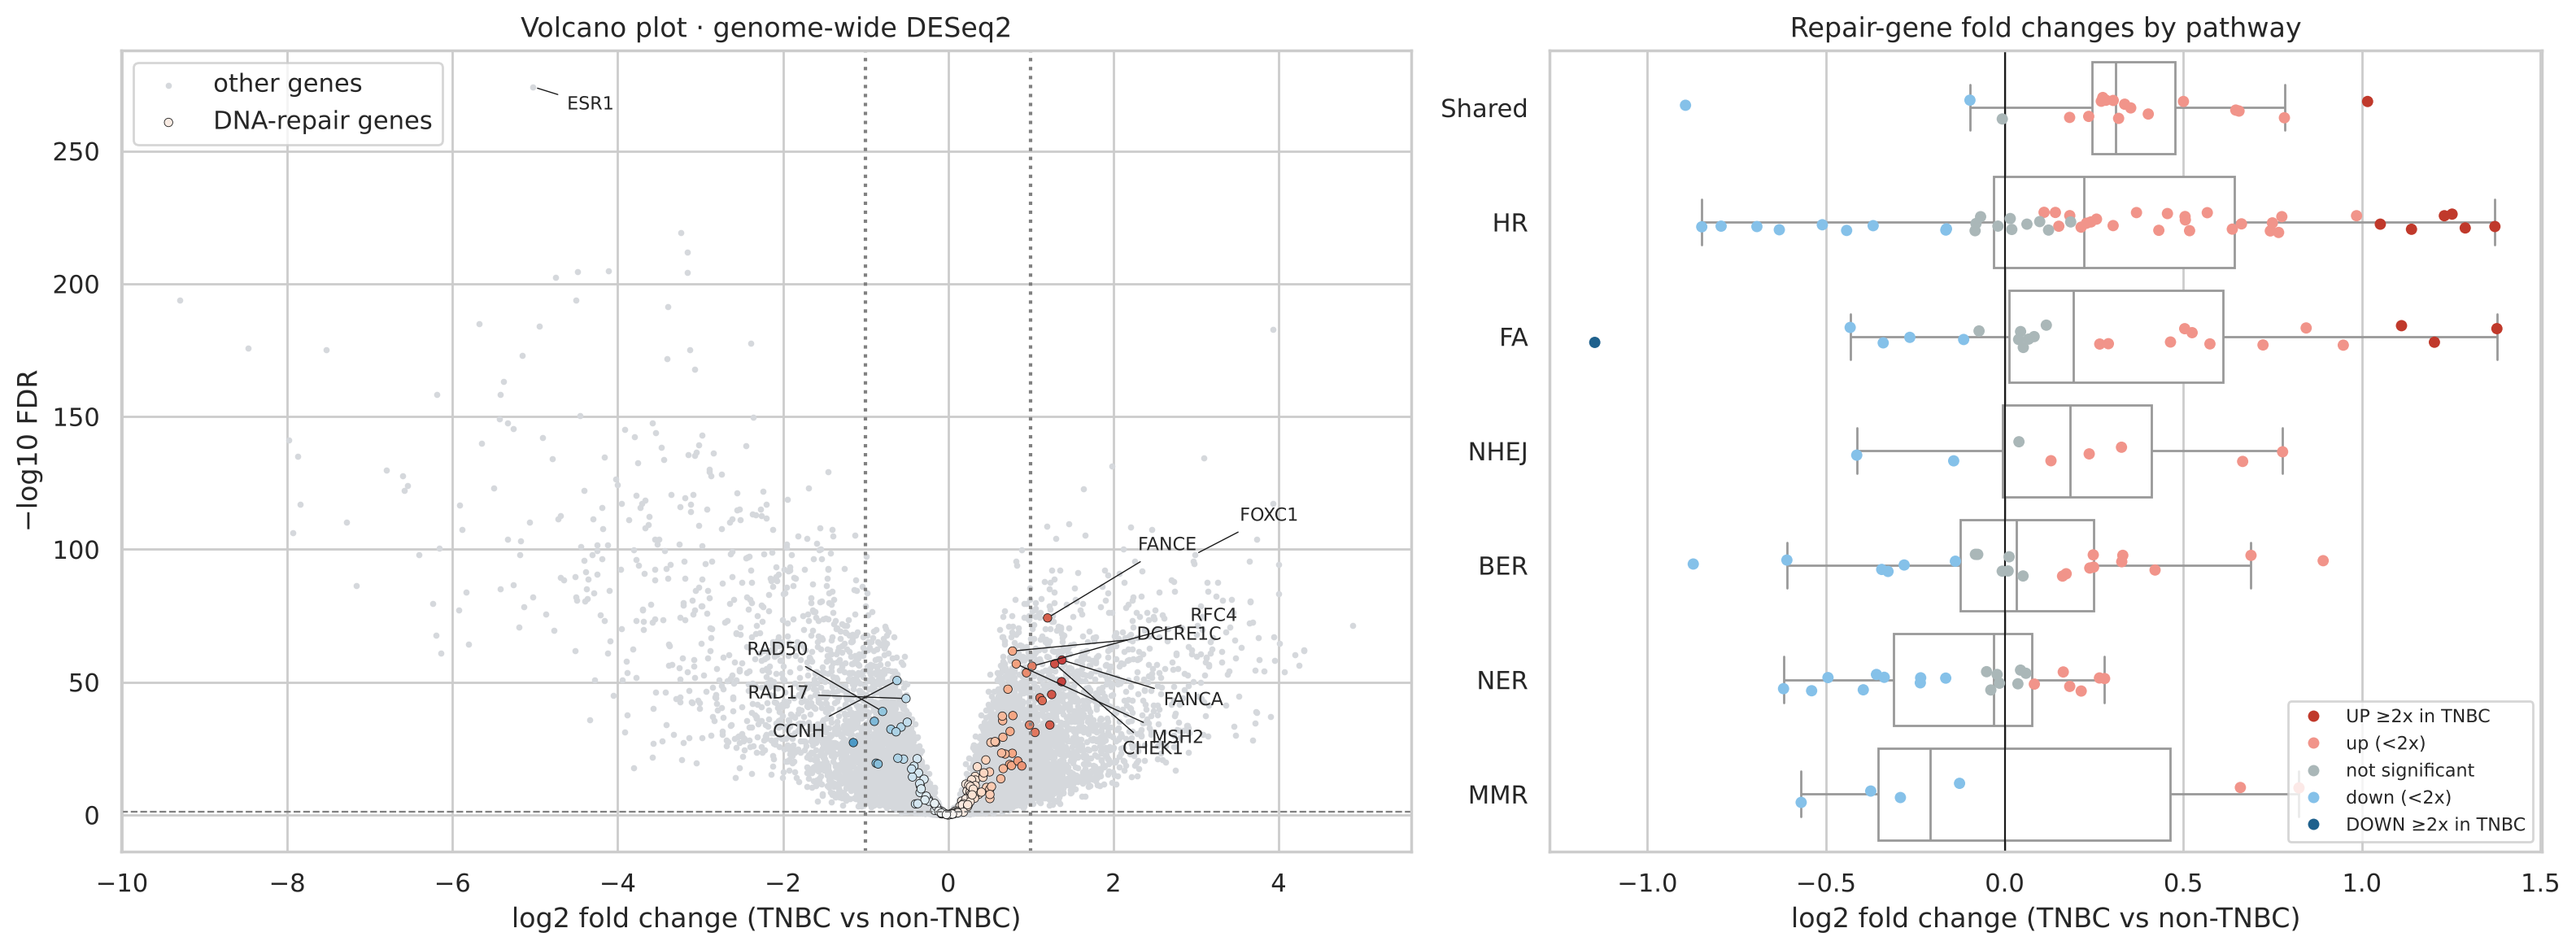

In [18]:
# Volcano plot (genome-wide), repair genes highlighted
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
nl = -np.log10(de.padj.clip(lower=1e-300))
ax.scatter(de.log2FoldChange, nl, s=3, c="#D5D8DC", label="other genes")
is_rep = de.index.isin(repair_present)
ax.scatter(de.log2FoldChange[is_rep], nl[is_rep], s=14, c=de.log2FoldChange[is_rep], cmap="RdBu_r",
           vmin=-2, vmax=2, edgecolor="k", linewidth=0.3, label="DNA-repair genes")
label_ids = list(rep.index[:6]) + list(rep.index[-3:]) + [MARKERS["ESR1"], MARKERS["FOXC1"]]
offsets = [(40, 30), (55, 5), (45, -20), (30, -40), (60, -35), (70, 20), (-60, 25), (-70, 0), (-55, -25), (15, -10), (20, 15)]
for eid, off in zip(label_ids, offsets):
    ax.annotate(de.symbol[eid], (de.log2FoldChange[eid], nl[eid]), fontsize=8, xytext=off, textcoords="offset points",
                arrowprops=dict(arrowstyle="-", lw=0.5, color="k"))
ax.axhline(-np.log10(0.05), ls="--", c="grey", lw=0.8); ax.axvline(1, ls=":", c="grey"); ax.axvline(-1, ls=":", c="grey")
ax.set(xlabel="log2 fold change (TNBC vs non-TNBC)", ylabel="−log10 FDR", title="Volcano plot · genome-wide DESeq2")
ax.legend(loc="upper left")

# log2FC of repair genes by pathway label
order_lab = rep.groupby("label").log2FoldChange.median().sort_values(ascending=False).index
sns.boxplot(data=rep, y="label", x="log2FoldChange", order=order_lab, ax=axes[1], color="white", fliersize=0)
sns.stripplot(data=rep, y="label", x="log2FoldChange", order=order_lab, ax=axes[1], hue="call", size=5,
              palette={"UP ≥2x in TNBC": "#C0392B", "up (<2x)": "#F1948A", "not significant": "#AAB7B8",
                       "down (<2x)": "#85C1E9", "DOWN ≥2x in TNBC": "#1F618D"})
axes[1].axvline(0, c="k", lw=0.8)
axes[1].set(title="Repair-gene fold changes by pathway", xlabel="log2 fold change (TNBC vs non-TNBC)", ylabel="")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

mean Wald statistic, repair genes: 2.64 vs random sets: 0.49 (95% range -0.82 to 1.79); one-sided permutation p = 0.0003
mean |Wald|, repair genes: 6.63 vs random: 6.46; permutation p = 0.3339
fraction up in TNBC: repair 66% vs all other genes 54%


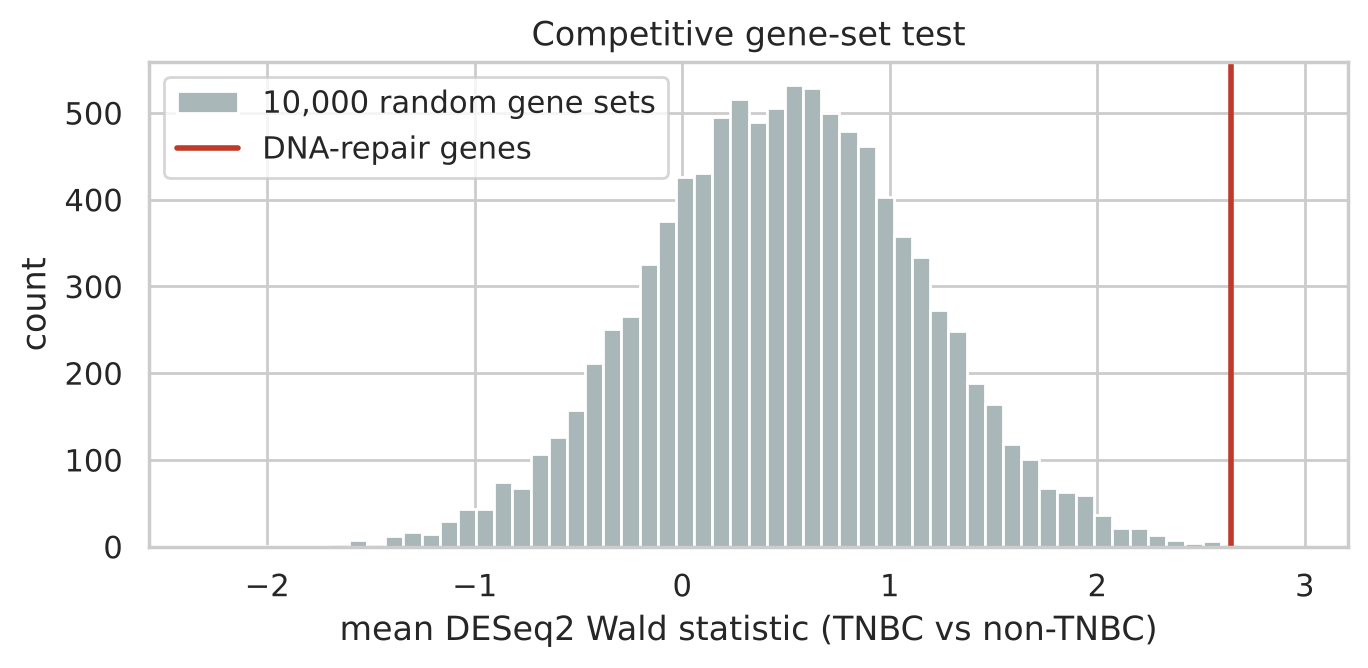

In [19]:
# Gene-set (competitive) test: are repair genes more shifted than random gene sets of the same size?
wald = de["stat"]
others = wald.drop(repair_present)
obs_mean, obs_abs = wald[repair_present].mean(), wald[repair_present].abs().mean()
rng = np.random.default_rng(SEED)
n_perm = 10_000
perm = np.array([rng.choice(others.values, len(repair_present), replace=False) for _ in range(n_perm)])
p_mean = (np.sum(perm.mean(axis=1) >= obs_mean) + 1) / (n_perm + 1)
p_abs = (np.sum(np.abs(perm).mean(axis=1) >= obs_abs) + 1) / (n_perm + 1)
print(f"mean Wald statistic, repair genes: {obs_mean:.2f} vs random sets: {perm.mean():.2f} "
      f"(95% range {np.percentile(perm.mean(1), 2.5):.2f} to {np.percentile(perm.mean(1), 97.5):.2f}); "
      f"one-sided permutation p = {p_mean:.4f}")
print(f"mean |Wald|, repair genes: {obs_abs:.2f} vs random: {np.abs(perm).mean():.2f}; permutation p = {p_abs:.4f}")
print(f"fraction up in TNBC: repair {(wald[repair_present] > 0).mean():.0%} vs all other genes {(others > 0).mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(perm.mean(axis=1), bins=60, color="#AAB7B8", label="10,000 random gene sets")
ax.axvline(obs_mean, color="#C0392B", lw=2, label="DNA-repair genes")
ax.set(xlabel="mean DESeq2 Wald statistic (TNBC vs non-TNBC)", ylabel="count", title="Competitive gene-set test")
ax.legend(); plt.tight_layout(); plt.show()

Before adjustment: 74 repair genes up, 39 down in TNBC (FDR < 0.05)
After adjusting for proliferation: 38 up, 67 down
Median correlation of repair genes with the proliferation score: ρ = 0.22
For genes up before adjustment, median share of the TNBC difference left after adjustment: 31%

Repair genes still UP in TNBC after proliferation adjustment (largest effects):


,symbol,label,diff_unadjusted,diff_adjusted,fdr_adjusted,r_with_prolif
entrez,,,,,,
5890,RAD51B,HR,0.641,0.800,0.0,-0.073
2178,FANCE,FA,1.130,0.737,0.0,0.542
2175,FANCA,FA,1.417,0.519,0.0,0.794
7398,USP1,FA,0.811,0.471,0.0,0.508
64421,DCLRE1C,NHEJ,0.690,0.466,0.0,0.468
1111,CHEK1,HR,1.361,0.456,0.0,0.830
7979,SEM1,HR,0.715,0.424,0.0,0.470
5424,POLD1,Shared,0.756,0.412,0.0,0.500
5984,RFC4,Shared,0.969,0.386,0.0,0.763


Repair genes DOWN in TNBC after adjustment (largest effects):


,symbol,label,diff_unadjusted,diff_adjusted,fdr_adjusted,r_with_prolif
entrez,,,,,,
672,BRCA1,HR,-0.291,-0.841,0.0,0.437
353497,POLN,FA,-1.218,-0.779,0.0,-0.405
57804,POLD4,Shared,-0.858,-0.774,0.0,-0.236
10111,RAD50,HR,-0.814,-0.681,0.0,-0.305
197342,EME2,HR,-0.713,-0.661,0.0,-0.143
84126,ATRIP,HR,-0.601,-0.580,0.0,-0.202
4437,MSH3,MMR,-0.593,-0.565,0.0,-0.204
146956,EME1,HR,0.492,-0.538,0.0,0.735
84464,SLX4,HR,-0.445,-0.535,0.0,-0.005


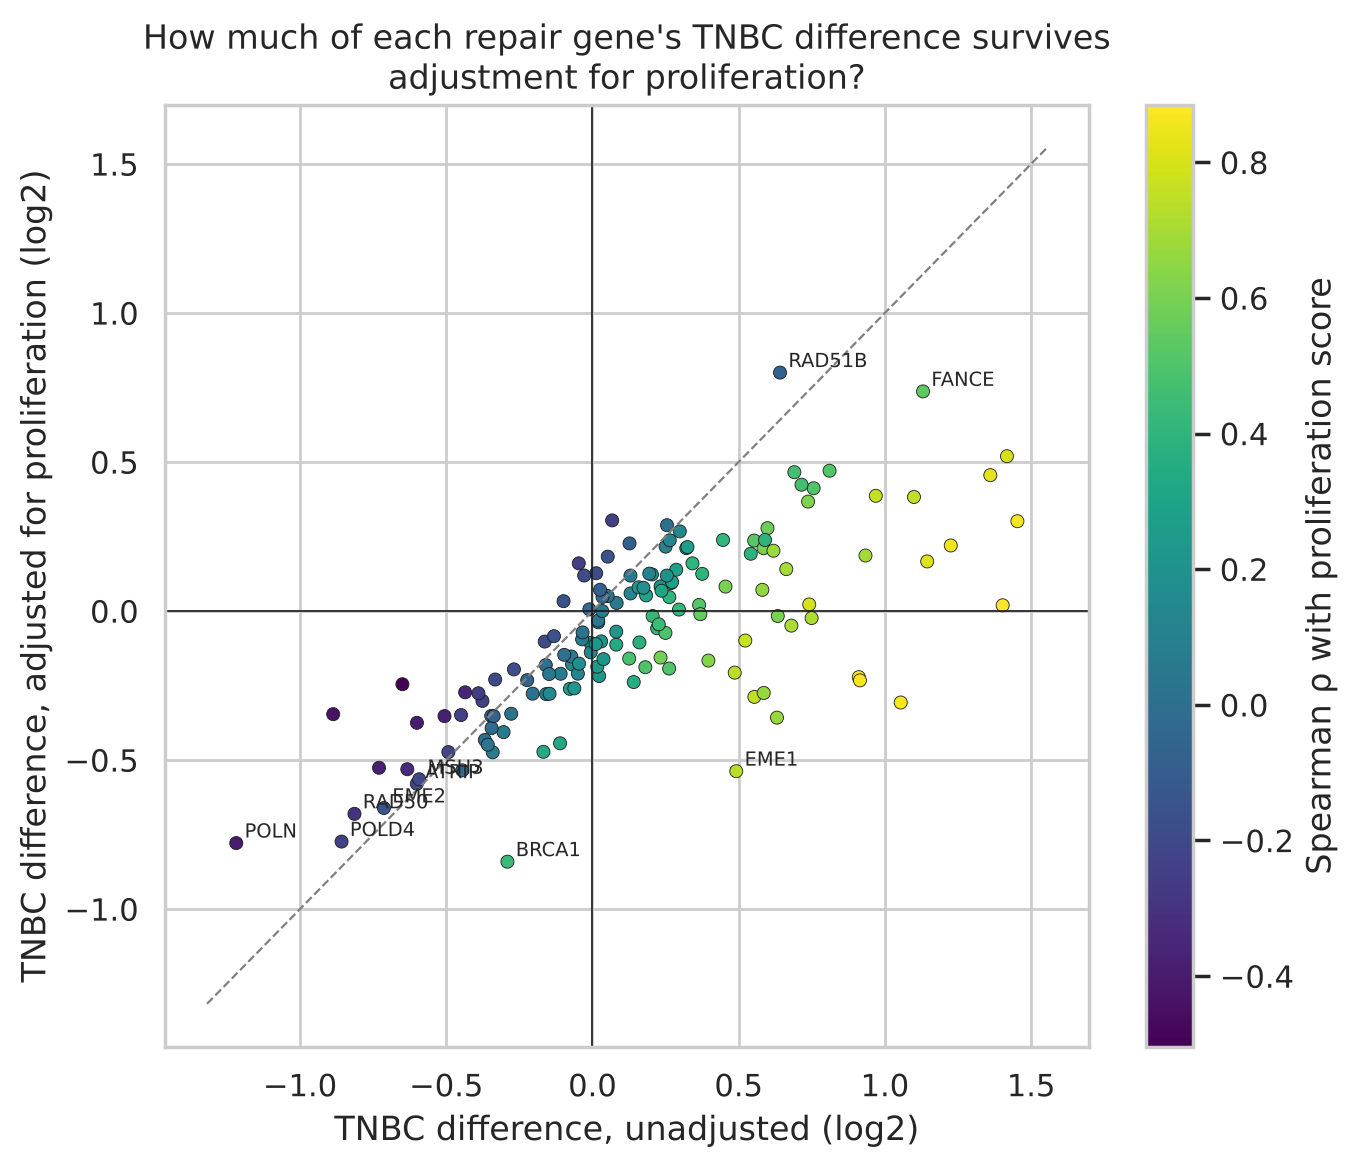

In [20]:
# Proliferation-adjusted model for each repair gene:  expression ~ TNBC  vs  expression ~ TNBC + proliferation
rows = []
for eid in repair_present:
    yy = logn.loc[eid].values
    m0 = sm.OLS(yy, sm.add_constant(y.values.astype(float))).fit(cov_type="HC3")
    X1 = sm.add_constant(np.column_stack([y.values.astype(float), prolif_score.values]))
    m1 = sm.OLS(yy, X1).fit(cov_type="HC3")
    rows.append({"entrez": eid, "symbol": repair.loc[eid, "symbol"], "label": repair.loc[eid, "label"],
                 "diff_unadjusted": m0.params[1], "p_unadjusted": m0.pvalues[1],
                 "diff_adjusted": m1.params[1], "p_adjusted": m1.pvalues[1],
                 "prolif_coef": m1.params[2], "r_with_prolif": stats.spearmanr(yy, prolif_score)[0]})
adj = pd.DataFrame(rows).set_index("entrez")
adj["fdr_unadjusted"] = multipletests(adj.p_unadjusted, method="fdr_bh")[1]
adj["fdr_adjusted"] = multipletests(adj.p_adjusted, method="fdr_bh")[1]
adj["retained_pct"] = 100 * adj.diff_adjusted / adj.diff_unadjusted
up0 = (adj.fdr_unadjusted < 0.05) & (adj.diff_unadjusted > 0)
dn0 = (adj.fdr_unadjusted < 0.05) & (adj.diff_unadjusted < 0)
up1 = (adj.fdr_adjusted < 0.05) & (adj.diff_adjusted > 0)
dn1 = (adj.fdr_adjusted < 0.05) & (adj.diff_adjusted < 0)
print(f"Before adjustment: {int(up0.sum())} repair genes up, {int(dn0.sum())} down in TNBC (FDR < 0.05)")
print(f"After adjusting for proliferation: {int(up1.sum())} up, {int(dn1.sum())} down")
print(f"Median correlation of repair genes with the proliferation score: ρ = {adj.r_with_prolif.median():.2f}")
print(f"For genes up before adjustment, median share of the TNBC difference left after adjustment: "
      f"{adj.loc[up0, 'retained_pct'].median():.0f}%")
print("\nRepair genes still UP in TNBC after proliferation adjustment (largest effects):")
display(adj[up1].sort_values("diff_adjusted", ascending=False).head(12)[
    ["symbol", "label", "diff_unadjusted", "diff_adjusted", "fdr_adjusted", "r_with_prolif"]].round(3))
print("Repair genes DOWN in TNBC after adjustment (largest effects):")
display(adj[dn1].sort_values("diff_adjusted").head(12)[
    ["symbol", "label", "diff_unadjusted", "diff_adjusted", "fdr_adjusted", "r_with_prolif"]].round(3))
adj.to_csv(os.path.join(RESULTS_DIR, "dna_repair_proliferation_adjusted.csv"))

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(adj.diff_unadjusted, adj.diff_adjusted, c=adj.r_with_prolif, cmap="viridis", s=22, edgecolor="k", lw=0.3)
lim = [min(adj.diff_unadjusted.min(), adj.diff_adjusted.min()) - 0.1, max(adj.diff_unadjusted.max(), adj.diff_adjusted.max()) + 0.1]
ax.plot(lim, lim, ls="--", c="grey", lw=0.8); ax.axhline(0, c="k", lw=0.6); ax.axvline(0, c="k", lw=0.6)
for eid in adj.diff_adjusted.abs().sort_values().index[-10:]:
    ax.annotate(adj.symbol[eid], (adj.diff_unadjusted[eid], adj.diff_adjusted[eid]), fontsize=7, xytext=(3, 2), textcoords="offset points")
sc = ax.collections[0]; plt.colorbar(sc, ax=ax, label="Spearman ρ with proliferation score")
ax.set(xlabel="TNBC difference, unadjusted (log2)", ylabel="TNBC difference, adjusted for proliferation (log2)",
       title="How much of each repair gene's TNBC difference survives\nadjustment for proliferation?")
plt.tight_layout(); plt.show()

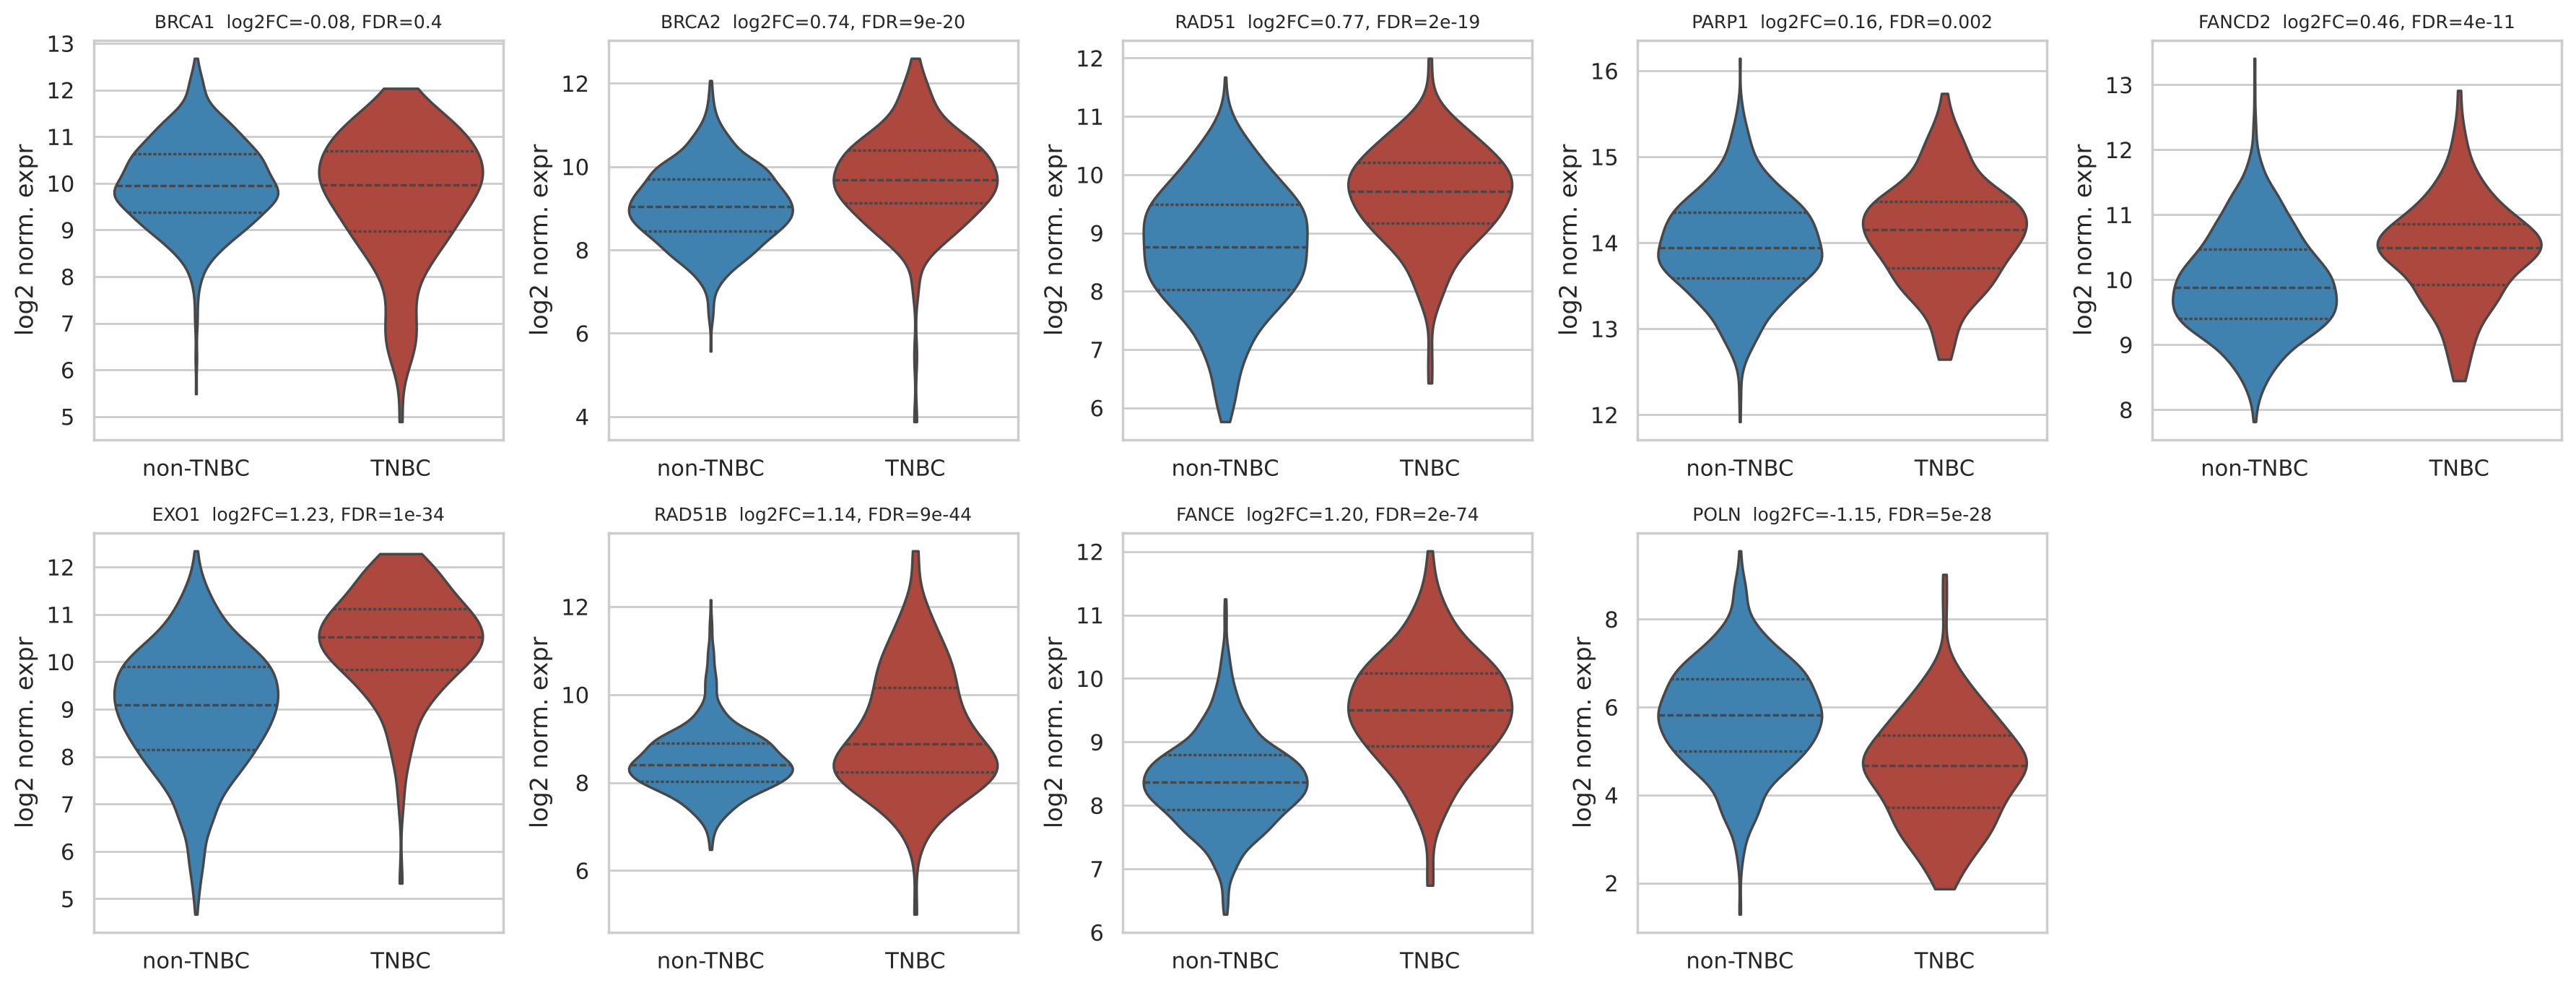

In [21]:
# Key genes: the BRCAness-related genes plus the strongest up/down genes after adjustment
show = ["BRCA1", "BRCA2", "RAD51", "PARP1", "FANCD2", "EXO1"]
show += [s for s in list(adj[up1].sort_values("diff_adjusted", ascending=False).symbol[:2]) +
         list(adj[dn1].sort_values("diff_adjusted").symbol[:2]) if s not in show]
fig, axes = plt.subplots(2, 5, figsize=(18, 7)); axes = axes.ravel()
sym2id = {v: k for k, v in repair["symbol"].items()}
for ax, s in zip(axes, show[:10]):
    df = pd.DataFrame({"expr": logn.loc[sym2id[s]], "group": cohort["group"]})
    sns.violinplot(data=df, x="group", y="expr", order=["non-TNBC", "TNBC"], palette=GROUP_COLORS, ax=ax, cut=0, inner="quartile")
    r = rep.loc[sym2id[s]]
    ax.set(title=f"{s}  log2FC={r.log2FoldChange:.2f}, FDR={r.padj_repair_family:.1g}", xlabel="", ylabel="log2 norm. expr")
    ax.title.set_fontsize(9)
for ax in axes[len(show):]: ax.axis("off")
plt.tight_layout(); plt.show()

### 5.5 Robustness to age

TNBC patients are younger than non-TNBC patients (median 54 vs 60, Stage 4), and age itself changes gene expression. So part of a "TNBC difference" could be an age difference. We re-run DESeq2 with age as a covariate, `design="~AGE + group"`, on the patients whose age is recorded. Age is standardised (mean 0, SD 1) so the model fits well; this does not change the TNBC coefficient.

Dropping patients also changes the estimates a little, so we fit a third model, `~group` on the **same** patients. Comparing the three separates the effect of the smaller sample from the effect of adjusting for age.

In [ ]:
age = pd.to_numeric(cohort["AGE"], errors="coerce").reindex(counts_f.columns)
has_age = age.notna().values
print(f"{int((~has_age).sum())} patients without a recorded age are dropped; "
      f"{int(has_age.sum())} remain ({int(y.values[has_age].sum())} TNBC, {int((1 - y.values)[has_age].sum())} non-TNBC)")
meta_age = meta.loc[has_age].copy()
meta_age["AGE"] = ((age[has_age] - age[has_age].mean()) / age[has_age].std()).values
counts_age = counts_f.loc[:, has_age].T.astype(int)

def run_deseq(design):
    """Fit DESeq2 on the patients with age and return the TNBC-vs-non-TNBC results table."""
    d = DeseqDataSet(counts=counts_age, metadata=meta_age, design=design,
                     refit_cooks=True, inference=inference, quiet=True)
    d.deseq2()
    s = DeseqStats(d, contrast=["group", "TNBC", "nonTNBC"], inference=inference, quiet=True)
    s.summary()
    r = s.results_df.copy()
    r.index = r.index.astype(int)
    return d, r

t0 = time.time()
dds_age, de_age = run_deseq("~AGE + group")          # age-adjusted
_, de_same = run_deseq("~group")                     # unadjusted, same patients
print(f"two extra DESeq2 fits finished in {time.time()-t0:.0f}s")

# Age effect itself (natural-log LFC per SD of age -> log2 per 10 years)
age_lfc = dds_age.varm["LFC"]["AGE"] / np.log(2) / age[has_age].std() * 10
age_lfc.index = age_lfc.index.astype(int)            # DESeq2 stores gene IDs as text
print(f"median |age effect| on repair genes: {age_lfc.reindex(counts_f.index).loc[repair_present].abs().median():.3f} "
      f"log2 per 10 years (TNBC effect: {rep.log2FoldChange.abs().median():.3f})")

cmp_age = pd.DataFrame({
    "symbol": rep.symbol,
    "lfc_original": rep.log2FoldChange,
    "lfc_same_patients": de_same.loc[rep.index, "log2FoldChange"],
    "lfc_age_adjusted": de_age.loc[rep.index, "log2FoldChange"],
    "padj_age_adjusted": de_age.loc[rep.index, "padj"],
})
cmp_age["padj_repair_family_age"] = multipletests(de_age.loc[rep.index, "pvalue"], method="fdr_bh")[1]
cmp_age["call_age_adjusted"] = [call(pd.Series({"padj_repair_family": p, "log2FoldChange": l}))
                                for p, l in zip(cmp_age.padj_repair_family_age, cmp_age.lfc_age_adjusted)]
cmp_age["call_original"] = rep["call"]
cmp_age["change"] = cmp_age.lfc_age_adjusted - cmp_age.lfc_original

r_p = stats.pearsonr(cmp_age.lfc_original, cmp_age.lfc_age_adjusted)[0]
r_s = stats.spearmanr(cmp_age.lfc_original, cmp_age.lfc_age_adjusted)[0]
r_sub = stats.pearsonr(cmp_age.lfc_same_patients, cmp_age.lfc_age_adjusted)[0]
sig0 = rep.padj_repair_family < 0.05
sig1 = cmp_age.padj_repair_family_age < 0.05
print(f"\nRepair-gene log2FC, original vs age-adjusted: Pearson r = {r_p:.3f}, Spearman ρ = {r_s:.3f}")
print(f"same patients without vs with age: Pearson r = {r_sub:.3f}")
print(f"median |change| in log2FC: {cmp_age.change.abs().median():.3f}; largest: {cmp_age.change.abs().max():.3f} "
      f"({cmp_age.loc[cmp_age.change.abs().idxmax(), 'symbol']})")
print(f"significant (repair-family FDR < 0.05): {int(sig0.sum())} originally, {int(sig1.sum())} age-adjusted; "
      f"same call for {(sig0 == sig1).mean():.0%} of genes; same direction for "
      f"{(np.sign(cmp_age.lfc_original) == np.sign(cmp_age.lfc_age_adjusted)).mean():.0%}")
print(f"up / down after age adjustment: {int((sig1 & (cmp_age.lfc_age_adjusted > 0)).sum())} / "
      f"{int((sig1 & (cmp_age.lfc_age_adjusted < 0)).sum())} (originally {int((sig0 & (rep.log2FoldChange > 0)).sum())} / "
      f"{int((sig0 & (rep.log2FoldChange < 0)).sum())})")
TWOFOLD = ["UP ≥2x in TNBC", "DOWN ≥2x in TNBC"]
print("≥2-fold calls, original:", ", ".join(cmp_age.symbol[cmp_age.call_original.isin(TWOFOLD)]))
print("≥2-fold calls, age-adjusted:", ", ".join(cmp_age.symbol[cmp_age.call_age_adjusted.isin(TWOFOLD)]))
changed = cmp_age[cmp_age.call_original != cmp_age.call_age_adjusted]
print(f"\n{len(changed)} repair genes change their call after age adjustment:")
display(changed[["symbol", "lfc_original", "lfc_age_adjusted", "call_original", "call_age_adjusted"]].round(3))
print("Largest shifts in log2FC:")
display(cmp_age.reindex(cmp_age.change.abs().sort_values(ascending=False).index).head(8)[
    ["symbol", "lfc_original", "lfc_same_patients", "lfc_age_adjusted", "change"]].round(3))
cmp_age.to_csv(os.path.join(RESULTS_DIR, "dna_repair_age_adjusted.csv"))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(cmp_age.lfc_original, cmp_age.lfc_age_adjusted, s=20, c=np.where(sig1, "#C0392B", "#AAB7B8"),
           edgecolor="k", lw=0.3)
lim = [cmp_age[["lfc_original", "lfc_age_adjusted"]].min().min() - 0.1,
       cmp_age[["lfc_original", "lfc_age_adjusted"]].max().max() + 0.1]
ax.plot(lim, lim, ls="--", c="grey", lw=0.8); ax.axhline(0, c="k", lw=0.6); ax.axvline(0, c="k", lw=0.6)
for eid in cmp_age.change.abs().sort_values().index[-6:]:
    ax.annotate(cmp_age.symbol[eid], (cmp_age.lfc_original[eid], cmp_age.lfc_age_adjusted[eid]),
                fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.scatter([], [], c="#C0392B", s=20, label="FDR < 0.05 after age adjustment")
ax.scatter([], [], c="#AAB7B8", s=20, label="not significant")
ax.set(xlabel="log2FC, original model (~group)", ylabel="log2FC, age-adjusted model (~AGE + group)",
       title=f"Repair-gene fold changes with and without age\nPearson r = {r_p:.3f}")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

### 5.6 Shrunken fold changes

Raw DESeq2 fold changes are noisy for genes with low counts or high dispersion. `lfc_shrink()` (apeGLM prior) pulls those estimates towards zero while leaving well-measured genes almost unchanged. This makes the ranking by effect size more reliable. We use a separate `DeseqStats` object so the original results used later in the notebook stay untouched.

In [ ]:
t0 = time.time()
ds_shr = DeseqStats(dds, contrast=["group", "TNBC", "nonTNBC"], inference=inference, quiet=True)
ds_shr.summary()
# The design's reference level is "TNBC" (alphabetical), so the model coefficient is group[T.nonTNBC].
# lfc_shrink() writes that raw coefficient into results_df, so we flip its sign back to TNBC vs non-TNBC.
LFC_COEF = [c for c in dds.varm["LFC"].columns if c.startswith("group")][0]
ds_shr.lfc_shrink(coeff=LFC_COEF)
shr = ds_shr.results_df.copy()
shr.index = shr.index.astype(int)
if LFC_COEF.endswith("nonTNBC]"):
    shr["log2FoldChange"] = -shr["log2FoldChange"]
assert stats.spearmanr(shr.loc[rep.index, "log2FoldChange"], rep.log2FoldChange)[0] > 0.9, "shrunken LFC sign check failed"
print(f"LFC shrinkage finished in {time.time()-t0:.0f}s")

rep_shr = rep[["symbol", "pathways", "baseMean", "log2FoldChange", "lfcSE", "padj_repair_family", "call"]].copy()
rep_shr["log2FC_shrunk"] = shr.loc[rep.index, "log2FoldChange"]
rep_shr["lfcSE_shrunk"] = shr.loc[rep.index, "lfcSE"]
rep_shr["shrink"] = rep_shr.log2FC_shrunk - rep_shr.log2FoldChange
print(f"Repair genes, raw vs shrunken log2FC: Pearson r = {stats.pearsonr(rep_shr.log2FoldChange, rep_shr.log2FC_shrunk)[0]:.4f}; "
      f"median |shrinkage| = {rep_shr.shrink.abs().median():.4f}; largest = {rep_shr.shrink.abs().max():.3f} "
      f"({rep_shr.loc[rep_shr.shrink.abs().idxmax(), 'symbol']})")
print(f"genes with |shrunken log2FC| ≥ 1 and repair-family FDR < 0.05: "
      f"{int(((rep_shr.log2FC_shrunk.abs() >= 1) & (rep_shr.padj_repair_family < 0.05)).sum())} "
      f"(raw: {int(rep_shr.call.isin(TWOFOLD).sum())})")
print("\nRepair genes ranked by shrunken log2FC (top 12 up, top 5 down):")
rep_shr = rep_shr.sort_values("log2FC_shrunk", ascending=False)
display(rep_shr.head(12).round(3))
display(rep_shr.tail(5).iloc[::-1].round(3))
print("Genes most affected by shrinkage:")
display(rep_shr.reindex(rep_shr.shrink.abs().sort_values(ascending=False).index).head(5).round(3))
rep_shr.to_csv(os.path.join(RESULTS_DIR, "dna_repair_DE_shrunken.csv"))

**Interpretation (Stage 5).**

* **Sanity:** the receptor genes come out as expected (*ESR1* log2FC −5.0, *PGR* −4.1, *ERBB2* −2.2), as do the basal markers (*FOXC1* +3.0, *KRT5* +2.5). So the contrast direction and the labels are correct.
* **Genome-wide:** 13,377 of 16,697 genes (80%) have FDR < 0.05. With 1,006 tumours almost everything is statistically "different", so effect sizes and gene-set comparisons matter more than p-values.
* **DNA-repair genes:** 116 of 148 differ at FDR < 0.05: **79 are higher and 37 lower in TNBC**. Only 11 change at least two-fold. Ten are up (*FANCA, RAD54L, CHEK1, RAD51AP1, EXO1, FANCE, RAD51B, FANCB, BLM, RFC4*) and one is down (*POLN*). The changes are real but moderate (from 0.45- to 2.6-fold). HR, FA and the shared replication factors lean up, while NER and parts of MMR (*MSH3, MLH1, MLH3*) lean down.
* **Robustness:** the Wilcoxon test agrees with DESeq2 on direction for 94% of repair genes and on significance for 91%, so the results do not hinge on DESeq2's model assumptions. *RAD51B* is an exception worth noting. Its DESeq2 fold change is large (log2FC 1.14) but the Wilcoxon effect is small (AUC 0.64), because its mean is pulled up by a subset of TNBC with very high expression (long upper tail in the violin plot).
* **Gene-set test:** as a set, repair genes are shifted towards TNBC much more than random genes (mean Wald statistic 2.64 vs 0.49, p = 0.0003; 66% up vs 54% of other genes). They are **not more strongly changed in absolute size** than random genes (mean |Wald| 6.63 vs 6.46, p = 0.33). So the repair set is distinctive in its *direction* (up in TNBC), not its *magnitude*.
* **Proliferation (key result):** adjusting for proliferation halves the number of up-regulated repair genes (74 → 38). For genes that were up, a median of only 31% of the TNBC difference remains. *BRCA2* (−0.02, FDR 0.87) and *RAD51* (−0.22) lose their up-regulation entirely. So most of the "TNBC repair up-regulation" is the expected consequence of TNBC dividing faster, because replication-coupled repair genes are cell-cycle regulated. A proliferation-independent signal remains in both directions:
  * Still **higher** in TNBC: *RAD51B, FANCE, FANCA, USP1, DCLRE1C, CHEK1, MSH2*.
  * **Lower** than proliferation predicts (67 genes): led by ***BRCA1*** (−0.84 log2), then *POLN, POLD4, RAD50, EME2, ATRIP, MSH3*.

  The adjusted estimate is the part of the TNBC difference that proliferation cannot explain. It is not the "true" effect: if TNBC biology drives both proliferation and repair expression, adjustment removes some real signal too.
* **Age (robustness check):** TNBC patients are younger, so we re-ran DESeq2 with age as a covariate (`~AGE + group`) on the 992 patients with a recorded age (14 dropped; 157 TNBC, 835 non-TNBC). The repair-gene fold changes are practically identical to the original ones (Pearson r = 1.000, Spearman ρ = 0.999). The median change is 0.009 log2 units and the largest is 0.072 (*NTHL1*, a gene with almost no TNBC effect). 115 instead of 116 repair genes stay significant (79 up, 36 down). Only *RAD51C* changes its call, from slightly down (log2FC −0.16) to not significant (−0.14). The same eleven genes change at least two-fold. Fitting `~group` on the same 992 patients gives the same fold changes too (r = 1.000), so neither dropping the patients without age nor adjusting for age changes anything. **The TNBC repair-gene differences are not an age effect.** The model only adjusts for a linear age trend, which is the usual assumption.
* **Shrunken fold changes:** apeGLM shrinkage hardly moves any repair-gene estimate (r = 1.0000 with the raw values; median shift 0.002, largest 0.012 for *POLN*). The ranking and the eleven ≥2-fold genes stay the same, led by *FANCA* (1.37), *RAD54L* (1.36) and *CHEK1* (1.28), with *POLN* (−1.14) the only one down. This is expected: with ~1,000 tumours and well-expressed genes the standard errors are small (lfcSE 0.06–0.10), so the prior has little to correct. The raw fold changes reported above can be trusted as effect sizes.

## Stage 6 · Biological interpretation

*Stage lead: Kian Mwiberi*

We use three interpretation methods:

1. **Pathway enrichment (GSEA pre-ranked):** genes are ranked genome-wide by the DESeq2 Wald statistic. GSEA asks whether each repair pathway sits at the TNBC-up or TNBC-down end of the ranking more than chance allows. The PAM50 proliferation genes are included as a positive control.
2. **Co-expression network (NetworkX):** genes are linked when their expression is strongly correlated across tumours, then grouped into modules to see which repair genes behave as one programme. We also build a protein–protein interaction (PPI) network from STRING for the significant repair genes and compare its hubs with the co-expression hubs — correlated expression and physical interaction are different kinds of evidence, so genes that are hubs in both are a stronger claim than either network alone.
3. **Literature comparison.**

,Term,NES,NOM p-val,FDR q-val,Tag %,leading edge (first 12)
0,PROLIFERATION_PAM50 (control),2.193828,0.000000,0.000000,11/11,"CDC20, NDC80, TYMS, CEP55, UBE2C, PTTG1, NUF2,..."
1,HR,1.805272,0.000000,0.008617,37/65,"CHEK1, RFC4, RAD54L, RAD51AP1, RAD51B, POLD1, ..."
2,ALL_DNA_REPAIR,1.559358,0.001887,0.057444,58/148,"FANCE, DCLRE1C, FANCA, CHEK1, MSH2, RFC4, USP1..."
3,MMR,1.503798,0.038760,0.064624,11/22,"MSH2, RFC4, POLD1, RFC2, MSH6, EXO1, SSBP1, RF..."
4,FA,1.397907,0.073394,0.103782,13/33,"FANCE, FANCA, USP1, DCLRE1B, FANCB, FANCC, UBE..."
5,BER,1.059343,0.379592,0.484442,19/32,"POLD1, FEN1, NEIL3, PCNA, UNG, HMGB1, MBD4, AP..."
6,NER,0.892063,0.656015,0.731177,16/42,"RFC4, POLD1, RFC2, RFC3, RPA1, PCNA, RPA2, ERC..."
7,NHEJ,0.861320,0.645161,0.700335,4/12,"DCLRE1C, FEN1, PRKDC, XRCC6"


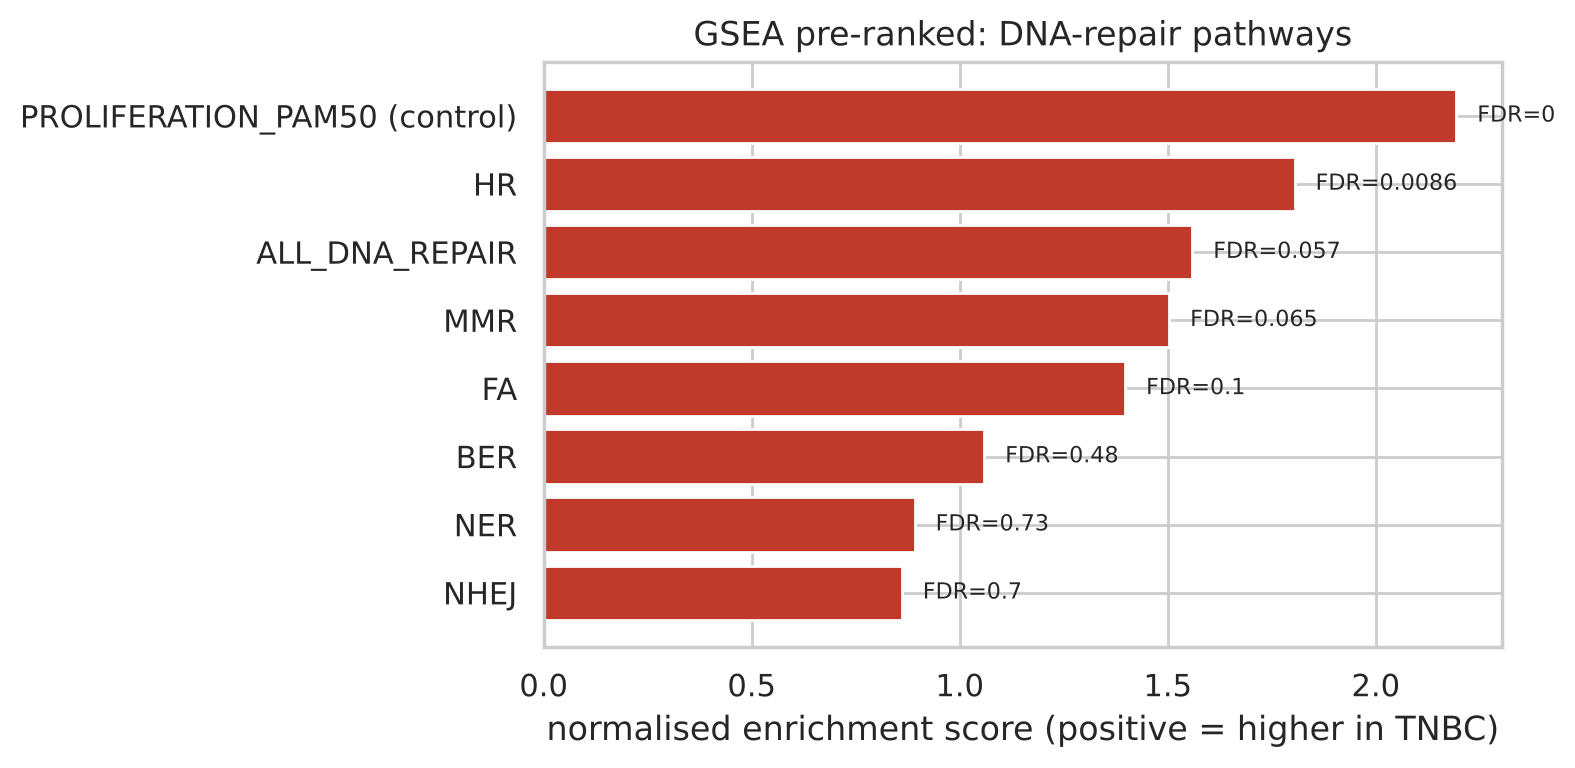

In [22]:
import gseapy as gp
ranking = de["stat"].dropna().sort_values(ascending=False)
ranking.index = ranking.index.astype(str)
gene_sets = {p: [str(i) for i in repair_present if p in repair.loc[i, "pathways"].split(";")] for p in PATHWAYS}
gene_sets["ALL_DNA_REPAIR"] = [str(i) for i in repair_present]
gene_sets["PROLIFERATION_PAM50 (control)"] = [str(i) for i in prolif_ids]
pre = gp.prerank(rnk=ranking, gene_sets=gene_sets, permutation_num=1000, min_size=5, max_size=1000,
                 seed=SEED, threads=os.cpu_count(), outdir=None, verbose=False)
gsea = pre.res2d.copy()
gsea["NES"] = gsea["NES"].astype(float)
gsea["FDR q-val"] = gsea["FDR q-val"].astype(float)
gsea["leading edge (first 12)"] = gsea["Lead_genes"].apply(
    lambda s: ", ".join(SYMBOL.get(int(g), g) for g in str(s).split(";")[:12]))
gsea = gsea.sort_values("NES", ascending=False)
display(gsea[["Term", "NES", "NOM p-val", "FDR q-val", "Tag %", "leading edge (first 12)"]])
gsea.to_csv(os.path.join(RESULTS_DIR, "gsea_prerank_repair_pathways.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#C0392B" if n > 0 else "#2E86C1" for n in gsea["NES"]]
ax.barh(gsea["Term"], gsea["NES"], color=colors)
for i, (n, q) in enumerate(zip(gsea["NES"], gsea["FDR q-val"])):
    ax.text(n + (0.05 if n > 0 else -0.05), i, f"FDR={q:.2g}", va="center", ha="left" if n > 0 else "right", fontsize=8)
ax.axvline(0, c="k", lw=0.8); ax.invert_yaxis()
ax.set(xlabel="normalised enrichment score (positive = higher in TNBC)", title="GSEA pre-ranked: DNA-repair pathways")
plt.tight_layout(); plt.show()

network: 55 genes with ≥1 edge, 288 edges (|ρ| ≥ 0.6; 2 negative)


,n_genes,hub genes (by degree),median log2FC,median adjusted diff,"ρ(module score, proliferation)",AUC TNBC
module,,,,,,
1,25,"RAD51AP1, EXO1, FANCB, BLM, CHEK1, NEIL3, RAD5...",0.74,0.14,0.85,0.80
2,13,"RAD51, UBE2T, EME1, RFC4, PCNA, RAD54B, FEN1, ...",0.64,-0.02,0.88,0.79
3,5,"MSH3, RAD50, POLK, FAN1, RAD17",-0.57,-0.53,-0.31,0.16
4,3,"MPG, FAAP20, NTHL1",-0.08,-0.21,-0.09,0.42
5,2,"ERCC1, XRCC1",0.02,0.03,-0.08,0.48
6,2,"ERCC4, PALB2",-0.18,-0.26,0.06,0.41
7,2,"LIG1, POLD1",0.48,0.11,0.54,0.70
8,2,"RFC5, UNG",0.35,-0.08,0.63,0.64


top hubs by degree: RAD51AP1 (28), EXO1 (27), FANCB (26), CHEK1 (25), BLM (25), NEIL3 (24), RAD54L (24), RAD51 (23), FANCI (22), FANCD2 (21)
top by betweenness: RFC2, SEM1, POLK, EXO1, RAD51AP1, MSH6


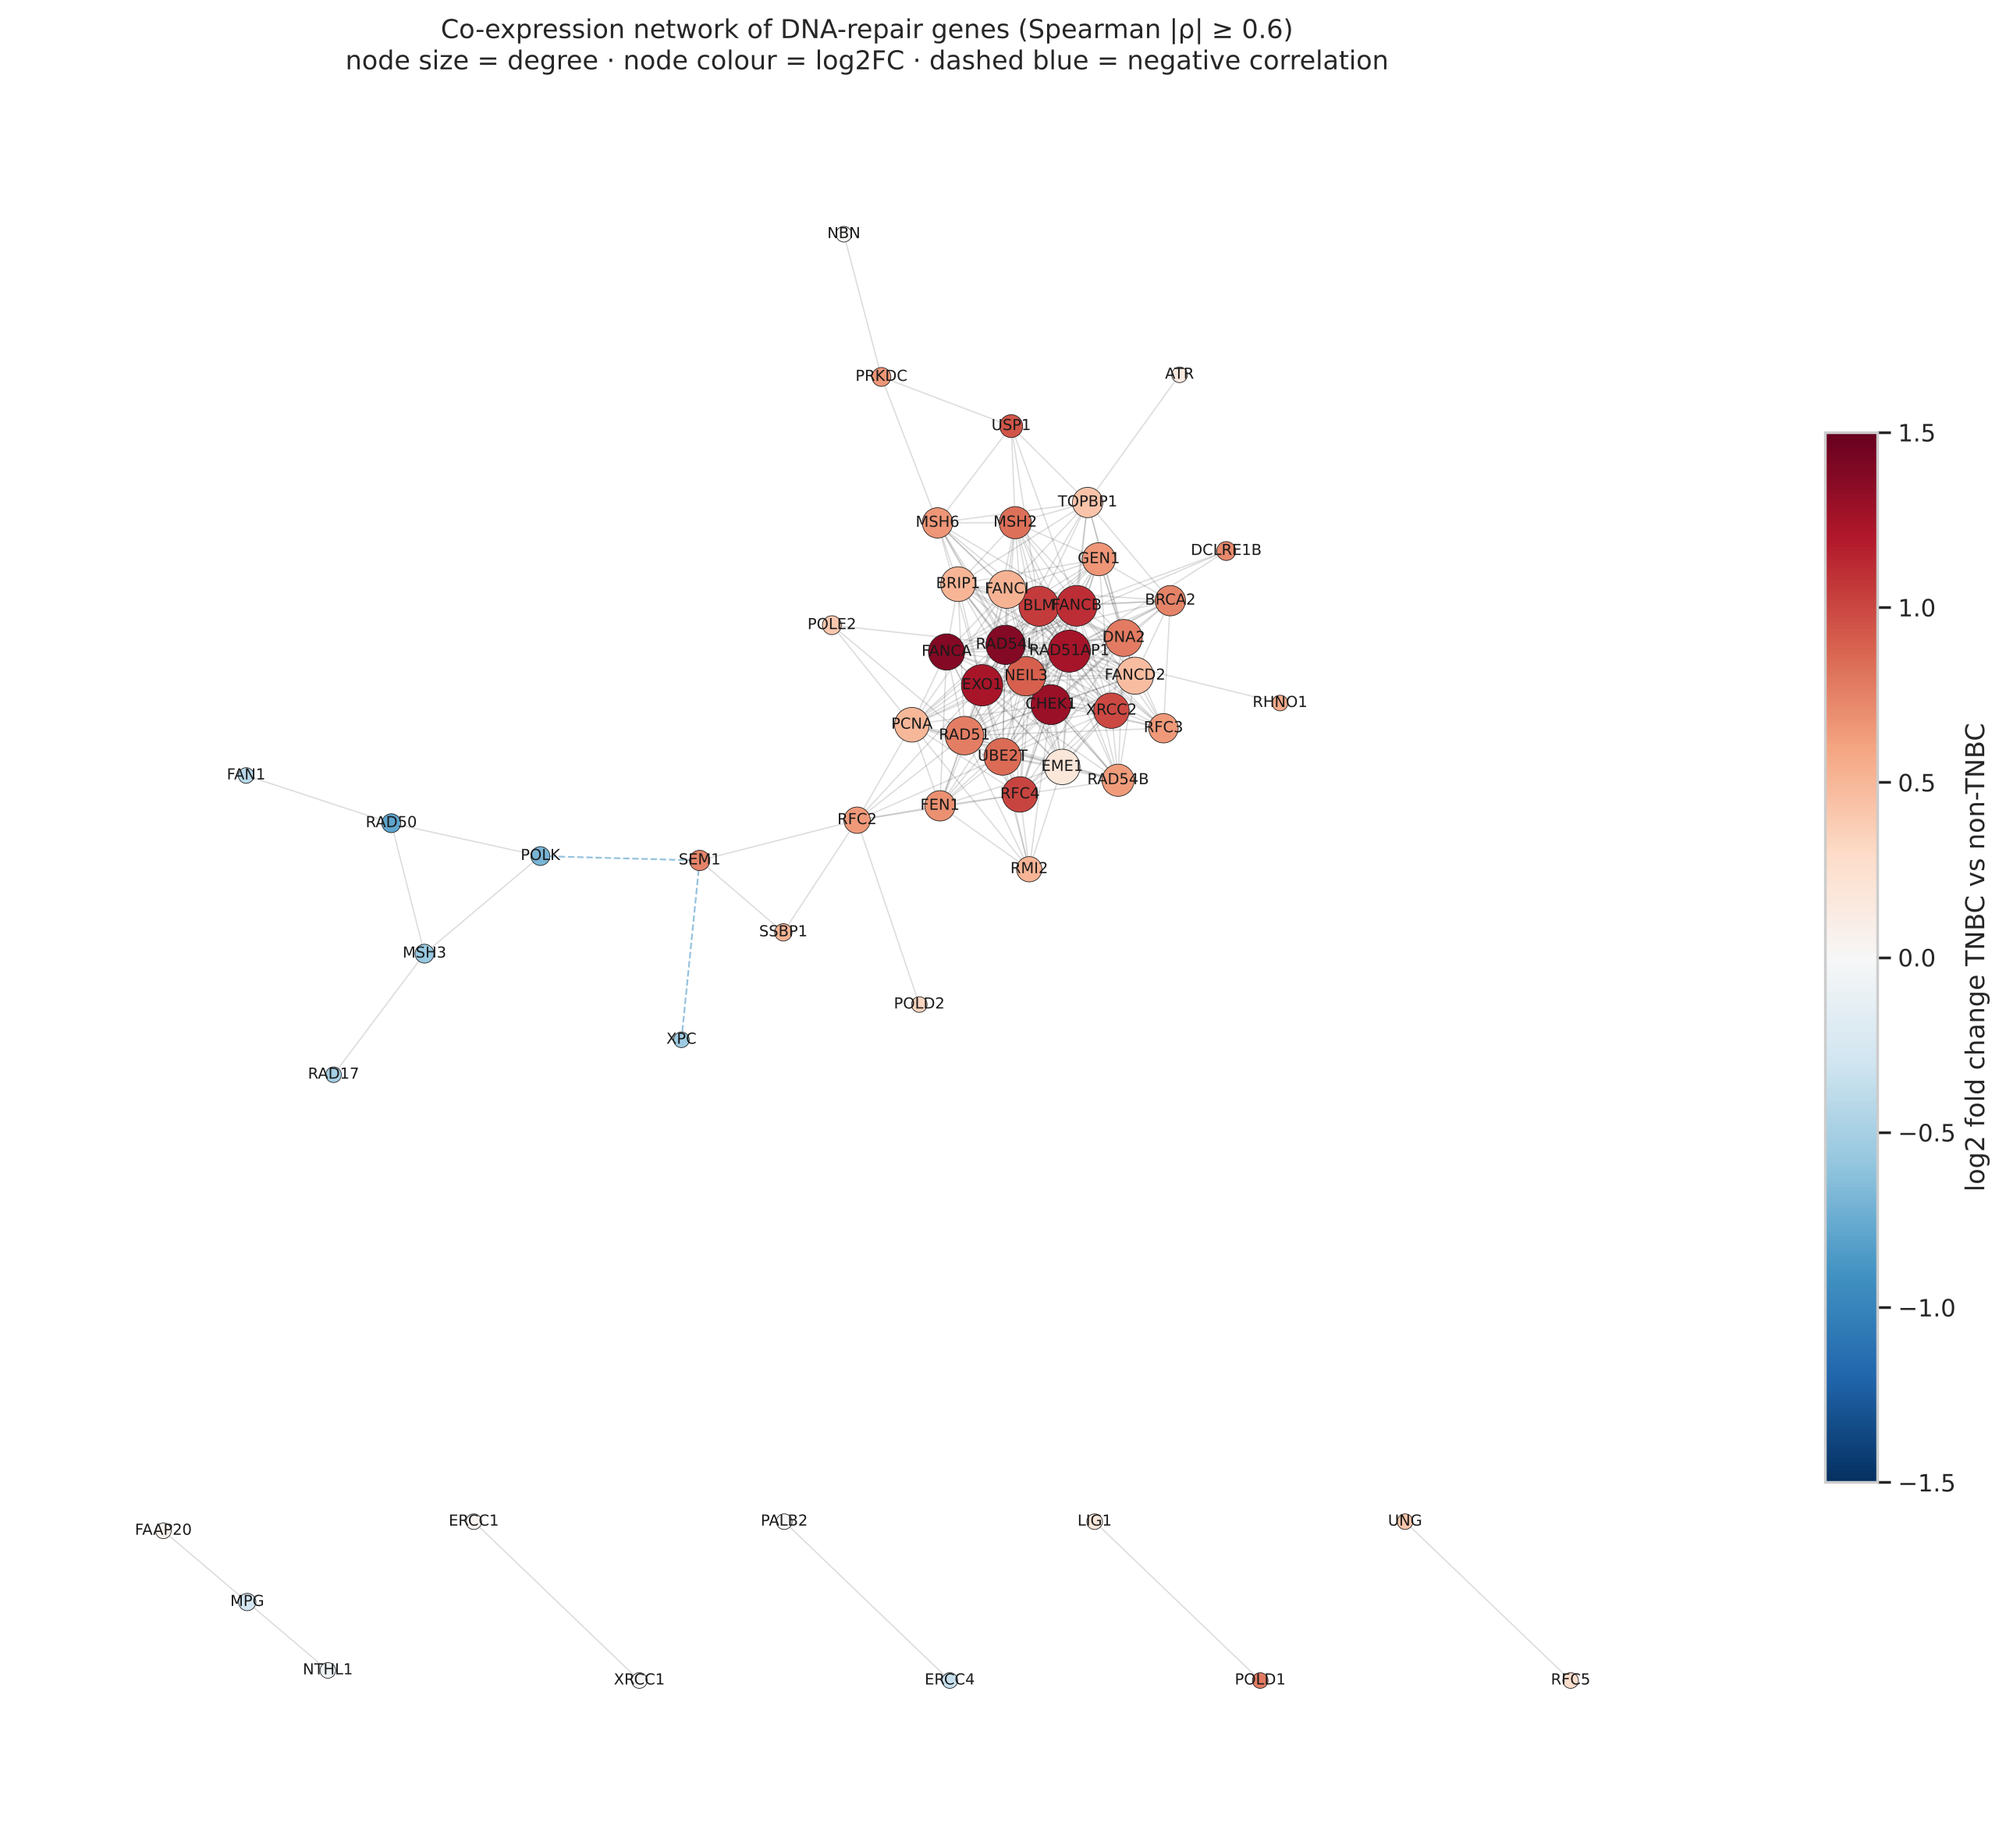

In [23]:
# Co-expression network of DNA-repair genes across all tumours
corr = logn.loc[repair_present].T.corr(method="spearman")
corr.index = corr.columns = repair.loc[repair_present, "symbol"]
THRESH = 0.6
G = nx.Graph()
fc = rep.set_index("symbol")["log2FoldChange"]
adj_fc = adj.set_index("symbol")["diff_adjusted"]
for s in corr.index:
    G.add_node(s, log2fc=fc[s], label=repair.loc[sym2id[s], "label"])
iu = np.triu_indices(len(corr), 1)
for i, j in zip(*iu):
    if abs(corr.values[i, j]) >= THRESH:
        G.add_edge(corr.index[i], corr.index[j], rho=corr.values[i, j], weight=abs(corr.values[i, j]))
G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0])
n_neg = sum(d["rho"] < 0 for _, _, d in G.edges(data=True))
print(f"network: {G.number_of_nodes()} genes with ≥1 edge, {G.number_of_edges()} edges (|ρ| ≥ {THRESH}; {n_neg} negative)")

# modules = groups of genes that rise and fall together, so communities are found on positive correlations only
G_pos = G.edge_subgraph([(u, v) for u, v, d in G.edges(data=True) if d["rho"] > 0]).copy()
communities = sorted(nx.community.greedy_modularity_communities(G_pos, weight="weight"),
                     key=lambda c: (-len(c), sorted(c)))          # deterministic order
mod_rows = []
for k, comm in enumerate(communities, 1):
    members = sorted(comm, key=lambda s: (-G_pos.degree(s), s))
    ids = [sym2id[s] for s in members]
    module_score = z.loc[ids].mean(axis=0)
    mod_rows.append({"module": k, "n_genes": len(members), "hub genes (by degree)": ", ".join(members[:8]),
                     "median log2FC": round(fc[members].median(), 2),
                     "median adjusted diff": round(adj_fc[members].median(), 2),
                     "ρ(module score, proliferation)": round(stats.spearmanr(module_score, prolif_score)[0], 2),
                     "AUC TNBC": round(stats.mannwhitneyu(module_score[y == 1], module_score[y == 0]).statistic
                                       / (y.sum() * (1 - y).sum()), 2)})
    for s in members: G.nodes[s]["module"] = k
modules = pd.DataFrame(mod_rows).set_index("module")
display(modules)
deg = pd.Series(dict(G.degree())).sort_values(ascending=False)
btw = pd.Series(nx.betweenness_centrality(G)).sort_values(ascending=False)
print("top hubs by degree:", ", ".join(f"{g} ({d})" for g, d in deg.head(10).items()))
print("top by betweenness:", ", ".join(btw.head(6).index))

fig, ax = plt.subplots(figsize=(14, 12))
components = sorted(nx.connected_components(G), key=lambda c: (-len(c), sorted(c)))
pos = nx.kamada_kawai_layout(G.subgraph(components[0]), weight=None)      # main component
x0 = -1.0
for comp in components[1:]:                                                 # small components in a row below
    sub = G.subgraph(comp)
    sub_pos = nx.spring_layout(sub, seed=SEED, scale=0.12)
    for n, xy in sub_pos.items():
        pos[n] = np.asarray(xy) + np.array([x0, -1.35])
    x0 += 0.45
pos_edges = [(u, v) for u, v, d in G.edges(data=True) if d["rho"] > 0]
neg_edges = [(u, v) for u, v, d in G.edges(data=True) if d["rho"] < 0]
nx.draw_networkx_edges(G, pos, edgelist=pos_edges, ax=ax, alpha=0.15, width=0.6)
nx.draw_networkx_edges(G, pos, edgelist=neg_edges, ax=ax, alpha=0.5, width=0.8, style="dashed", edge_color="#2E86C1")
nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[40 + 12 * G.degree(n) for n in G.nodes],
                               node_color=[G.nodes[n]["log2fc"] for n in G.nodes], cmap="RdBu_r", vmin=-1.5, vmax=1.5,
                               edgecolors="k", linewidths=0.3)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
plt.colorbar(nodes, ax=ax, label="log2 fold change TNBC vs non-TNBC", shrink=0.6)
ax.set_title("Co-expression network of DNA-repair genes (Spearman |ρ| ≥ 0.6)\nnode size = degree · node colour = log2FC · dashed blue = negative correlation")
ax.axis("off"); plt.tight_layout(); plt.show()

In [ ]:
# Protein-protein interaction (PPI) network from STRING, for the *significant* repair genes
# (rep.call != "not significant", i.e. the 116 genes that pass genome-wide FDR 0.05 — see Stage 5).
# This is independent evidence from the co-expression network above: STRING edges come from
# curated/experimental physical and functional interactions, not from this cohort's expression data,
# so genes that are hubs in BOTH networks are a stronger claim than either network alone.
from io import StringIO

sig_genes = sorted(rep.loc[rep.call != "not significant", "symbol"].unique())
print(f"{len(sig_genes)} significant repair genes queried against STRING")

string_url = "https://string-db.org/api/tsv/network"
string_params = {
    "identifiers": "%0d".join(sig_genes),   # STRING's documented separator between identifiers
    "species": 9606,                         # Homo sapiens
    "required_score": 700,                   # high-confidence interactions only (STRING score is 0-1000)
    "caller_identity": "bioproj_stage6_biological_interpretation",
}
req = urllib.request.Request(
    string_url,
    data=urllib.parse.urlencode(string_params).encode("utf-8"),
    method="POST",
)
with urllib.request.urlopen(req, timeout=30) as resp:
    string_tsv = resp.read().decode("utf-8")

ppi_edges = pd.read_csv(StringIO(string_tsv), sep="\t")[["preferredName_A", "preferredName_B", "score"]].drop_duplicates()
print(f"STRING returned {len(ppi_edges)} high-confidence (score ≥ 700) interactions")

G_ppi = nx.Graph()
G_ppi.add_nodes_from(sig_genes)
for _, r in ppi_edges.iterrows():
    G_ppi.add_edge(r["preferredName_A"], r["preferredName_B"], score=r["score"] / 1000)
G_ppi.remove_nodes_from([n for n in list(G_ppi.nodes) if G_ppi.degree(n) == 0])
print(f"PPI network: {G_ppi.number_of_nodes()} genes with >=1 interaction, {G_ppi.number_of_edges()} edges")

deg_ppi = pd.Series(dict(G_ppi.degree())).sort_values(ascending=False)
btw_ppi = pd.Series(nx.betweenness_centrality(G_ppi)).sort_values(ascending=False)
print("top PPI hubs by degree:", ", ".join(f"{g} ({d})" for g, d in deg_ppi.head(10).items()))
print("top PPI hubs by betweenness:", ", ".join(btw_ppi.head(6).index))

# Compare against the co-expression hubs (deg, btw) computed in the cell above
K = 10
coexp_top, ppi_top = set(deg.head(K).index), set(deg_ppi.head(K).index)
shared = sorted(coexp_top & ppi_top)
print(f"\ntop-{K} hubs in BOTH networks: {', '.join(shared) if shared else '(none)'}")

hub_compare = pd.DataFrame({
    "co-expression degree": deg,
    "co-expression rank": deg.rank(ascending=False, method="min"),
    "PPI degree": deg_ppi.reindex(deg.index).fillna(0).astype(int),
    "PPI rank": deg_ppi.reindex(deg.index).rank(ascending=False, method="min"),
}).sort_values("co-expression rank").head(15)
display(hub_compare)

fig, ax = plt.subplots(figsize=(10, 9))
pos_ppi = nx.kamada_kawai_layout(G_ppi)
nx.draw_networkx_edges(G_ppi, pos_ppi, ax=ax, alpha=0.2, width=0.6)
node_colors = ["#8B1E3F" if n in coexp_top else "#AEB6C4" for n in G_ppi.nodes]
nx.draw_networkx_nodes(G_ppi, pos_ppi, ax=ax, node_size=[40 + 20 * G_ppi.degree(n) for n in G_ppi.nodes],
                        node_color=node_colors, edgecolors="k", linewidths=0.3)
nx.draw_networkx_labels(G_ppi, pos_ppi, ax=ax, font_size=7)
ax.set_title(f"STRING PPI network of significant repair genes (score ≥ 0.7)\nred = also a top-{K} co-expression hub")
ax.axis("off"); plt.tight_layout(); plt.show()

BRCA1 below the 5th percentile of non-TNBC: 16.6% of TNBC vs 5.1% of non-TNBC
BRCA1 median log2 expression: TNBC 9.97, non-TNBC 9.95
BRCA1 relative to its proliferation-expected level: TNBC median residual -0.25, non-TNBC 0.09; Mann–Whitney p = 7.8e-09


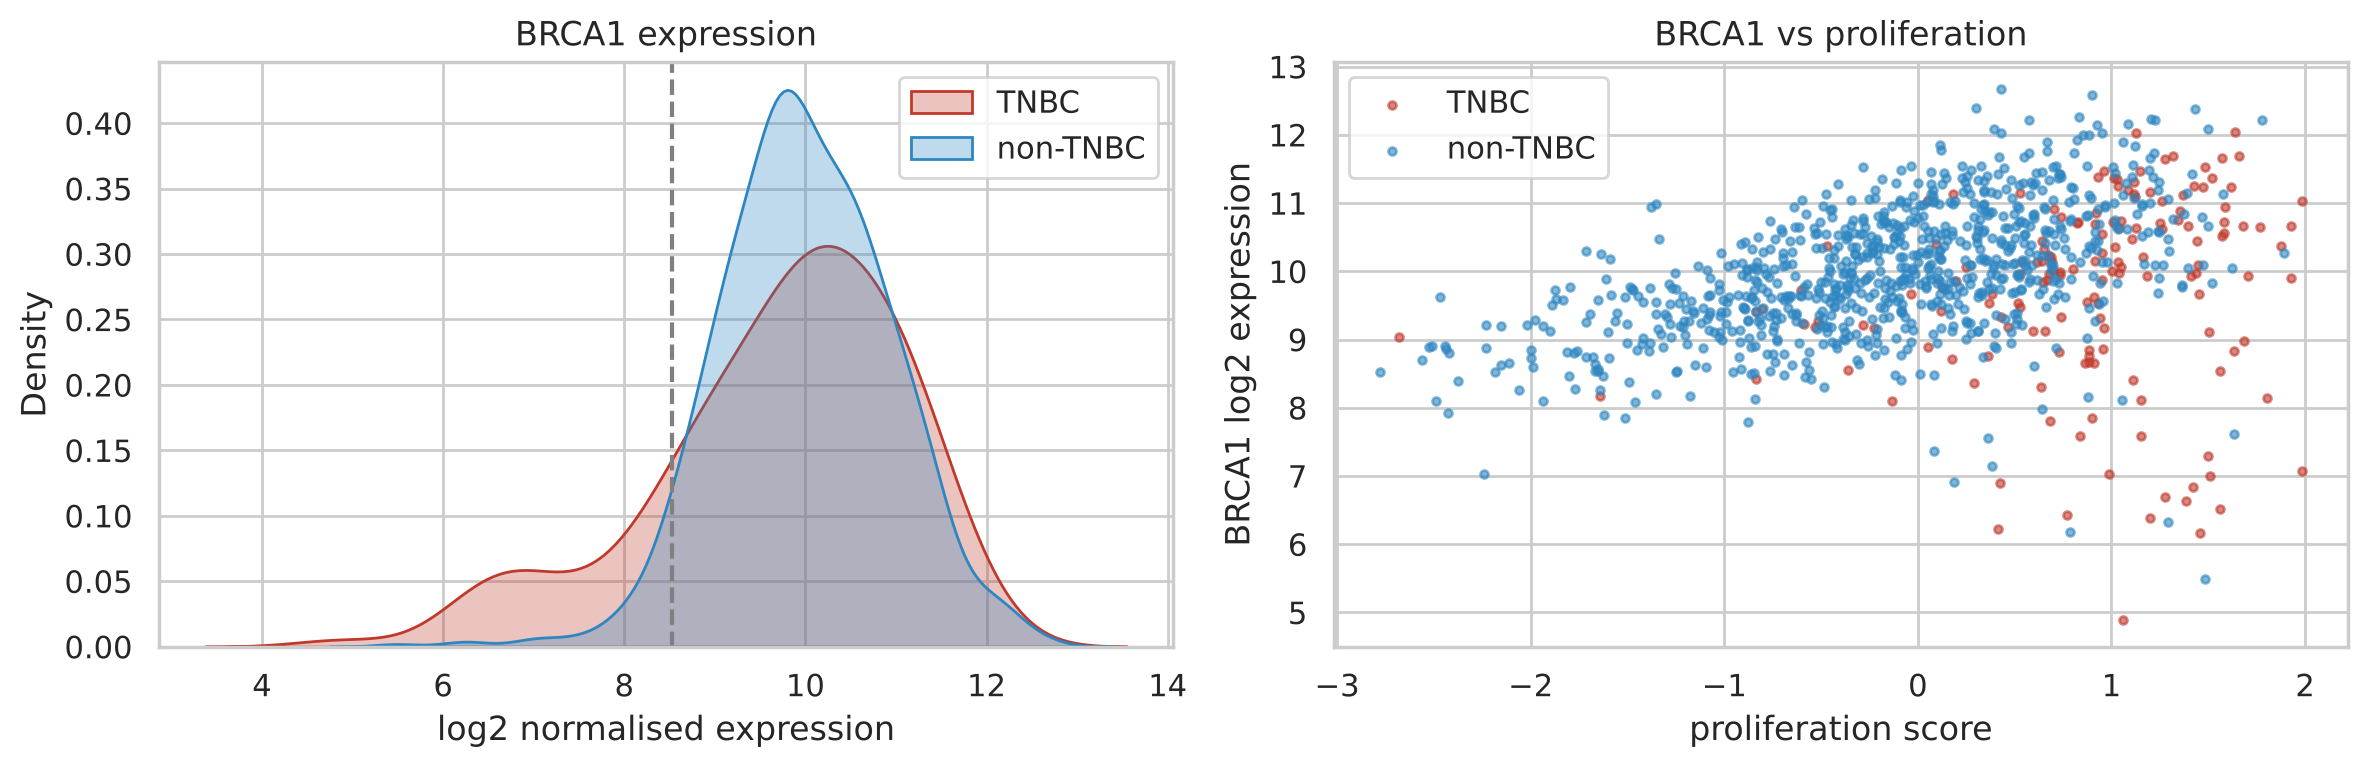

In [24]:
# BRCA1: TNBC is known to contain BRCA1-deficient tumours (germline mutation or promoter methylation).
# Expression alone cannot show deficiency, but a low-expression tail would be consistent with silencing.
b1 = logn.loc[sym2id["BRCA1"]]
cut = b1[y == 0].quantile(0.05)
low_t, low_n = (b1[y == 1] < cut).mean(), (b1[y == 0] < cut).mean()
print(f"BRCA1 below the 5th percentile of non-TNBC: {low_t:.1%} of TNBC vs {low_n:.1%} of non-TNBC")
print(f"BRCA1 median log2 expression: TNBC {b1[y == 1].median():.2f}, non-TNBC {b1[y == 0].median():.2f}")
b1_res = pd.Series(sm.OLS(b1.values, sm.add_constant(prolif_score.values)).fit().resid, index=b1.index)
print(f"BRCA1 relative to its proliferation-expected level: TNBC median residual {b1_res[y == 1].median():.2f}, "
      f"non-TNBC {b1_res[y == 0].median():.2f}; "
      f"Mann–Whitney p = {stats.mannwhitneyu(b1_res[y == 1], b1_res[y == 0]).pvalue:.2g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for g, col in GROUP_COLORS.items():
    sns.kdeplot(b1[cohort.group == g], ax=axes[0], fill=True, alpha=0.3, color=col, label=g, common_norm=False)
    axes[1].scatter(prolif_score[cohort.group == g], b1[cohort.group == g], s=8, alpha=0.6, c=col, label=g)
axes[0].axvline(cut, ls="--", c="grey"); axes[0].set(title="BRCA1 expression", xlabel="log2 normalised expression"); axes[0].legend()
axes[1].set(title="BRCA1 vs proliferation", xlabel="proliferation score", ylabel="BRCA1 log2 expression"); axes[1].legend()
plt.tight_layout(); plt.show()

### Literature comparison

| Our finding | What the literature says | Agreement |
|---|---|---|
| TNBC separate from non-TNBC across the whole transcriptome and are far more proliferative (PCA; proliferation z 0.95 vs −0.09) | Most TNBC are basal-like, the most proliferative intrinsic subtype (Perou et al., 2000; TCGA Network, 2012) | Agrees |
| HR, FA and checkpoint genes (*FANCA, RAD54L, CHEK1, RAD51AP1, EXO1, BLM*) are the most up-regulated repair genes in TNBC | The basal-like TNBC subtypes BL1/BL2 have high cell-cycle and DNA-damage-response gene expression (Lehmann et al., 2011) | Agrees |
| Most of that up-regulation disappears after adjusting for proliferation; the up-regulated genes form one module tied to proliferation | Many replication-coupled repair genes are periodically expressed in the cell cycle and appear in tumour proliferation signatures (Whitfield et al., 2002) | Agrees, and explains our result |
| *BRCA1* is lower than proliferation predicts in TNBC, with a low-expression tail in 16.6% of TNBC | Sporadic TNBC often share features of *BRCA1*-mutant cancers ("BRCAness"), and *BRCA1* can be silenced by promoter methylation in sporadic breast tumours (Turner et al., 2007; Esteller et al., 2000; Foulkes et al., 2010) | Consistent; needs methylation or mutation data to confirm |
| HR genes such as *RAD51* and *BRCA2* are *higher* in TNBC, the subtype most associated with HR deficiency | HR deficiency is a functional state, detected through mutations, methylation or genomic "scars" (Knijnenburg et al., 2018; Davies et al., 2017), not mRNA levels | Paradox explained: expression ≠ function |
| TNBC patients are younger and more often Black / African American | Basal-like breast cancer is more prevalent in younger African-American women (Carey et al., 2006) | Agrees |

### References

Every reference below was checked against the publisher/journal record. One correction was found: the
literature table previously cited the BRCA1-dysfunction paper as "Turner et al., 2004" — the paper was
published online 2 Oct 2006 and in print in 2007, so it is cited here as **Turner et al., 2007**.

1. Perou CM, Sørlie T, Eisen MB, et al. Molecular portraits of human breast tumours. *Nature*. 2000;406(6797):747–752. doi: [10.1038/35021093](https://doi.org/10.1038/35021093)
2. The Cancer Genome Atlas Network. Comprehensive molecular portraits of human breast tumours. *Nature*. 2012;490(7418):61–70. doi: [10.1038/nature11412](https://doi.org/10.1038/nature11412)
3. Whitfield ML, Sherlock G, Saldanha AJ, et al. Identification of genes periodically expressed in the human cell cycle and their expression in tumors. *Mol Biol Cell*. 2002;13(6):1977–2000. doi: [10.1091/mbc.02-02-0030](https://doi.org/10.1091/mbc.02-02-0030)
4. Lehmann BD, Bauer JA, Chen X, et al. Identification of human triple-negative breast cancer subtypes and preclinical models for selection of targeted therapies. *J Clin Invest*. 2011;121(7):2750–2767. doi: [10.1172/JCI45014](https://doi.org/10.1172/JCI45014)
5. Turner NC, Reis-Filho JS, Russell AM, et al. BRCA1 dysfunction in sporadic basal-like breast cancer. *Oncogene*. 2007;26:2126–2132 (published online 2 Oct 2006). doi: [10.1038/sj.onc.1210014](https://doi.org/10.1038/sj.onc.1210014) — *corrected from "2004" in the table above.*
6. Esteller M, Silva JM, Dominguez G, et al. Promoter hypermethylation and BRCA1 inactivation in sporadic breast and ovarian tumors. *J Natl Cancer Inst*. 2000;92(7):564–569. doi: [10.1093/jnci/92.7.564](https://doi.org/10.1093/jnci/92.7.564)
7. Foulkes WD, Smith IE, Reis-Filho JS. Triple-negative breast cancer. *N Engl J Med*. 2010;363(20):1938–1948. doi: [10.1056/NEJMra1001389](https://doi.org/10.1056/NEJMra1001389)
8. Knijnenburg TA, Wang L, Zimmermann MT, et al. Genomic and molecular landscape of DNA damage repair deficiency across The Cancer Genome Atlas. *Cell Rep*. 2018;23(1):239–254.e6. doi: [10.1016/j.celrep.2018.03.076](https://doi.org/10.1016/j.celrep.2018.03.076)
9. Davies H, Glodzik D, Morganella S, et al. HRDetect is a predictor of BRCA1 and BRCA2 deficiency based on mutational signatures. *Nat Med*. 2017;23(4):517–525. doi: [10.1038/nm.4292](https://doi.org/10.1038/nm.4292)
10. Carey LA, Perou CM, Livasy CA, et al. Race, breast cancer subtypes, and survival in the Carolina Breast Cancer Study. *JAMA*. 2006;295(21):2492–2502. doi: [10.1001/jama.295.21.2492](https://doi.org/10.1001/jama.295.21.2492)

**Interpretation (Stage 6).**

* **Pathway enrichment:** the proliferation control is the most enriched set (NES 2.19, FDR < 0.001), which shows the method works. Among repair pathways, only **homologous recombination is significantly enriched towards TNBC** (NES 1.81, FDR 0.009). MMR (NES 1.50, FDR 0.065), all repair genes together (NES 1.56, FDR 0.057) and FA (NES 1.40, FDR 0.10) point the same way without reaching significance. BER, NER and NHEJ show no enrichment (FDR ≥ 0.48). The HR leading-edge genes (*CHEK1, RFC4, RAD54L, RAD51AP1, RAD51B, POLD1 …*) are the same genes highlighted in Stage 5.
* **Co-expression network:** 55 repair genes have at least one strong co-expression partner. Most of them form one dense core made of two modules (25 + 13 genes) whose hubs are *RAD51AP1, EXO1, FANCB, BLM, CHEK1, NEIL3, RAD54L* and *RAD51*. Both module scores correlate strongly with proliferation (ρ = 0.85 and 0.88) and are higher in TNBC (AUC 0.80 and 0.79). After proliferation adjustment, though, their median TNBC difference is close to zero (0.14 and −0.02). This is a **single replication-coupled HR/FA programme** that switches on in dividing cells, and TNBC divide more. A separate small module (*MSH3, RAD50, POLK, FAN1, RAD17*) behaves differently. It is **lower in TNBC** (AUC 0.16, i.e. higher in non-TNBC), not tied to proliferation (ρ = −0.31), and keeps its difference after adjustment (median −0.53). This is the clearest proliferation-independent repair difference in the data.
* **PPI vs co-expression hubs:** `# TODO (Kian) — replace with what your own run prints.` Run the new STRING cell above in Colab and read off: (a) how many of the top-10 co-expression hubs (`RAD51AP1, EXO1, FANCB, BLM, CHEK1, …`) are *also* top-10 STRING PPI hubs — printed as "top-10 hubs in BOTH networks"; (b) name any gene that is a hub in one network but not the other, and say what that means (a co-expression-only hub is "co-regulated but not known to physically interact"; a PPI-only hub is "interacts physically but isn't co-regulated here"). A gene that is a hub in *both* networks (shared regulation **and** shared physical interaction) is the strongest candidate for a real functional module — call that out by name once you have it.
* **BRCA1:** median *BRCA1* expression is the same in both groups (9.97 vs 9.95), but TNBC have a long low tail: 16.6% of TNBC fall below the 5th percentile of non-TNBC (5.1% expected). Given how proliferative TNBC are, *BRCA1* is lower than expected (p = 7.8 × 10⁻⁹). This fits a subset of TNBC in which *BRCA1* is silenced (the BRCAness phenotype), while most TNBC have normal *BRCA1* driven up by proliferation. Expression alone cannot prove repair deficiency.
* **Overall:** our results support the literature on direction (HR/FA up in TNBC, a BRCA1-low subset) but show that **most of the repair difference is proliferation**, a point often left out when repair-gene expression is compared between subtypes.

## Stage 7 · Machine learning

*Stage lead: Danni Podho*

**Task:** classify a tumour as TNBC or non-TNBC from the expression of the DNA-repair genes only. The receptor genes that *define* the label (*ESR1, PGR, ERBB2*) are not in the feature set, so the model cannot simply read off the answer.

**Design:** a stratified 80/20 train/test split. All model selection uses 5-fold cross-validation on the training set only, and the test set is used once at the end. Scaling happens inside the pipeline, so no information leaks from validation folds. Classes are imbalanced (~16% TNBC), so we use `class_weight="balanced"` and report **ROC-AUC, PR-AUC, balanced accuracy, sensitivity and specificity**, not plain accuracy.

**Baselines.** A model is only interesting if it beats these:

1. **Majority class:** always predict non-TNBC.
2. **Proliferation only:** logistic regression on the 1-number PAM50 proliferation score.
3. **Random genes:** the same model on 30 random sets of the same number of expressed non-repair genes. This tests whether repair genes are *special* or whether any genes would do.

In [25]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, recall_score,
                             confusion_matrix, roc_curve, precision_recall_curve, f1_score)

X_rep = logn.loc[repair_present].T.copy()
X_rep.columns = repair.loc[repair_present, "symbol"].values
X_pro = prolif_score.to_frame("proliferation")
idx_train, idx_test = train_test_split(X_rep.index, test_size=0.2, stratify=y, random_state=SEED)
y_train, y_test = y[idx_train], y[idx_test]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"train: {len(idx_train)} tumours ({y_train.sum()} TNBC) | test: {len(idx_test)} tumours ({y_test.sum()} TNBC)")

def logreg(C=1.0):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=5000))

# Tune the two candidate models with 5-fold CV on the training set
lr_search = GridSearchCV(logreg(), {"logisticregression__C": [0.001, 0.01, 0.1, 1.0]}, cv=cv, scoring="roc_auc").fit(X_rep.loc[idx_train], y_train)
rf_search = GridSearchCV(RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
                         {"min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.3]}, cv=cv, scoring="roc_auc").fit(X_rep.loc[idx_train], y_train)
print("logistic regression best:", lr_search.best_params_, f"CV ROC-AUC {lr_search.best_score_:.3f}")
print("random forest best      :", rf_search.best_params_, f"CV ROC-AUC {rf_search.best_score_:.3f}")

train: 804 tumours (125 TNBC) | test: 202 tumours (32 TNBC)


logistic regression best: {'logisticregression__C': 0.01} CV ROC-AUC 0.970
random forest best      : {'max_features': 0.3, 'min_samples_leaf': 1} CV ROC-AUC 0.951


In [26]:
# Baselines evaluated with the same CV folds on the training set
cv_rows = []
def cv_auc(model, X):
    return cross_val_score(model, X.loc[idx_train], y_train, cv=cv, scoring="roc_auc")

cv_rows.append({"model": "Majority class (dummy)", "CV ROC-AUC": cv_auc(DummyClassifier(strategy="most_frequent"), X_pro).mean()})
cv_rows.append({"model": "Proliferation score only (LR)", "CV ROC-AUC": cv_auc(logreg(), X_pro).mean()})
best_C = lr_search.best_params_["logisticregression__C"]
pool = logn.index.difference(repair_present).difference(list(MARKERS.values())[:3])
rand_aucs = []
rng = np.random.default_rng(SEED)
for _ in range(30):
    genes = rng.choice(pool, len(repair_present), replace=False)
    rand_aucs.append(cv_auc(logreg(best_C), logn.loc[genes].T).mean())
cv_rows.append({"model": f"Random {len(repair_present)} non-repair genes (LR, mean of 30 sets)", "CV ROC-AUC": np.mean(rand_aucs)})
cv_rows.append({"model": "DNA-repair genes (LR)", "CV ROC-AUC": lr_search.best_score_})
cv_rows.append({"model": "DNA-repair genes (random forest)", "CV ROC-AUC": rf_search.best_score_})
X_both = X_rep.join(X_pro)
cv_rows.append({"model": "DNA-repair genes + proliferation (LR)", "CV ROC-AUC": cv_auc(logreg(best_C), X_both).mean()})
cv_table = pd.DataFrame(cv_rows).set_index("model").round(3)
display(cv_table)
print(f"random gene sets: CV ROC-AUC range {min(rand_aucs):.3f}–{max(rand_aucs):.3f}; "
      f"repair genes beat {np.mean(np.array(rand_aucs) < lr_search.best_score_):.0%} of the 30 random sets")

,CV ROC-AUC
model,
Majority class (dummy),0.500
Proliferation score only (LR),0.844
"Random 148 non-repair genes (LR, mean of 30 sets)",0.966
DNA-repair genes (LR),0.970
DNA-repair genes (random forest),0.951
DNA-repair genes + proliferation (LR),0.970


random gene sets: CV ROC-AUC range 0.960–0.972; repair genes beat 93% of the 30 random sets


### Repeated cross-validation of the baselines
One 5-fold split gives a single number per model. Repeating 5-fold CV five times with different shuffles (25 fits per model, training set only) shows how much each score varies. We need that to judge whether the small gap between repair genes and random genes is real. Every model is scored on the **same 25 splits**, so the scores can be compared fold by fold.

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def rcv_auc(model, X):
    return cross_val_score(model, X.loc[idx_train], y_train, cv=rcv, scoring="roc_auc", n_jobs=-1)

rcv_scores = {
    "Majority class (dummy)": rcv_auc(DummyClassifier(strategy="most_frequent"), X_pro),
    "Proliferation score only (LR)": rcv_auc(logreg(), X_pro),
    "DNA-repair genes (LR)": rcv_auc(logreg(best_C), X_rep),
    "DNA-repair genes (random forest)": rcv_auc(rf_search.best_estimator_, X_rep),
    "DNA-repair genes + proliferation (LR)": rcv_auc(logreg(best_C), X_both),
}

# 30 random sets of non-repair genes, each scored on the same 25 splits.
# A separate random generator keeps the shared `rng` (used later for the bootstrap CI) unchanged.
my_rng = np.random.default_rng(SEED)
random_fold_scores = np.array([rcv_auc(logreg(best_C), logn.loc[my_rng.choice(pool, len(repair_present), replace=False)].T)
                               for _ in range(30)])                     # shape: 30 sets x 25 folds
rcv_scores[f"Random {len(repair_present)} genes (LR, 30 sets)"] = random_fold_scores.ravel()

rcv_table = pd.DataFrame({name: {"mean ROC-AUC": s.mean(), "SD across folds": s.std(ddof=1),
                                 "min": s.min(), "max": s.max()} for name, s in rcv_scores.items()}).T.round(3)
display(rcv_table)

repair_lr = rcv_scores["DNA-repair genes (LR)"]
set_means = random_fold_scores.mean(axis=1)
diff = repair_lr - random_fold_scores                                   # paired: same folds
print(f"Repair-gene LR mean AUC {repair_lr.mean():.3f} is higher than {np.mean(set_means < repair_lr.mean()):.0%} "
      f"of the 30 random-set means (random sets: {set_means.mean():.3f} ± {set_means.std(ddof=1):.3f}).")
print(f"Paired difference, repair minus random (same folds): {diff.mean():+.4f} AUC "
      f"(SD {diff.std(ddof=1):.4f}); repair genes win in {np.mean(diff > 0):.0%} of set-fold pairs.")

fig, ax = plt.subplots(figsize=(10, 4.5))
order_m = list(rcv_scores)
sns.boxplot(data=[rcv_scores[m] for m in order_m], orient="h", ax=ax, color="#D6EAF8", fliersize=2)
ax.set_yticks(range(len(order_m)))
ax.set_yticklabels(order_m)
ax.set(xlabel="ROC-AUC (5 × 5 repeated CV, training set)", title="Model comparison with fold-to-fold variation")
ax.axvline(0.5, ls="--", c="grey", lw=0.8)
plt.tight_layout(); plt.show()

In [27]:
# Final evaluation on the untouched test set
final_models = {
    "Majority class (dummy)": (DummyClassifier(strategy="most_frequent"), X_pro),
    "Proliferation score only (LR)": (logreg(), X_pro),
    "DNA-repair genes (LR)": (lr_search.best_estimator_, X_rep),
    "DNA-repair genes (random forest)": (rf_search.best_estimator_, X_rep),
}
test_rows, curves = [], {}
for name, (model, X) in final_models.items():
    model.fit(X.loc[idx_train], y_train)
    prob = model.predict_proba(X.loc[idx_test])[:, 1]
    pred = model.predict(X.loc[idx_test])
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    test_rows.append({"model": name, "ROC-AUC": roc_auc_score(y_test, prob), "PR-AUC": average_precision_score(y_test, prob),
                      "balanced accuracy": balanced_accuracy_score(y_test, pred),
                      "sensitivity (TNBC recall)": recall_score(y_test, pred, zero_division=0),
                      "specificity": tn_ / (tn_ + fp_), "F1 (TNBC)": f1_score(y_test, pred, zero_division=0)})
    curves[name] = prob
test_table = pd.DataFrame(test_rows).set_index("model").round(3)
display(test_table)
test_table.to_csv(os.path.join(RESULTS_DIR, "ml_test_metrics.csv"))

# Bootstrap 95% CI for the test ROC-AUC of the repair-gene LR
boot = []
p_lr = curves["DNA-repair genes (LR)"]
yt = y_test.values
for _ in range(2000):
    b = rng.integers(0, len(yt), len(yt))
    if yt[b].min() != yt[b].max():
        boot.append(roc_auc_score(yt[b], p_lr[b]))
print(f"Repair-gene LR test ROC-AUC 95% bootstrap CI: {np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f}")

,ROC-AUC,PR-AUC,balanced accuracy,sensitivity (TNBC recall),specificity,F1 (TNBC)
model,,,,,,
Majority class (dummy),0.500,0.158,0.500,0.000,1.000,0.000
Proliferation score only (LR),0.835,0.563,0.789,0.812,0.765,0.531
DNA-repair genes (LR),0.926,0.662,0.871,0.812,0.929,0.743
DNA-repair genes (random forest),0.915,0.663,0.698,0.438,0.959,0.528


Repair-gene LR test ROC-AUC 95% bootstrap CI: 0.873–0.967


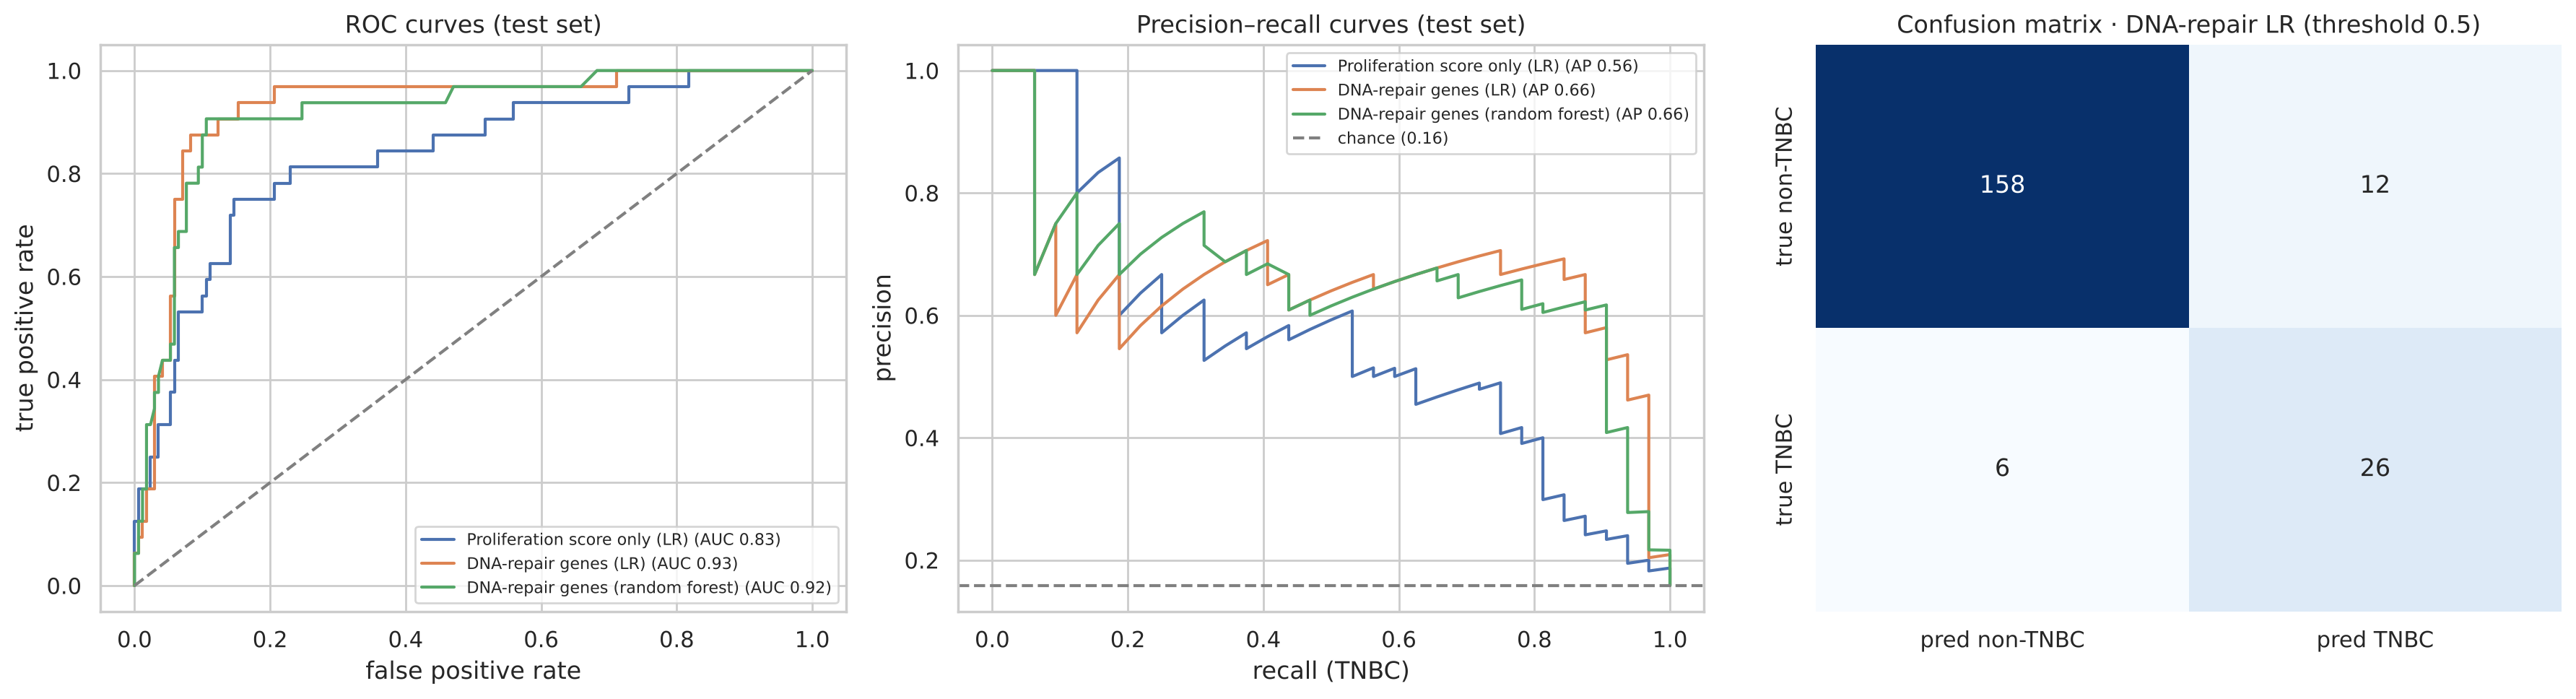

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, prob in curves.items():
    if name.startswith("Majority"): continue
    fpr, tpr, _ = roc_curve(y_test, prob); axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, prob):.2f})")
    pr, rc, _ = precision_recall_curve(y_test, prob); axes[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(y_test, prob):.2f})")
axes[0].plot([0, 1], [0, 1], ls="--", c="grey"); axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curves (test set)")
axes[1].axhline(y_test.mean(), ls="--", c="grey", label=f"chance ({y_test.mean():.2f})")
axes[1].set(xlabel="recall (TNBC)", ylabel="precision", title="Precision–recall curves (test set)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
cm = confusion_matrix(y_test, (p_lr >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["pred non-TNBC", "pred TNBC"], yticklabels=["true non-TNBC", "true TNBC"])
axes[2].set_title("Confusion matrix · DNA-repair LR (threshold 0.5)")
plt.tight_layout(); plt.show()

### Tuning the random forest's decision threshold
At the default 0.5 threshold the random forest finds few TNBC tumours: with only ~16% TNBC its probabilities rarely reach 0.5. We choose a better threshold using **out-of-fold predictions on the training set only**, then apply that single threshold to the test set once. This keeps the test set untouched by the tuning.

In [ ]:
from sklearn.model_selection import cross_val_predict

rf_oof = cross_val_predict(rf_search.best_estimator_, X_rep.loc[idx_train], y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
ba_oof = np.array([balanced_accuracy_score(y_train, (rf_oof >= t).astype(int)) for t in thresholds])
t_best = float(thresholds[ba_oof.argmax()])
print(f"threshold chosen on training out-of-fold predictions: {t_best:.2f} "
      f"(training balanced accuracy {ba_oof.max():.3f} vs {ba_oof[thresholds == 0.5][0]:.3f} at 0.50)")

p_rf = curves["DNA-repair genes (random forest)"]
thr_rows = []
for label, t in [("0.50 (default)", 0.5), (f"{t_best:.2f} (tuned on training data)", t_best)]:
    pred = (p_rf >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    thr_rows.append({"RF threshold": label, "balanced accuracy": balanced_accuracy_score(y_test, pred),
                     "sensitivity (TNBC recall)": tp_ / (tp_ + fn_), "specificity": tn_ / (tn_ + fp_),
                     "F1 (TNBC)": f1_score(y_test, pred, zero_division=0), "TNBC found": f"{tp_} of {tp_ + fn_}"})
thr_table = pd.DataFrame(thr_rows).set_index("RF threshold").round(3)
display(thr_table)
print(f"test ROC-AUC is unchanged by the threshold: {roc_auc_score(y_test, p_rf):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thresholds, ba_oof, c="#1F618D")
ax.axvline(t_best, ls="--", c="#C0392B", label=f"chosen threshold {t_best:.2f}")
ax.axvline(0.5, ls=":", c="grey", label="default 0.50")
ax.set(xlabel="decision threshold", ylabel="balanced accuracy (out-of-fold)", title="Random forest: choosing the threshold on training data")
ax.legend(); plt.tight_layout(); plt.show()

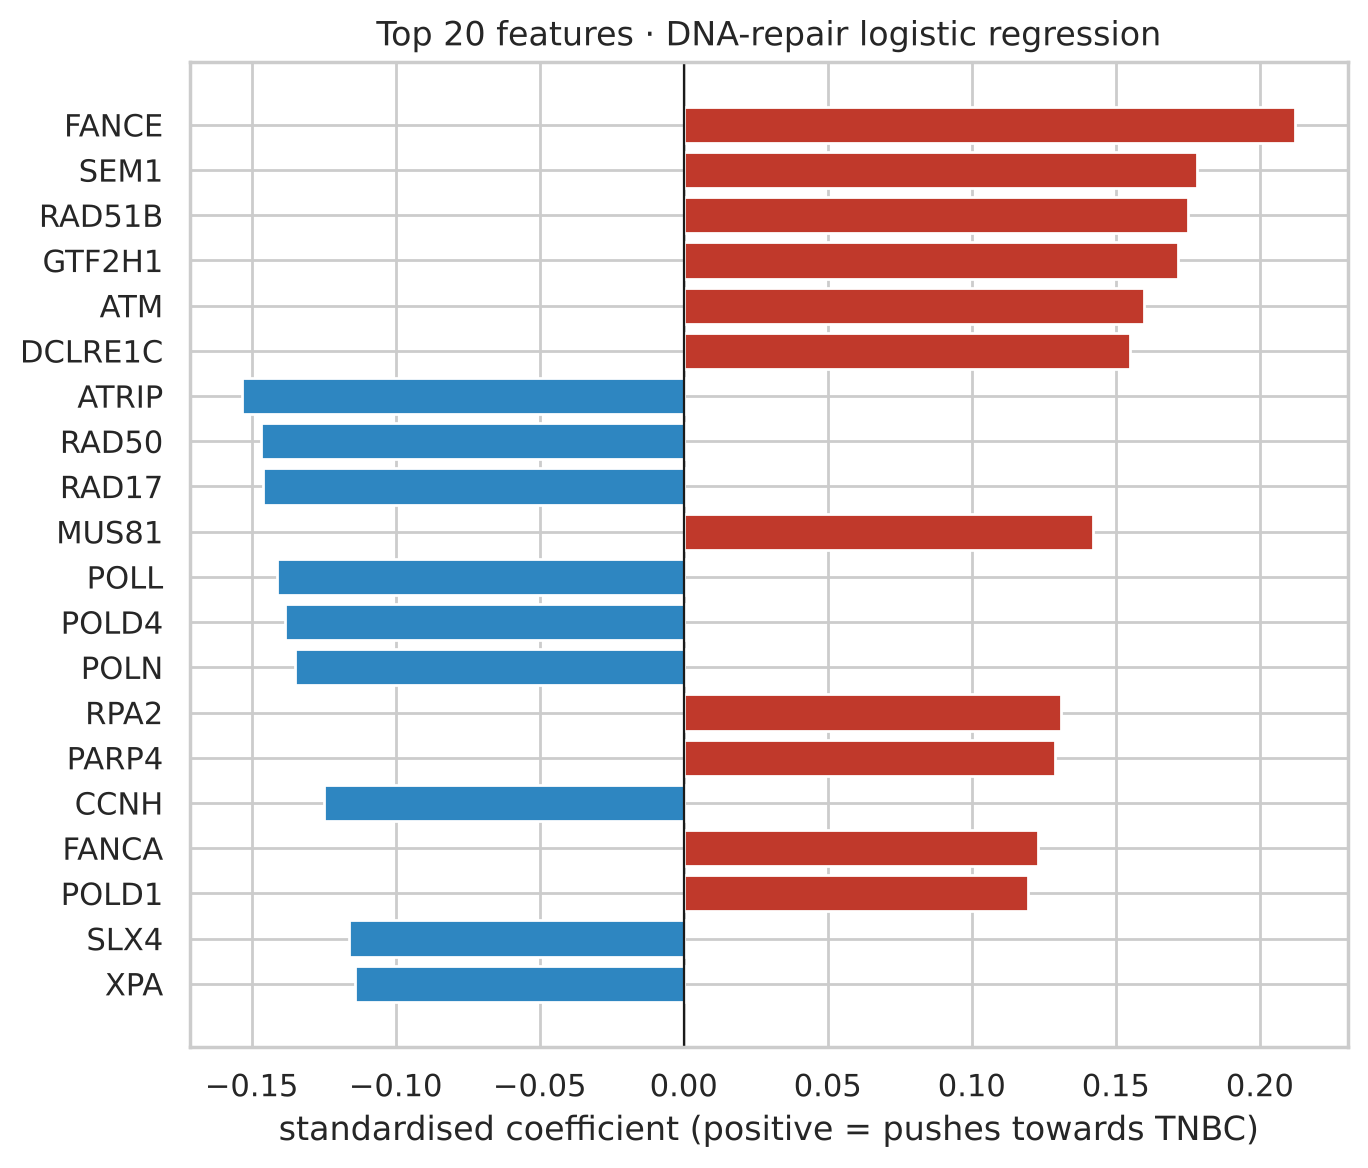

Spearman correlation between LR coefficient and adjusted TNBC difference: 0.84


In [29]:
# Which repair genes does the logistic regression rely on? (standardised coefficients)
coef = pd.Series(lr_search.best_estimator_.named_steps["logisticregression"].coef_[0], index=X_rep.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:20])
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index[::-1], top.values[::-1], color=["#C0392B" if v > 0 else "#2E86C1" for v in top.values[::-1]])
ax.axvline(0, c="k", lw=0.8)
ax.set(xlabel="standardised coefficient (positive = pushes towards TNBC)", title="Top 20 features · DNA-repair logistic regression")
plt.tight_layout(); plt.show()
print("Spearman correlation between LR coefficient and adjusted TNBC difference:",
      round(stats.spearmanr(coef, adj.set_index("symbol").loc[coef.index, "diff_adjusted"])[0], 2))

### Permutation importance (test set)
Coefficients show what the model learned. Permutation importance asks what it actually *uses* on unseen data: shuffle one gene in the test set and measure how much ROC-AUC drops (30 shuffles per gene).

In [ ]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(lr_search.best_estimator_, X_rep.loc[idx_test], y_test, scoring="roc_auc",
                            n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"drop in ROC-AUC": pi.importances_mean, "SD": pi.importances_std}, index=X_rep.columns)
imp = imp.sort_values("drop in ROC-AUC", ascending=False)
top_pi = imp.head(15)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top_pi.index[::-1], top_pi["drop in ROC-AUC"][::-1], xerr=top_pi["SD"][::-1], color="#5D6D7E")
ax.set(xlabel="mean drop in test ROC-AUC when the gene is shuffled", title="Top 15 genes by permutation importance · repair-gene LR")
plt.tight_layout(); plt.show()

overlap = sorted(set(top_pi.index) & set(top.index))
print(f"genes with any measurable importance (mean drop > 0): {int((imp['drop in ROC-AUC'] > 0).sum())} of {len(imp)}")
print(f"largest single-gene drop: {imp['drop in ROC-AUC'].iloc[0]:.4f} AUC ({imp.index[0]})")
print(f"{len(overlap)} of the top 15 permutation genes are also in the top 20 coefficients: {', '.join(overlap)}")

**Interpretation (Stage 7).** 

* **Model selection (training set, 5-fold CV):** logistic regression with strong regularisation (C = 0.01) did best (CV ROC-AUC 0.970), slightly ahead of the random forest (0.951).
* **Against the baselines:** the repair-gene model clearly beats the majority-class baseline (AUC 0.50) and the proliferation-only model (CV 0.84, test 0.83). So repair genes carry information beyond "this tumour divides fast", and adding the proliferation score to them adds nothing. **But 30 random sets of 148 non-repair genes do just as well.**
* **Repeated cross-validation (5 × 5, same splits for every model):** this confirms the point above and makes it sharper. The repair-gene model scores 0.969 ± 0.013 and the random gene sets 0.967 ± 0.013. Scored on identical folds, the repair genes are ahead by only +0.002 AUC (SD 0.008) and win in just 60% of the comparisons. They beat 77% of the random-set means, down from 93% with the single 5-fold split, so the single split flattered the repair genes. The proliferation-only model is not only weaker (0.843) but also the least stable (SD 0.045, range 0.74–0.91).
* **Test set (used once):** the repair-gene logistic regression reaches **ROC-AUC 0.93 (95% CI 0.87–0.97)** and PR-AUC 0.66 (chance level 0.16). Balanced accuracy is 0.87, with sensitivity 0.81 (26 of 32 TNBC found) and specificity 0.93 (158 of 170 non-TNBC correct). The test AUC is a little lower than CV (0.93 vs 0.97); with only 32 TNBC in the test set this is within the uncertainty, and nothing was tuned on the test set.
* **Random forest threshold:** at the default 0.5 threshold the random forest finds only 14 of 32 TNBC, because its probabilities for the rare class are low. A threshold of 0.25, chosen on training out-of-fold predictions only, raises test sensitivity from 44% to 75% (24 of 32) and balanced accuracy from 0.70 to 0.84. Specificity drops slightly (0.96 → 0.92), and ROC-AUC is unchanged (0.915) because it does not depend on the threshold. Even tuned, the random forest stays below the logistic regression (balanced accuracy 0.84 vs 0.87), so logistic regression remains our preferred model.
* **What the model uses:** the largest coefficients are *FANCE, SEM1, RAD51B, GTF2H1, ATM* (towards TNBC) and *ATRIP, RAD50, RAD17, POLL, POLD4, POLN* (towards non-TNBC). The coefficients correlate with the proliferation-adjusted differences from Stage 5 (ρ = 0.84). The model relies on the proliferation-independent part of the repair profile, the same genes our statistics highlighted.
* **Permutation importance:** no single gene matters much. Shuffling the most important gene, *ATM*, lowers test AUC by only 0.006, and only 67 of the 148 genes have any measurable effect. 9 of the top 15 genes (*ATM, DCLRE1C, FANCA, PARP4, POLD4, POLL, POLN, RAD51B, XPA*) are also among the top 20 coefficients, so the two methods broadly agree. The information is spread across many correlated genes, which is also why random gene sets can do the same job.
* **Honest conclusion:** DNA-repair expression classifies TNBC well, but that does **not** show repair genes are special. TNBC are so different transcriptome-wide that almost any 148 genes would do. The classifier confirms a distinct profile; it is not evidence of a repair-specific biomarker.

## Stage 8 · Conclusions

*Stage lead: Dylan Saisi*

In [30]:
summary = {
    "cohort": f"{len(cohort)} female primary tumours: {int(y.sum())} TNBC, {int((1-y).sum())} non-TNBC",
    "repair genes tested": len(repair_present),
    "repair genes FDR<0.05 (up/down)": f"{int(((rep.padj_repair_family<0.05)&(rep.log2FoldChange>0)).sum())} / {int(((rep.padj_repair_family<0.05)&(rep.log2FoldChange<0)).sum())}",
    "repair genes ≥2-fold (up/down)": f"{int((rep.call=='UP ≥2x in TNBC').sum())} / {int((rep.call=='DOWN ≥2x in TNBC').sum())}",
    "competitive set test p (shift towards TNBC)": f"{p_mean:.4f}",
    "after proliferation adjustment (up/down)": f"{int(up1.sum())} / {int(dn1.sum())}",
    "test ROC-AUC repair LR": round(test_table.loc['DNA-repair genes (LR)', 'ROC-AUC'], 3),
    "test ROC-AUC proliferation only": round(test_table.loc['Proliferation score only (LR)', 'ROC-AUC'], 3),
    "CV ROC-AUC random genes (mean)": round(np.mean(rand_aucs), 3),
}
display(pd.Series(summary, name="key result").to_frame())

,key result
cohort,"1006 female primary tumours: 157 TNBC, 849 non..."
repair genes tested,148
repair genes FDR<0.05 (up/down),79 / 37
repair genes ≥2-fold (up/down),10 / 1
competitive set test p (shift towards TNBC),0.0003
after proliferation adjustment (up/down),38 / 67
test ROC-AUC repair LR,0.926
test ROC-AUC proliferation only,0.835
CV ROC-AUC random genes (mean),0.966


### Answer to the research question
**Yes, TNBC show a distinct DNA-repair expression profile, but most of it reflects their higher proliferation.**

116 of 148 repair genes differ at FDR < 0.05, and the set as a whole is shifted towards higher expression in TNBC more than random genes (p = 0.0003), so we reject H0. The predicted direction (HR/FA/MMR up in TNBC) holds, but adjusting for proliferation removes most of it: only 38 genes stay higher, and more genes (67) become *lower* than proliferation predicts. The proliferation-independent signal is:

* FA-core and checkpoint genes (*FANCE, FANCA, USP1, CHEK1*) and *RAD51B* stay higher in TNBC.
* ***BRCA1***, a *RAD50/MSH3/POLK/RAD17/FAN1* module and *POLN* are lower than expected.

### One point per objective
1. **Cohort (O1):** we built a quality-controlled count matrix for 1,006 female primary tumours (157 TNBC, 849 non-TNBC). The labels passed biological checks (*ESR1* AUC 0.97, *PGR* 0.93, recorded sex consistent with Y-gene expression). Only 5 TNBC (3.2%) look ER-positive at the mRNA level.
2. **Differential expression (O2):** 79 repair genes are up and 37 down in TNBC (FDR < 0.05), and 11 change at least two-fold (10 up, led by *FANCA, RAD54L, CHEK1*; 1 down, *POLN*). The Wilcoxon test confirms the direction for 94% of genes. As a set, repair genes are shifted *up* in TNBC, but they are not more strongly changed than random genes.
3. **Biological interpretation (O3):** homologous recombination is the only significantly enriched pathway (GSEA NES 1.81, FDR 0.009). The up-regulated genes form one co-expressed, replication-coupled HR/FA module that tracks proliferation (ρ ≈ 0.85–0.88). Two findings do not depend on proliferation: *BRCA1* is lower than expected in TNBC, with a low tail in 16.6% of tumours (consistent with BRCAness), and a down-regulated *RAD50/MSH3/POLK* module.
4. **Machine learning (O4):** a logistic regression on repair genes reaches test ROC-AUC 0.93 (95% CI 0.87–0.97), balanced accuracy 0.87, sensitivity 0.81 and specificity 0.93, clearly beating the majority-class (0.50) and proliferation-only (0.83) baselines. Random gene sets of the same size perform just as well (CV AUC 0.966 vs 0.970). So the classifier confirms a distinct profile but **does not show that repair genes are uniquely informative**.

### Limitations
* **Expression ≠ function.** High HR-gene mRNA does not mean HR works, and low *BRCA1* mRNA does not prove deficiency. We used no mutation, methylation or genomic-scar data.
* **Proliferation adjustment is imperfect.** The 11-gene score is a proxy, so some confounding may remain. Adjustment may also remove real biology if repair changes themselves drive proliferation.
* **Bulk tumour RNA.** Each sample mixes tumour, stromal and immune cells. We did not adjust for tumour purity, and TNBC often have more immune infiltration.
* **Label noise.** Receptor status was scored at many hospitals over many years under older guidelines. 71 tumours with incomplete status were excluded, and 5 TNBC have *ESR1* at ER-positive levels. Two housekeeping repair genes (*GTF2H4, TOP3B*) had implausibly low counts, a likely annotation artefact.
* **Representation.** Most patients are White (57–70%), about 5% Asian, and none were recruited in Africa. The results may not transfer to Kenyan or other African patients.
* **One dataset.** The analysis is cross-sectional with no external validation, and the test set holds only 32 TNBC, so the metrics have wide confidence intervals.

### Future steps
* Add TCGA mutation, *BRCA1* promoter-methylation and copy-number data to test whether the low-*BRCA1* TNBC are truly BRCA1-deficient, and compare with genomic HRD scores (e.g. HRDetect; Davies et al., 2017).
* Adjust for tumour purity and immune infiltration, and compare IHC-defined TNBC with PAM50 basal-like subtypes.
* Validate in an independent cohort (e.g. METABRIC) and, ideally, in an African breast-cancer cohort.
* Relate the repair profile to treatment response (platinum, PARP inhibitors) and survival.

### Code and outputs
This notebook runs top to bottom in Google Colab. It is stored on GitHub with its outputs, together with the result tables written to `results/` (repair-gene DE table, proliferation-adjusted table, GSEA table, ML test metrics).

## References

* Carey LA, et al. Race, breast cancer subtypes, and survival in the Carolina Breast Cancer Study. *JAMA* 2006;295:2492–2502.
* Cancer Genome Atlas Network. Comprehensive molecular portraits of human breast tumours. *Nature* 2012;490:61–70.
* Cerami E, et al. The cBio cancer genomics portal. *Cancer Discov* 2012;2:401–404.
* Davies H, et al. HRDetect is a predictor of BRCA1 and BRCA2 deficiency based on mutational signatures. *Nat Med* 2017;23:517–525.
* Esteller M, et al. Promoter hypermethylation and BRCA1 inactivation in sporadic breast and ovarian tumors. *J Natl Cancer Inst* 2000;92:564–569.
* Fang Z, Liu X, Peltz G. GSEApy: a comprehensive package for performing gene set enrichment analysis in Python. *Bioinformatics* 2023;39:btac757.
* Foulkes WD, Smith IE, Reis-Filho JS. Triple-negative breast cancer. *N Engl J Med* 2010;363:1938–1948.
* Grossman RL, et al. Toward a shared vision for cancer genomic data. *N Engl J Med* 2016;375:1109–1112.
* Knijnenburg TA, et al. Genomic and molecular landscape of DNA damage repair deficiency across The Cancer Genome Atlas. *Cell Rep* 2018;23:239–254.
* Lehmann BD, et al. Identification of human triple-negative breast cancer subtypes and preclinical models for selection of targeted therapies. *J Clin Invest* 2011;121:2750–2767.
* Li Y, Ge X, Peng F, Li W, Li JJ. Exaggerated false positives by popular differential expression methods when analyzing human population samples. *Genome Biol* 2022;23:79.
* Love MI, Huber W, Anders S. Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. *Genome Biol* 2014;15:550.
* Muzellec B, et al. PyDESeq2: a python package for bulk RNA-seq differential expression analysis. *Bioinformatics* 2023;39:btad547.
* Nielsen TO, et al. A comparison of PAM50 intrinsic subtyping with immunohistochemistry and clinical prognostic factors in tamoxifen-treated estrogen receptor-positive breast cancer. *Clin Cancer Res* 2010;16:5222–5232.
* Perou CM, et al. Molecular portraits of human breast tumours. *Nature* 2000;406:747–752.
* Robson M, et al. Olaparib for metastatic breast cancer in patients with a germline BRCA mutation. *N Engl J Med* 2017;377:523–533.
* Subramanian A, et al. Gene set enrichment analysis: a knowledge-based approach for interpreting genome-wide expression profiles. *PNAS* 2005;102:15545–15550.
* Turner N, Tutt A, Ashworth A. Hallmarks of 'BRCAness' in sporadic cancers. *Nat Rev Cancer* 2004;4:814–819.
* Whitfield ML, et al. Identification of genes periodically expressed in the human cell cycle and their expression in tumors. *Mol Biol Cell* 2002;13:1977–2000.